# FIFA 20 Player Clustering — Playing-Style Segmentation of 18,278 Footballers
**Project PRCP-1004 · Unsupervised Machine Learning · Sports Analytics** &nbsp;|&nbsp; *Version 2 — rebuilt after project evaluation*

> **Headline result:** A 6-algorithm, multi-metric comparison selects **K-Means (k = 5)** as the production model. It splits 18,278 players into **Goalkeepers, Core Defenders, Two-Way Midfielders & Full-Backs, Established Attackers & Creators and Developing Attackers** — recovered purely from skill ratings, with no position label ever shown to the model. The result is reproducible (bootstrap stability **0.978**) and football-valid (NMI vs. real positions **0.50**, against 0.00 for shuffled labels).

### Revision notes — how this version addresses the evaluation feedback

| Evaluation feedback | What changed in this version | Where |
|---|---|---|
| **EDA:** more concise summary of key findings; visuals could communicate better | One-glance *Key Findings* table; 7 repetitive histogram grids replaced by purpose-built charts (skill signature by role, clustered correlation map, PCA preview); every chart ends with a short insight box | §5 |
| **Preprocessing:** justify missing-value and outlier choices in more detail | Missing-value *audit by cause* with evidence, outlier analysis *conditional on player role*, and a **sensitivity table** proving each choice barely changes the clusters | §6 |
| **Model building:** discuss hyperparameter tuning and final-model selection in more depth | Per-model tuning grids (K-Means, GMM, Ward, BIRCH, Spectral, DBSCAN, HDBSCAN), **7 algorithms compared** with an explicit, weighted, sensitivity-tested selection rule | §7–8 |
| **Model building:** more insight into cluster interpretation and validation | Cluster profiles, radar charts, positional mix, named players, surrogate decision-tree rules, similar-player finder; bootstrap stability, per-cluster silhouette, external validity, cross-model agreement | §9–10 |
| **Conclusion:** more specific recommendations for future improvement | Prioritised, actionable improvement roadmap with expected benefit | §13 |
| **Overall:** more concise summaries, clearer justification | "Decision" boxes state *what was chosen, why, and what evidence supports it* | throughout |

*Also corrected during the rebuild:* the unsupervised pipeline no longer uses a supervised-style train/test split (validation is by resampling stability and external checks instead); several EDA statements from v1 were re-verified against the data and fixed where they did not hold.

## 1. Business Case & Goal

**Business problem.** Clubs, scouts and analysts need to find players with *similar playing styles, strengths and weaknesses*. A single `overall` rating hides style: two 80-rated players can be a ball-winning midfielder and a pace-driven winger.

**Goal.** Analyse FIFA 20 player data, discover natural **skill-based player archetypes** with unsupervised learning, and answer three business questions.

| # | Deliverable | Section |
|---|---|---|
| 1 | Comprehensive EDA report with key findings | §5 |
| 2 | Clustering model on **skill attributes** (not on quality/price), with multi-model evaluation | §7–10 |
| 3 | Business questions: **(a)** top countries producing players, **(b)** age at which players stop improving, **(c)** wage comparison of ST vs RW vs LW | §5.2–5.4 |

**What "a good clustering" means here** (fixed *before* modelling, so the choice is not reverse-engineered):
1. **Compact & separated** — silhouette, Davies-Bouldin, Calinski-Harabasz.
2. **Reproducible** — same clusters when the data is resampled (bootstrap stability).
3. **Football-valid** — agrees with real playing positions that the model never saw.
4. **Actionable** — a handful of balanced, nameable segments a scout can use.

## 2. Setup — Libraries, Configuration and Data

In [42]:
import warnings, pickle,joblib,time, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy import stats
from scipy.sparse import csr_matrix
from scipy.cluster.hierarchy import linkage, fcluster

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import (KMeans, BisectingKMeans, AgglomerativeClustering,
                             Birch, SpectralClustering, DBSCAN, HDBSCAN)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.tree import DecisionTreeClassifier, export_text
from joblib import Parallel, delayed
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_completeness_v_measure)
from sklearn.neighbors import NearestNeighbors
# ---- Global configuration -------------------------------------------------
SEED = 42                       # one seed everywhere -> fully reproducible
DATA_PATH = "players_20.csv"    # place the CSV next to this notebook
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:,.3f}".format)

FAMILY_COLORS = {"Attacking": "#4C78A8", "Skill": "#F58518", "Movement": "#54A24B", "Power": "#E45756",
                 "Mentality": "#B279A2", "Defending": "#72B7B2", "Goalkeeping": "#9D755D"}

def insight(title, bullets):
    """Render a short, consistent insight box under a chart or table."""
    display(Markdown(f"> **{title}**\n>\n" + "\n".join(f"> - {b}" for b in bullets)))

# Spectral clustering is ~20x faster with the optional 'pyamg' solver (pip install pyamg)
try:
    import pyamg
    SPECTRAL_SOLVER = "amg"
except ImportError:
    SPECTRAL_SOLVER = "arpack"
print("Spectral eigen-solver:", SPECTRAL_SOLVER)

Spectral eigen-solver: arpack


In [43]:
df = pd.read_csv(DATA_PATH)
print(f"Loaded {df.shape[0]:,} players x {df.shape[1]} columns")
df.head(3)

Loaded 18,278 players x 104 columns


,sofifa_id,player_url,short_name,long_name,age,dob,height_cm,weight_kg,nationality,club,overall,potential,value_eur,wage_eur,player_positions,preferred_foot,international_reputation,weak_foot,skill_moves,work_rate,...,rf,rw,lam,cam,ram,lm,lcm,cm,rcm,rm,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,32,1987-06-24,170,72,Argentina,FC Barcelona,94,94,95500000,565000,"RW, CF, ST",Left,5,4,4,Medium/Low,...,93+2,93+2,93+2,93+2,93+2,92+2,87+2,87+2,87+2,92+2,68+2,66+2,66+2,66+2,68+2,63+2,52+2,52+2,52+2,63+2
1,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,34,1985-02-05,187,83,Portugal,Juventus,93,93,58500000,405000,"ST, LW",Right,5,4,5,High/Low,...,90+3,89+3,88+3,88+3,88+3,88+3,81+3,81+3,81+3,88+3,65+3,61+3,61+3,61+3,65+3,61+3,53+3,53+3,53+3,61+3
2,190871,https://sofifa.com/player/190871/neymar-da-sil...,Neymar Jr,Neymar da Silva Santos Junior,27,1992-02-05,175,68,Brazil,Paris Saint-Germain,92,92,105500000,290000,"LW, CAM",Right,5,5,5,High/Medium,...,89+3,90+3,90+3,90+3,90+3,89+3,82+3,82+3,82+3,89+3,66+3,61+3,61+3,61+3,66+3,61+3,46+3,46+3,46+3,61+3


## 3. Domain Analysis — What Do the 104 Columns Mean and How Are They Used?

In [44]:
# The model input: 34 on-pitch skill ratings (1-99 scale) in seven skill families.
FEATURES = [c for c in df.columns if c.split("_")[0] in
            {"attacking", "skill", "movement", "power", "mentality", "defending", "goalkeeping"}
            and "_" in c and c != "skill_moves"]
FAMILY_OF = {c: c.split("_")[0].capitalize() for c in FEATURES}
FAMILIES = list(FAMILY_COLORS)
assert len(FEATURES) == 34, len(FEATURES)

groups = {
    "Identifiers":                    (["sofifa_id", "player_url", "short_name", "long_name", "dob"],                          "Excluded - identifier, no playing information"),
    "Demographics / physical":        (["age", "height_cm", "weight_kg", "nationality", "preferred_foot", "body_type", "real_face"], "Profiling & EDA only"),
    "Quality ratings":                (["overall", "potential", "international_reputation", "weak_foot", "skill_moves"],        "Profiling only - kept OUT of the model so we cluster *style*, not *quality*"),
    "Market & contract":              (["club", "value_eur", "wage_eur", "release_clause_eur", "joined", "contract_valid_until", "loaned_from"], "Profiling & business questions only"),
    "Positions & roles":              (["player_positions", "team_position", "nation_position", "team_jersey_number", "nation_jersey_number", "work_rate"], "Validation labels & profiling only (never a model input)"),
    "Composite ratings (pace, shooting ...)": (["pace", "shooting", "passing", "dribbling", "defending", "physic"],              "Excluded - averages of the base skills (redundant) and undefined for goalkeepers"),
    "Goalkeeper duplicates (gk_*)":   ([c for c in df.columns if c.startswith("gk_")],                                         "Excluded - duplicate of goalkeeping_* and undefined for outfield players"),
    "Position-suitability ratings":   (["ls","st","rs","lw","lf","cf","rf","rw","lam","cam","ram","lm","lcm","cm","rcm","rm","lwb","ldm","cdm","rdm","rwb","lb","lcb","cb","rcb","rb"], "Excluded - derived from the skills, undefined for goalkeepers"),
    "Free-text tags":                 (["player_tags", "player_traits"],                                                        "Excluded - sparse free text"),
}
rows = [{"Column group": g, "# cols": len(cols), "Role in this project": role} for g, (cols, role) in groups.items()]
for fam in FAMILIES:
    cols = [c for c in FEATURES if FAMILY_OF[c] == fam]
    rows.append({"Column group": f"{fam} skills", "# cols": len(cols), "Role in this project": "MODEL INPUT"})
domain = pd.DataFrame(rows)
covered = sum(len(v[0]) for v in groups.values()) + len(FEATURES)
display(domain.style.hide(axis="index").set_properties(subset=["Role in this project"], **{"text-align": "left"}))
print(f"Columns accounted for: {covered} of {df.shape[1]}  |  model inputs: {len(FEATURES)}")

Column group,# cols,Role in this project
Identifiers,5,"Excluded - identifier, no playing information"
Demographics / physical,7,Profiling & EDA only
Quality ratings,5,"Profiling only - kept OUT of the model so we cluster *style*, not *quality*"
Market & contract,7,Profiling & business questions only
Positions & roles,6,Validation labels & profiling only (never a model input)
"Composite ratings (pace, shooting ...)",6,Excluded - averages of the base skills (redundant) and undefined for goalkeepers
Goalkeeper duplicates (gk_*),6,Excluded - duplicate of goalkeeping_* and undefined for outfield players
Position-suitability ratings,26,"Excluded - derived from the skills, undefined for goalkeepers"
Free-text tags,2,Excluded - sparse free text
Attacking skills,5,MODEL INPUT


Columns accounted for: 104 of 104  |  model inputs: 34


**Decision — feature scope.** The model sees only the **34 skill ratings**. `overall`, `potential`, `value_eur`, `wage_eur` and all position labels are deliberately withheld: including them would make the algorithm cluster by *how good or expensive* a player is rather than *how he plays*. They are used afterwards to **interpret and validate** the clusters.

## 4. Data Audit — Basic Checks

In [45]:
prim = df["player_positions"].str.split(",").str[0].str.strip()          # primary position
POS_GROUP = {"GK": "GK", "CB": "DEF", "LB": "DEF", "RB": "DEF", "LWB": "DEF", "RWB": "DEF",
             "CDM": "MID", "CM": "MID", "CAM": "MID", "LM": "MID", "RM": "MID",
             "ST": "FWD", "CF": "FWD", "LW": "FWD", "RW": "FWD", "LF": "FWD", "RF": "FWD"}
df["primary_position"] = prim
df["position_group"] = prim.map(POS_GROUP)          # labels for EDA + external validation ONLY
assert df["position_group"].notna().all()

const_cols  = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
n_null_cols = int((df.isna().sum() > 0).sum())
feat_min, feat_max = df[FEATURES].min().min(), df[FEATURES].max().max()

scorecard = pd.DataFrame([
    ("Shape",                                     f"{df.shape[0]:,} rows x {df.shape[1]} columns",                     "Large enough for stable clustering"),
    ("Column types",                              f"{df.select_dtypes('number').shape[1]} numeric / {df.select_dtypes(exclude='number').shape[1]} text", "Skill ratings are numeric - no encoding needed"),
    ("Duplicate rows / duplicate player IDs",     f"{df.duplicated().sum()} / {df['sofifa_id'].duplicated().sum()}",     "Each row is a unique player - nothing to remove"),
    ("Constant columns",                          f"{len(const_cols)}",                                                 "No zero-information columns"),
    ("Columns containing missing values",         f"{n_null_cols} of {df.shape[1]}",                                     "Investigated by cause in §6.1"),
    ("Missing values in the 34 model features",   f"{int(df[FEATURES].isna().sum().sum())}",                            "Model inputs are complete"),
    ("Value range of the 34 model features",      f"{feat_min:.0f} to {feat_max:.0f} (valid scale 1-99)",               "No impossible values"),
], columns=["Check", "Result", "Implication"])
display(scorecard.style.hide(axis="index"))

Check,Result,Implication
Shape,"18,278 rows x 106 columns",Large enough for stable clustering
Column types,61 numeric / 45 text,Skill ratings are numeric - no encoding needed
Duplicate rows / duplicate player IDs,0 / 0,Each row is a unique player - nothing to remove
Constant columns,0,No zero-information columns
Columns containing missing values,48 of 106,Investigated by cause in §6.1
Missing values in the 34 model features,0,Model inputs are complete
Value range of the 34 model features,1 to 97 (valid scale 1-99),No impossible values


In [46]:
# Snapshot 1: the 34 model features, summarised by skill family (1-99 rating scale)
fam_summary = (df[FEATURES].agg(["mean", "std"]).T.assign(family=lambda t: t.index.map(FAMILY_OF))
               .groupby("family").agg(n_features=("mean", "size"), avg_rating=("mean", "mean"), avg_spread_sd=("std", "mean"))
               .loc[FAMILIES].round(1))
display(fam_summary)
# Snapshot 2: quantities used for interpretation and business questions (NOT model inputs)
display(df[["age", "height_cm", "weight_kg", "overall", "potential", "value_eur", "wage_eur"]].describe().T.round(1))

,n_features,avg_rating,avg_spread_sd
family,,,
Attacking,5,49.800,17.500
Skill,5,51.400,17.400
Movement,5,63.600,13.600
Power,5,59.600,14.600
Mentality,6,52.100,16.500
Defending,3,46.700,21.000
Goalkeeping,5,16.400,17.300


,count,mean,std,min,25%,50%,75%,max
age,"18,278.000",25.300,4.700,16.000,22.000,25.000,29.000,42.000
height_cm,"18,278.000",181.400,6.800,156.000,177.000,181.000,186.000,205.000
weight_kg,"18,278.000",75.300,7.000,50.000,70.000,75.000,80.000,110.000
overall,"18,278.000",66.200,6.900,48.000,62.000,66.000,71.000,94.000
potential,"18,278.000",71.500,6.100,49.000,67.000,71.000,75.000,95.000
value_eur,"18,278.000","2,484,037.600","5,585,481.100",0.000,"325,000.000","700,000.000","2,100,000.000","105,500,000.000"
wage_eur,"18,278.000","9,456.900","21,351.700",0.000,"1,000.000","3,000.000","8,000.000","565,000.000"


## 5. Exploratory Data Analysis (EDA)

*Structure: univariate → the three business questions → multivariate structure → **Key Findings table** (§5.6). Each chart is followed by a short insight box; all numbers in the boxes are computed from the data.*

### 5.1 Univariate analysis

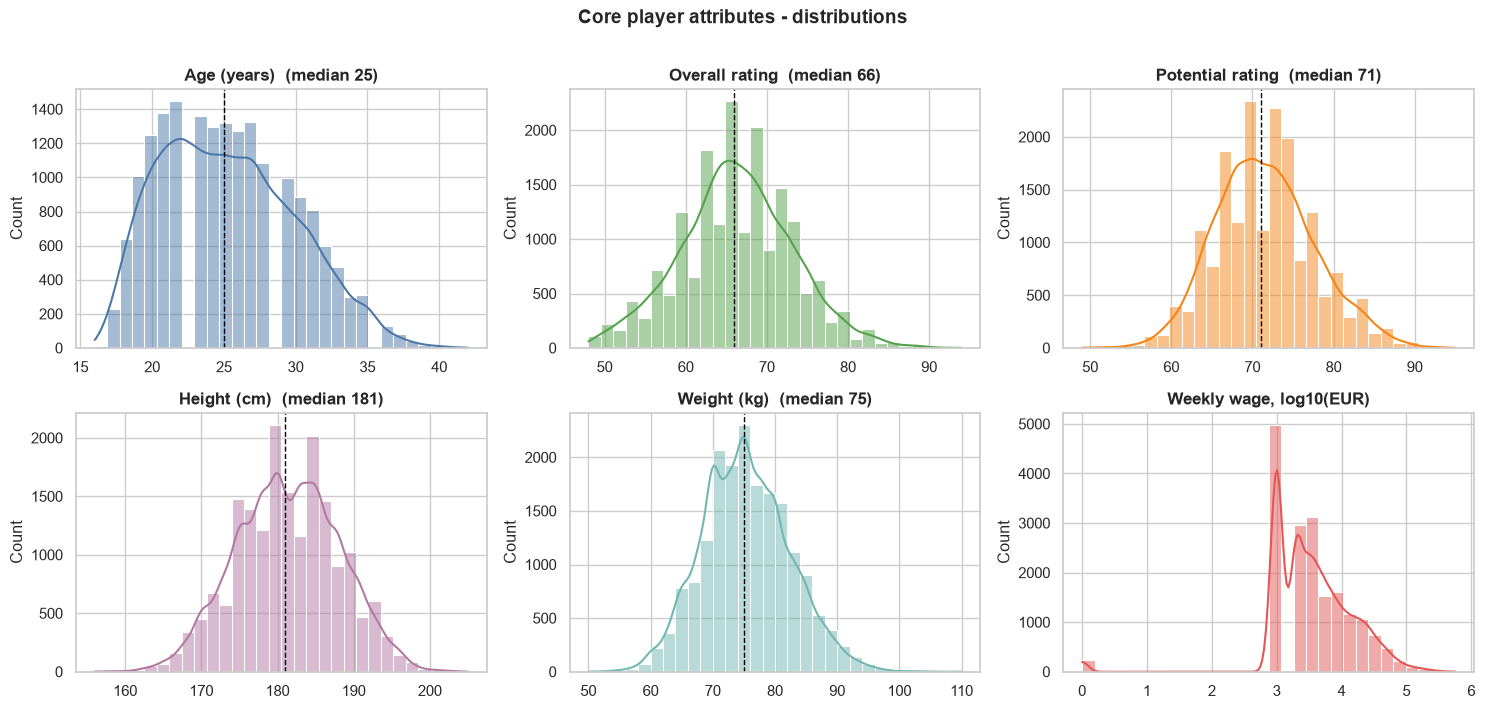

> **Insight - who is in the dataset**
>
> - Typical player: **25 years old**, overall **66.2** (sd 6.9); only **3.1%** are rated 80+ - elite players are rare.
> - Potential (mean 71.5) sits above overall (mean 66.2): the pool is young with headroom - this is the age effect analysed in §5.3.
> - Wages are extremely skewed: median **EUR 3,000** vs mean **EUR 9,457**; the top 1% of players earn **18%** of all wages -> use **medians / log scale** for money, and keep money out of the clustering.

In [47]:
POS_COLORS = {"GK": "#9D755D", "DEF": "#4C78A8", "MID": "#54A24B", "FWD": "#E45756"}

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
specs = [("age", "Age (years)", "#4C78A8"), ("overall", "Overall rating", "#54A24B"), ("potential", "Potential rating", "#F58518"),
         ("height_cm", "Height (cm)", "#B279A2"), ("weight_kg", "Weight (kg)", "#72B7B2")]
for ax, (c, lab, col) in zip(axes.flat, specs):
    sns.histplot(df[c], bins=30, kde=True, color=col, ax=ax)
    ax.axvline(df[c].median(), color="black", ls="--", lw=1)
    ax.set_title(f"{lab}  (median {df[c].median():.0f})"); ax.set_xlabel("")
sns.histplot(np.log10(df["wage_eur"].clip(lower=1)), bins=30, kde=True, color="#E45756", ax=axes.flat[5])
axes.flat[5].set_title("Weekly wage, log10(EUR)"); axes.flat[5].set_xlabel("")
plt.suptitle("Core player attributes - distributions", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

top1_share = df["wage_eur"].nlargest(int(0.01 * len(df))).sum() / df["wage_eur"].sum()
insight("Insight - who is in the dataset", [
    f"Typical player: **{df['age'].median():.0f} years old**, overall **{df['overall'].mean():.1f}** (sd {df['overall'].std():.1f}); only **{(df['overall'] >= 80).mean():.1%}** are rated 80+ - elite players are rare.",
    f"Potential (mean {df['potential'].mean():.1f}) sits above overall (mean {df['overall'].mean():.1f}): the pool is young with headroom - this is the age effect analysed in §5.3.",
    f"Wages are extremely skewed: median **EUR {df['wage_eur'].median():,.0f}** vs mean **EUR {df['wage_eur'].mean():,.0f}**; the top 1% of players earn **{top1_share:.0%}** of all wages -> use **medians / log scale** for money, and keep money out of the clustering.",
])

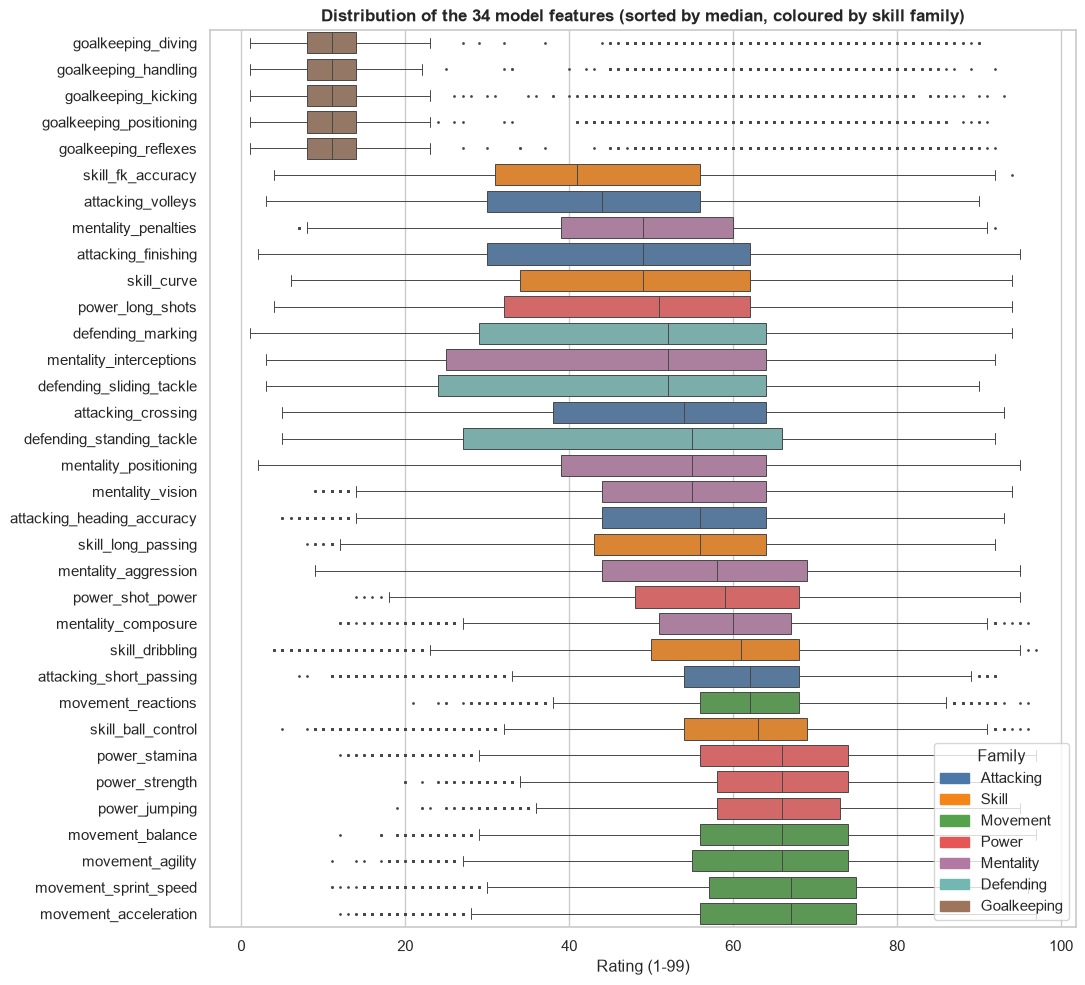

> **Insight - skill distributions**
>
> - The 29 non-goalkeeping skills have medians between **41 and 67**, while the **five goalkeeping skills have medians near 11** with a long upper tail.
> - That tail is not noise: goalkeepers are only **11.1%** of players but average **64** on these skills vs **10** for everyone else -> a **bimodal, role-driven** structure that clustering can exploit.
> - Every feature already shares the same 1-99 scale, but spreads differ (see §6.5), so scaling still matters for distance-based models.

In [48]:
# One chart instead of seven histogram grids: all 34 skills, sorted by median, coloured by family
order = df[FEATURES].median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 10))
sns.boxplot(data=df[order], orient="h", palette=[FAMILY_COLORS[FAMILY_OF[c]] for c in order],
            fliersize=1, linewidth=0.7, ax=ax)
ax.set_title("Distribution of the 34 model features (sorted by median, coloured by skill family)")
ax.set_xlabel("Rating (1-99)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLORS.values()],
          labels=FAMILY_COLORS.keys(), loc="lower right", title="Family")
plt.tight_layout(); plt.show()

gk_cols = [c for c in FEATURES if FAMILY_OF[c] == "Goalkeeping"]
is_gk = df["position_group"].eq("GK")
insight("Insight - skill distributions", [
    f"The 29 non-goalkeeping skills have medians between **{df[[c for c in FEATURES if c not in gk_cols]].median().min():.0f} and {df[[c for c in FEATURES if c not in gk_cols]].median().max():.0f}**, while the **five goalkeeping skills have medians near {df[gk_cols].median().mean():.0f}** with a long upper tail.",
    f"That tail is not noise: goalkeepers are only **{is_gk.mean():.1%}** of players but average **{df.loc[is_gk, gk_cols].mean().mean():.0f}** on these skills vs **{df.loc[~is_gk, gk_cols].mean().mean():.0f}** for everyone else -> a **bimodal, role-driven** structure that clustering can exploit.",
    "Every feature already shares the same 1-99 scale, but spreads differ (see §6.5), so scaling still matters for distance-based models.",
])

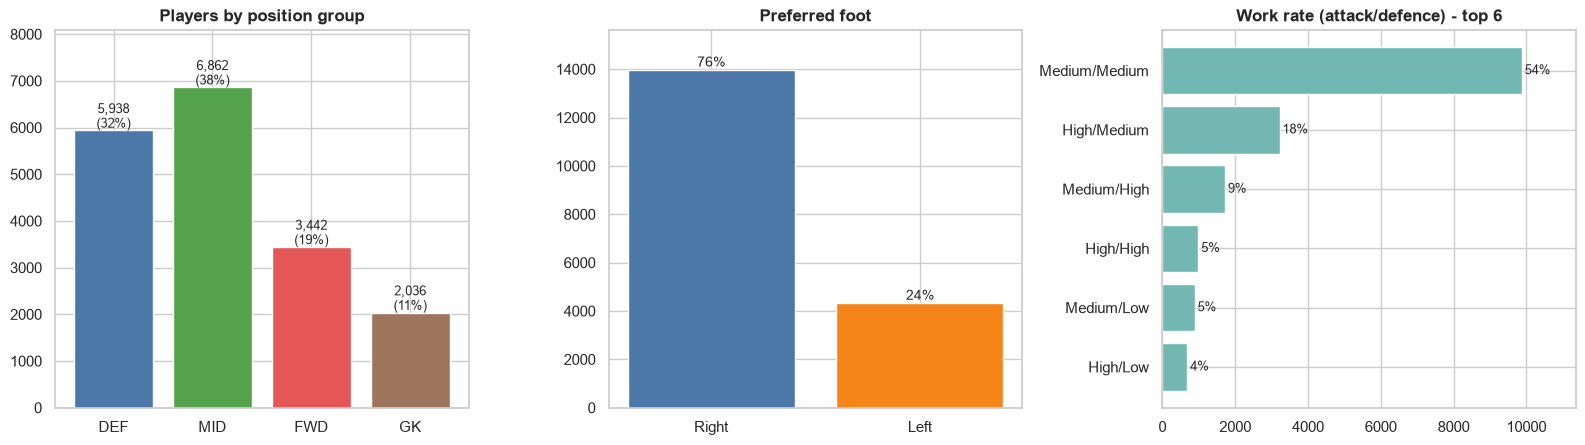

> **Insight - categorical profile**
>
> - Midfielders (38%) and defenders (32%) dominate; attackers are **19%** and goalkeepers **11%** - a real-world squad structure, so we will **not rebalance** before clustering (§6.7).
> - **76%** are right-footed; preferred foot carries no style information for this task.
> - 'Medium/Medium' work rate is the norm (**54%**) - work rate varies little, so it is kept only as a profiling variable.

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
pg_counts = df["position_group"].value_counts().reindex(["DEF", "MID", "FWD", "GK"])
axes[0].bar(pg_counts.index, pg_counts.values, color=[POS_COLORS[g] for g in pg_counts.index])
for i, v in enumerate(pg_counts.values): axes[0].text(i, v + 60, f"{v:,}\n({v/len(df):.0%})", ha="center", fontsize=9)
axes[0].set_title("Players by position group"); axes[0].set_ylim(0, pg_counts.max() * 1.18)

foot = df["preferred_foot"].value_counts()
axes[1].bar(foot.index, foot.values, color=["#4C78A8", "#F58518"])
for i, v in enumerate(foot.values): axes[1].text(i, v + 150, f"{v/len(df):.0%}", ha="center", fontsize=10)
axes[1].set_title("Preferred foot"); axes[1].set_ylim(0, foot.max() * 1.12)

wr = df["work_rate"].value_counts().head(6).sort_values()
axes[2].barh(wr.index, wr.values, color="#72B7B2")
for i, v in enumerate(wr.values): axes[2].text(v + 80, i, f"{v/len(df):.0%}", va="center", fontsize=9)
axes[2].set_title("Work rate (attack/defence) - top 6"); axes[2].set_xlim(0, wr.max() * 1.15)
plt.tight_layout(); plt.show()

insight("Insight - categorical profile", [
    f"Midfielders ({pg_counts['MID']/len(df):.0%}) and defenders ({pg_counts['DEF']/len(df):.0%}) dominate; attackers are **{pg_counts['FWD']/len(df):.0%}** and goalkeepers **{pg_counts['GK']/len(df):.0%}** - a real-world squad structure, so we will **not rebalance** before clustering (§6.7).",
    f"**{foot.iloc[0]/len(df):.0%}** are {foot.index[0].lower()}-footed; preferred foot carries no style information for this task.",
    f"'{wr.index[-1]}' work rate is the norm (**{wr.iloc[-1]/len(df):.0%}**) - work rate varies little, so it is kept only as a profiling variable.",
])

### 5.2 Business question (a) — Which countries produce the most players?

,country,players,share_pct,cumulative_pct
rank,,,,
1,England,"1,667",9.1%,9.1%
2,Germany,"1,216",6.7%,15.8%
3,Spain,"1,035",5.7%,21.4%
4,France,984,5.4%,26.8%
5,Argentina,886,4.8%,31.7%
6,Brazil,824,4.5%,36.2%
7,Italy,732,4.0%,40.2%
8,Colombia,591,3.2%,43.4%
9,Japan,453,2.5%,45.9%


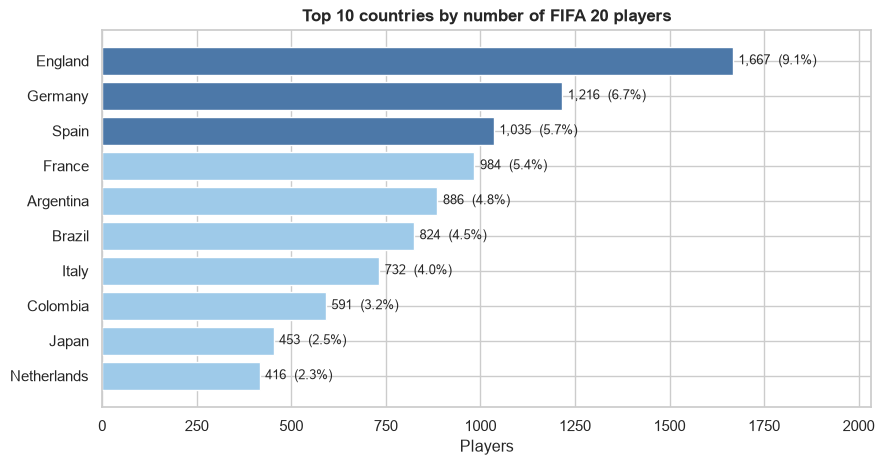

> **Answer (a) - top producing countries**
>
> - **England, Germany, Spain** lead with 1,667, 1,216, 1,035 players - together **21.4%** of the dataset.
> - The top 10 hold **48.2%** of all players, drawn from **162 nationalities** - a long tail of small football nations.
> - **6 of the top 10 are Western European**; South America adds Argentina, Brazil and Colombia; Japan is the only Asian entry.
> - Caveat: counts reflect the leagues FIFA licenses and rates, not just talent production.

In [50]:
country_counts = df["nationality"].value_counts()
top10 = (country_counts.head(10).rename_axis("country").reset_index(name="players")
         .assign(share_pct=lambda t: t["players"] / len(df) * 100, cumulative_pct=lambda t: t["players"].cumsum() / len(df) * 100))
top10.index = range(1, 11); top10.index.name = "rank"
display(top10.style.format({"players": "{:,}", "share_pct": "{:.1f}%", "cumulative_pct": "{:.1f}%"}))

fig, ax = plt.subplots(figsize=(9, 4.8))
colors = ["#4C78A8"] * 3 + ["#9ecae9"] * 7
ax.barh(top10["country"][::-1], top10["players"][::-1], color=colors[::-1])
for i, (v, p) in enumerate(zip(top10["players"][::-1], top10["share_pct"][::-1])):
    ax.text(v + 15, i, f"{v:,}  ({p:.1f}%)", va="center", fontsize=9)
ax.set_xlim(0, top10["players"].max() * 1.22); ax.set_title("Top 10 countries by number of FIFA 20 players"); ax.set_xlabel("Players")
plt.tight_layout(); plt.show()

W_EUROPE = {"England", "Germany", "Spain", "France", "Italy", "Netherlands"}
top3_share = top10["players"].head(3).sum() / len(df)
insight("Answer (a) - top producing countries", [
    f"**{', '.join(top10['country'].head(3))}** lead with {', '.join(f'{v:,}' for v in top10['players'].head(3))} players - together **{top3_share:.1%}** of the dataset.",
    f"The top 10 hold **{top10['cumulative_pct'].iloc[-1]:.1f}%** of all players, drawn from **{country_counts.size} nationalities** - a long tail of small football nations.",
    f"**{len(W_EUROPE & set(top10['country']))} of the top 10 are Western European**; South America adds Argentina, Brazil and Colombia; Japan is the only Asian entry.",
    "Caveat: counts reflect the leagues FIFA licenses and rates, not just talent production.",
])

### 5.3 Business question (b) — At what age do players stop improving?

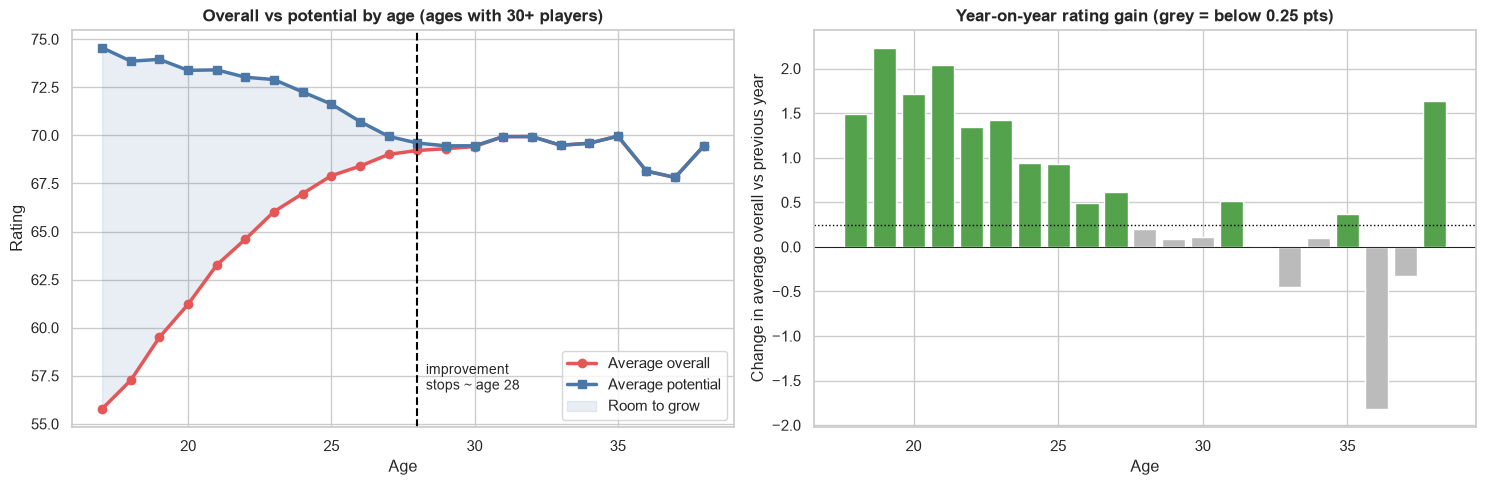

> **Answer (b) - when do players stop improving?**
>
> - Fastest growth is at **ages 18-21** (peak +2.2 points at age 19). Gains then halve (below +1.0 a year from age 24) and fall under **0.25 points a year at age 28**.
> - Between age 17 and 28 the average player gains **13.4 rating points** (55.8 -> 69.2).
> - The potential-overall gap closes from **18.8** points at 17 to **0.4** at 28: the game itself assumes growth ends by the late 20s.
> - The flat ~69-70 plateau from the late 20s to mid-30s is **partly survivorship**: this is a cross-section, and older players still on the list are those who stayed good.
> - Green bars after age 28 (ages 31, 35, 38) are sampling noise from shrinking groups (only 42 players at age 38), not renewed improvement.

In [51]:
age_stats = (df.groupby("age").agg(players=("overall", "size"), mean_overall=("overall", "mean"), mean_potential=("potential", "mean"))
               .query("players >= 30"))                                   # drop ages with too few players to average
age_stats["yearly_gain"] = age_stats["mean_overall"].diff()
STOP_THRESHOLD = 0.25                                                     # "stopped improving" = < 0.25 rating pts per year
stop_age = int(age_stats.loc[(age_stats.index > 21) & (age_stats["yearly_gain"] < STOP_THRESHOLD)].index.min())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.plot(age_stats.index, age_stats["mean_overall"], "o-", color="#E45756", lw=2.5, label="Average overall")
ax.plot(age_stats.index, age_stats["mean_potential"], "s-", color="#4C78A8", lw=2.5, label="Average potential")
ax.fill_between(age_stats.index, age_stats["mean_overall"], age_stats["mean_potential"], color="#4C78A8", alpha=0.12, label="Room to grow")
ax.axvline(stop_age, color="black", ls="--"); ax.text(stop_age + 0.3, age_stats["mean_overall"].min() + 1, f"improvement\nstops ~ age {stop_age}", fontsize=10)
ax.set_xlabel("Age"); ax.set_ylabel("Rating"); ax.set_title("Overall vs potential by age (ages with 30+ players)"); ax.legend(loc="lower right")

ax = axes[1]
gain = age_stats["yearly_gain"].dropna()
ax.bar(gain.index, gain.values, color=np.where(gain.values < STOP_THRESHOLD, "#bbbbbb", "#54A24B"))
ax.axhline(STOP_THRESHOLD, color="black", ls=":", lw=1); ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("Age"); ax.set_ylabel("Change in average overall vs previous year"); ax.set_title("Year-on-year rating gain (grey = below 0.25 pts)")
plt.tight_layout(); plt.show()

peak_gain_age = int(gain.idxmax())
gain_17_stop = age_stats.loc[stop_age, "mean_overall"] - age_stats.loc[age_stats.index.min(), "mean_overall"]
insight("Answer (b) - when do players stop improving?", [
    f"Fastest growth is at **ages 18-21** (peak +{gain.max():.1f} points at age {peak_gain_age}). Gains then halve (below +1.0 a year from age {int(gain[gain < 1.0].index.min())}) and fall under **{STOP_THRESHOLD} points a year at age {stop_age}**.",
    f"Between age {age_stats.index.min()} and {stop_age} the average player gains **{gain_17_stop:.1f} rating points** ({age_stats['mean_overall'].iloc[0]:.1f} -> {age_stats.loc[stop_age, 'mean_overall']:.1f}).",
    f"The potential-overall gap closes from **{(age_stats['mean_potential']-age_stats['mean_overall']).iloc[0]:.1f}** points at 17 to **{(age_stats['mean_potential']-age_stats['mean_overall']).loc[stop_age]:.1f}** at {stop_age}: the game itself assumes growth ends by the late 20s.",
    "The flat ~69-70 plateau from the late 20s to mid-30s is **partly survivorship**: this is a cross-section, and older players still on the list are those who stayed good.",
    f"Green bars after age {stop_age} (ages {', '.join(str(a) for a in gain[(gain.index > stop_age) & (gain >= STOP_THRESHOLD)].index)}) are sampling noise from shrinking groups (only {int(age_stats.loc[age_stats.index.max(), 'players'])} players at age {age_stats.index.max()}), not renewed improvement.",
])

### 5.4 Business question (c) — Do strikers, right wingers and left wingers earn differently?

,players,mean_wage,median_wage,max_wage,mean_overall
primary_position,,,,,
ST,"2,582","10,153","4,000","405,000",66.4
RW,369,"15,848","3,000","565,000",67.1
LW,378,"14,037","3,000","470,000",66.9


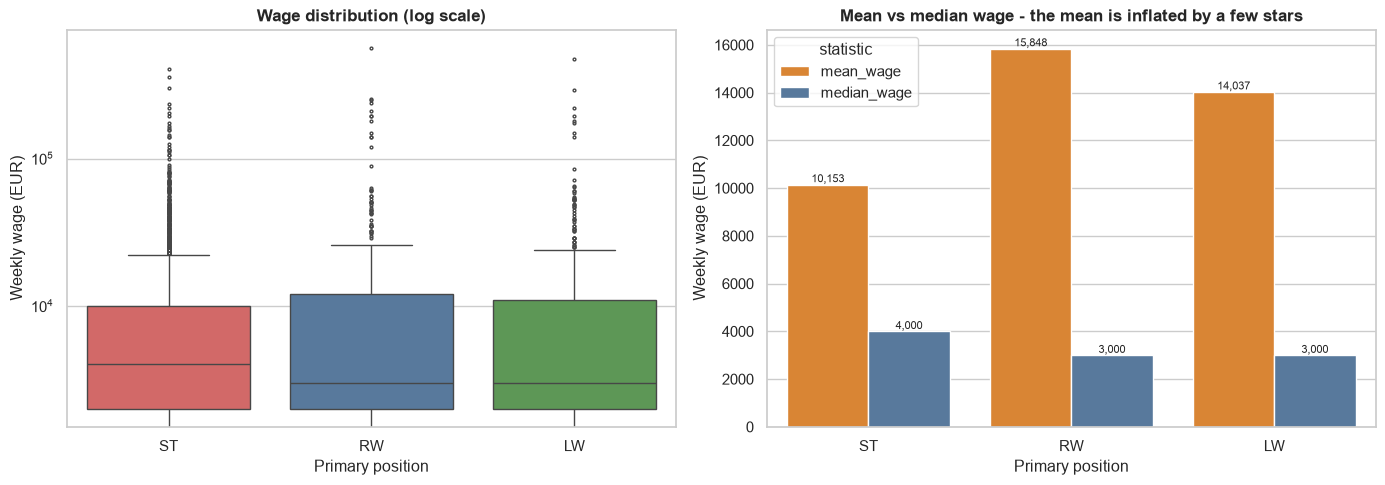

> **Answer (c) - ST vs RW vs LW wages**
>
> - On **averages**, RW earns most (EUR 15,848) and ST least (EUR 10,153); on **medians** the order flips - ST is highest (EUR 4,000 vs 3,000).
> - The three groups have almost the same quality (mean overall 66.4-67.1) and a **Kruskal-Wallis test finds no significant wage difference (p = 0.80)**; pairwise Bonferroni-adjusted p-values: ST vs RW 1.00, ST vs LW 1.00, RW vs LW 1.00.
> - Conclusion: the apparent RW/LW premium in the means is driven by a handful of superstars (max EUR 565,000); **position alone does not produce a statistically reliable pay difference**.

In [52]:
offensive = df[df["primary_position"].isin(["ST", "RW", "LW"])]
wage_tbl = (offensive.groupby("primary_position")
            .agg(players=("wage_eur", "size"), mean_wage=("wage_eur", "mean"), median_wage=("wage_eur", "median"),
                 max_wage=("wage_eur", "max"), mean_overall=("overall", "mean"))
            .loc[["ST", "RW", "LW"]])
display(wage_tbl.style.format({"players": "{:,}", "mean_wage": "{:,.0f}", "median_wage": "{:,.0f}", "max_wage": "{:,.0f}", "mean_overall": "{:.1f}"}))

# Wages are heavily skewed -> rank-based tests instead of comparing means
kw_stat, kw_p = stats.kruskal(*[g["wage_eur"].values for _, g in offensive.groupby("primary_position")])
pairs = [("ST", "RW"), ("ST", "LW"), ("RW", "LW")]
pair_p = {f"{a} vs {b}": min(1.0, 3 * stats.mannwhitneyu(offensive.loc[offensive.primary_position == a, "wage_eur"],
                                                          offensive.loc[offensive.primary_position == b, "wage_eur"]).pvalue)
          for a, b in pairs}                                              # Bonferroni-adjusted

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=offensive, x="primary_position", y="wage_eur", order=["ST", "RW", "LW"], palette=["#E45756", "#4C78A8", "#54A24B"], fliersize=2, ax=axes[0])
axes[0].set_yscale("log"); axes[0].set_title("Wage distribution (log scale)"); axes[0].set_xlabel("Primary position"); axes[0].set_ylabel("Weekly wage (EUR)")
plot_tbl = wage_tbl[["mean_wage", "median_wage"]].reset_index().melt(id_vars="primary_position", var_name="statistic", value_name="wage")
sns.barplot(data=plot_tbl, x="primary_position", y="wage", hue="statistic", palette=["#F58518", "#4C78A8"], ax=axes[1])
axes[1].set_title("Mean vs median wage - the mean is inflated by a few stars"); axes[1].set_xlabel("Primary position"); axes[1].set_ylabel("Weekly wage (EUR)")
for c in axes[1].containers: axes[1].bar_label(c, fmt="{:,.0f}", fontsize=8)
plt.tight_layout(); plt.show()

hi = wage_tbl["mean_wage"].idxmax()
insight("Answer (c) - ST vs RW vs LW wages", [
    f"On **averages**, {hi} earns most (EUR {wage_tbl.loc[hi, 'mean_wage']:,.0f}) and ST least (EUR {wage_tbl.loc['ST', 'mean_wage']:,.0f}); on **medians** the order flips - ST is highest (EUR {wage_tbl.loc['ST', 'median_wage']:,.0f} vs {wage_tbl.loc['RW', 'median_wage']:,.0f}).",
    f"The three groups have almost the same quality (mean overall {wage_tbl['mean_overall'].min():.1f}-{wage_tbl['mean_overall'].max():.1f}) and a **Kruskal-Wallis test finds no significant wage difference (p = {kw_p:.2f})**; pairwise Bonferroni-adjusted p-values: " + ", ".join(f"{k} {v:.2f}" for k, v in pair_p.items()) + ".",
    f"Conclusion: the apparent RW/LW premium in the means is driven by a handful of superstars (max EUR {wage_tbl['max_wage'].max():,.0f}); **position alone does not produce a statistically reliable pay difference**.",
])

### 5.5 Multivariate structure — what separates the players?

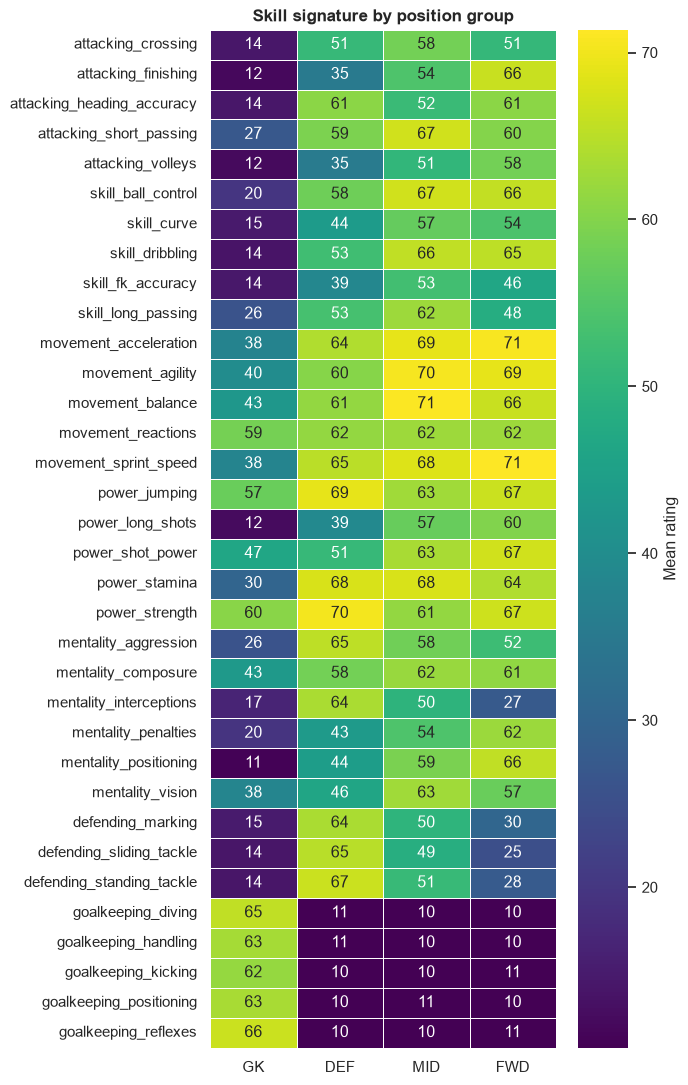

> **Insight - roles have distinct skill signatures**
>
> - **GK** - most distinctive: goalkeeping reflexes, goalkeeping diving, goalkeeping handling
> - **DEF** - most distinctive: defending sliding tackle, defending standing tackle, defending marking
> - **MID** - most distinctive: mentality vision, skill long passing, skill fk accuracy
> - **FWD** - most distinctive: attacking finishing, mentality penalties, attacking volleys
> - These signatures are what a clustering model should recover *without ever seeing the position label*.

In [53]:
sig = df.groupby("position_group")[FEATURES].mean().loc[["GK", "DEF", "MID", "FWD"]].T
sig = sig.loc[sorted(FEATURES, key=lambda c: (FAMILIES.index(FAMILY_OF[c]), c))]
fig, ax = plt.subplots(figsize=(6.8, 11))
sns.heatmap(sig, annot=True, fmt=".0f", cmap="viridis", linewidths=0.4, cbar_kws={"label": "Mean rating"}, ax=ax)
ax.set_title("Skill signature by position group"); ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout(); plt.show()

z = (sig.sub(df[FEATURES].mean(), axis=0)).div(df[FEATURES].std(), axis=0)          # how distinctive is each skill for each group
top_skills = {g: ", ".join(z[g].sort_values(ascending=False).head(3).index.str.replace("_", " ")) for g in z.columns}
insight("Insight - roles have distinct skill signatures", [f"**{g}** - most distinctive: {s}" for g, s in top_skills.items()] +
        ["These signatures are what a clustering model should recover *without ever seeing the position label*."])

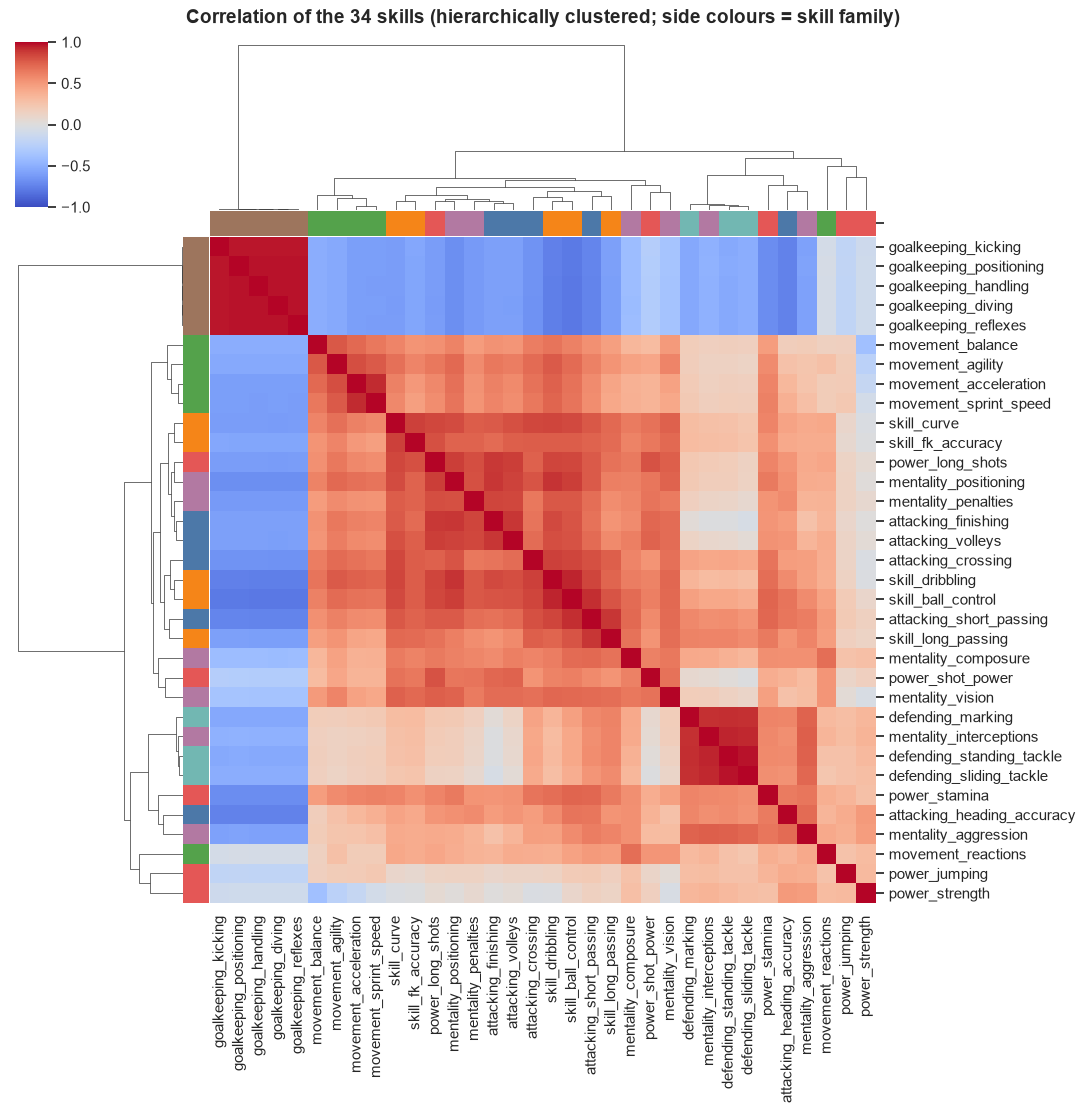

> **Insight - redundancy and blocks**
>
> - The five goalkeeping skills form a tight block (mean r = **0.97**) that is almost unrelated to the other 29 skills (mean |r| = **0.54**).
> - Skills are strongly related *within* a family - defending skills average r = **0.93**, attacking-vs-technical r = **0.73** - but only weakly *across* families (defending vs attacking r = **0.32**).
> - **49 of 561 feature pairs have |r| > 0.8** (strongest: defending_standing_tackle & defending_sliding_tackle, r = 0.98) - real redundancy, evaluated in §6.6.

In [54]:
corr = df[FEATURES].corr()
row_colors = pd.Series({c: FAMILY_COLORS[FAMILY_OF[c]] for c in FEATURES})
g = sns.clustermap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, figsize=(11, 11),
                   row_colors=row_colors, col_colors=row_colors, xticklabels=True, yticklabels=True,
                   cbar_pos=(0.02, 0.83, 0.03, 0.15))
g.fig.suptitle("Correlation of the 34 skills (hierarchically clustered; side colours = skill family)", y=1.01, fontweight="bold")
plt.show()

gk_block = corr.loc[gk_cols, gk_cols].values[np.triu_indices(len(gk_cols), 1)].mean()
gk_vs_rest = corr.loc[gk_cols, [c for c in FEATURES if c not in gk_cols]].abs().values.mean()
def blk(a, b):
    A = [c for c in FEATURES if FAMILY_OF[c] == a]; B = [c for c in FEATURES if FAMILY_OF[c] == b]
    m = corr.loc[A, B].values
    return m[np.triu_indices(len(A), 1)].mean() if a == b else m.mean()
upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
strong = upper[upper.abs() > 0.8].sort_values(ascending=False)
insight("Insight - redundancy and blocks", [
    f"The five goalkeeping skills form a tight block (mean r = **{gk_block:.2f}**) that is almost unrelated to the other 29 skills (mean |r| = **{gk_vs_rest:.2f}**).",
    f"Skills are strongly related *within* a family - defending skills average r = **{blk('Defending','Defending'):.2f}**, attacking-vs-technical r = **{blk('Attacking','Skill'):.2f}** - but only weakly *across* families (defending vs attacking r = **{blk('Defending','Attacking'):.2f}**).",
    f"**{len(strong)} of {len(upper)} feature pairs have |r| > 0.8** (strongest: {strong.index[0][0]} & {strong.index[0][1]}, r = {strong.iloc[0]:.2f}) - real redundancy, evaluated in §6.6.",
])

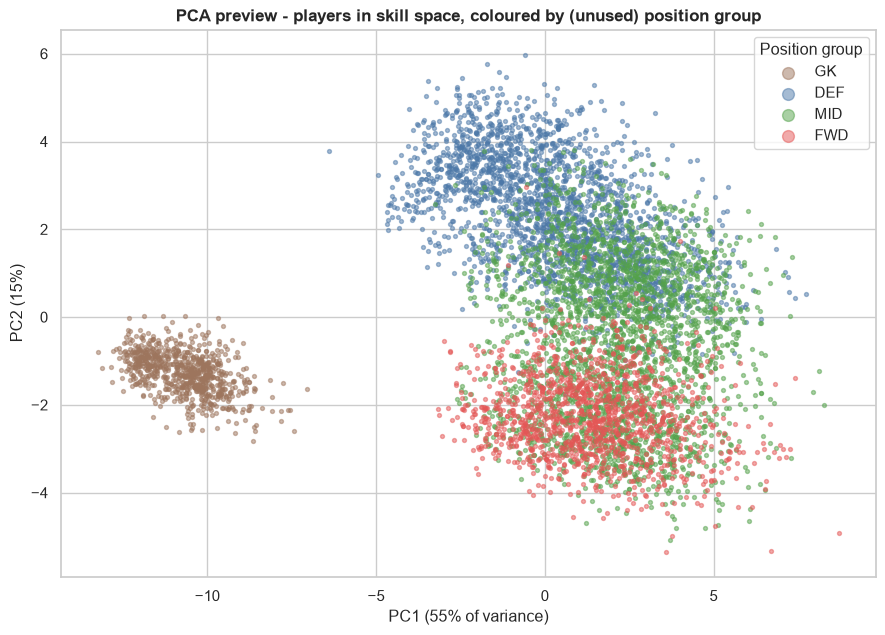

> **Insight - what clustering will (and will not) find**
>
> - Two components already capture **70%** of all skill variance.
> - **Goalkeepers form a separate island**; defenders, midfielders and attackers form one **continuous gradient** with soft overlaps (e.g. full-backs and wide midfielders).
> - Expect: a clean goalkeeper cluster plus outfield clusters with *fuzzy boundaries* -> moderate silhouette scores are normal here, and stability / external validity matter more than the silhouette alone.

In [55]:
X_eda = StandardScaler().fit_transform(df[FEATURES])
pca_eda = PCA(n_components=2, random_state=SEED).fit(X_eda)
pc = pca_eda.transform(X_eda)
samp = np.random.RandomState(SEED).choice(len(df), 7000, replace=False)

fig, ax = plt.subplots(figsize=(9, 6.5))
for grp_name, col in POS_COLORS.items():
    m = (df["position_group"].values[samp] == grp_name)
    ax.scatter(pc[samp][m, 0], pc[samp][m, 1], s=8, alpha=0.5, color=col, label=grp_name)
ax.set_xlabel(f"PC1 ({pca_eda.explained_variance_ratio_[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({pca_eda.explained_variance_ratio_[1]:.0%})")
ax.set_title("PCA preview - players in skill space, coloured by (unused) position group"); ax.legend(markerscale=3, title="Position group")
plt.tight_layout(); plt.show()

insight("Insight - what clustering will (and will not) find", [
    f"Two components already capture **{pca_eda.explained_variance_ratio_.sum():.0%}** of all skill variance.",
    "**Goalkeepers form a separate island**; defenders, midfielders and attackers form one **continuous gradient** with soft overlaps (e.g. full-backs and wide midfielders).",
    "Expect: a clean goalkeeper cluster plus outfield clusters with *fuzzy boundaries* -> moderate silhouette scores are normal here, and stability / external validity matter more than the silhouette alone.",
])

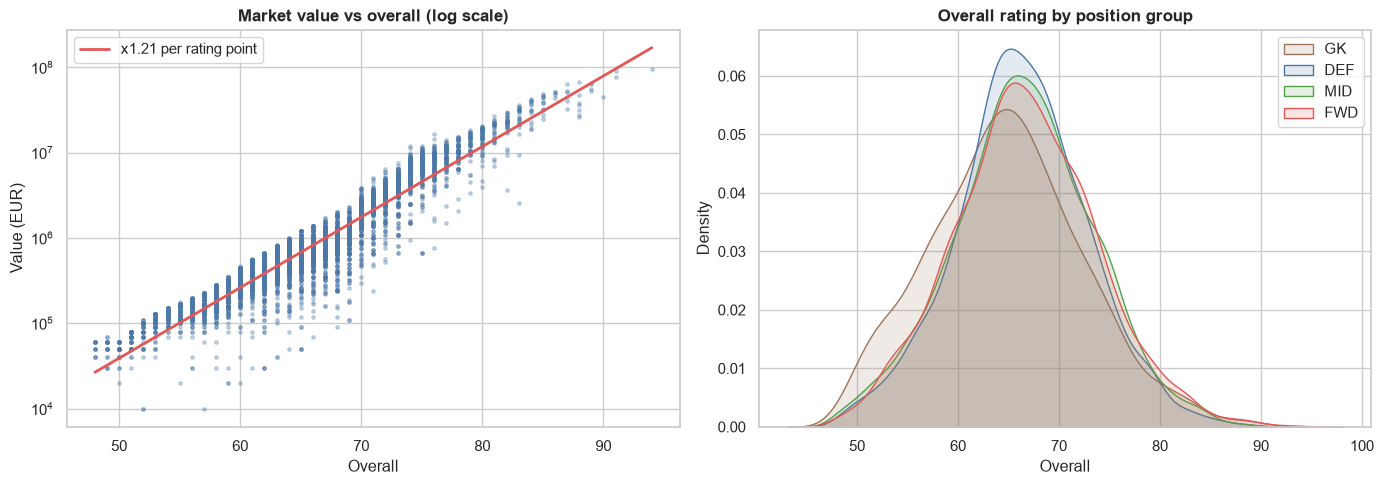

> **Insight - quality and price are not style**
>
> - Market value grows about **x1.21 for every extra rating point** (log-linear), so stars are priced exponentially - one more reason to keep money out of the model.
> - Median overall is similar across position groups (65-66): **quality does not identify role**, so clustering on skills - not ratings - is the right lens for style.
> - 250 players have a listed value of 0 (excluded from this fit).

In [56]:
pos = df[df["value_eur"] > 0]
slope, intercept = np.polyfit(pos["overall"], np.log10(pos["value_eur"]), 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
s2 = pos.sample(6000, random_state=SEED)
axes[0].scatter(s2["overall"], s2["value_eur"], s=6, alpha=0.3, color="#4C78A8"); axes[0].set_yscale("log")
axes[0].plot(np.sort(s2["overall"]), 10 ** (intercept + slope * np.sort(s2["overall"])), color="#E45756", lw=2, label=f"x{10**slope:.2f} per rating point")
axes[0].set_title("Market value vs overall (log scale)"); axes[0].set_xlabel("Overall"); axes[0].set_ylabel("Value (EUR)"); axes[0].legend()
for grp_name, col in POS_COLORS.items():
    sns.kdeplot(df.loc[df["position_group"] == grp_name, "overall"], ax=axes[1], color=col, label=grp_name, fill=True, alpha=0.15)
axes[1].set_title("Overall rating by position group"); axes[1].set_xlabel("Overall"); axes[1].legend()
plt.tight_layout(); plt.show()

med_by_grp = df.groupby("position_group")["overall"].median()
insight("Insight - quality and price are not style", [
    f"Market value grows about **x{10**slope:.2f} for every extra rating point** (log-linear), so stars are priced exponentially - one more reason to keep money out of the model.",
    f"Median overall is similar across position groups ({med_by_grp.min():.0f}-{med_by_grp.max():.0f}): **quality does not identify role**, so clustering on skills - not ratings - is the right lens for style.",
    f"{int((df['value_eur'] == 0).sum())} players have a listed value of 0 (excluded from this fit).",
])

### 5.6 EDA Key Findings — one-glance summary

In [57]:
key_findings = pd.DataFrame([
    ("Data quality",        f"{len(df):,} unique players, 0 duplicates; 34 skill features fully populated",                       "Ready to model without dropping or imputing model inputs"),
    ("Role structure",      f"Goalkeepers ({is_gk.mean():.0%}) are an isolated island in skill space; outfield roles form a continuum", "Expect a clean GK cluster + fuzzy outfield clusters"),
    ("Redundancy",          f"{len(strong)} feature pairs have |r| > 0.8; skills come in blocks (GK, technical, defending)",       "Scale features; test whether pruning redundancy matters (§6.6)"),
    ("Money is skewed",     f"Top 1% of players earn {top1_share:.0%} of wages; value grows x{10**slope:.2f} per rating point",   "Keep value/wage out of the model; use medians for reporting"),
    ("(a) Top countries",   f"{', '.join(top10['country'].head(3))} = {top3_share:.1%} of players; top 10 = {top10['cumulative_pct'].iloc[-1]:.1f}%", "Western Europe + South America dominate the pool"),
    ("(b) Age vs rating",   f"Fast growth at 18-21; gains < {STOP_THRESHOLD} pts/yr from age {stop_age}",                          "Scout under-24s for growth; 28+ are 'what you see is what you get'"),
    ("(c) ST/RW/LW wages",  f"Mean RW > LW > ST but medians reverse; Kruskal-Wallis p = {kw_p:.2f}",                               "No reliable position pay gap - do not overpay for a 'wide' label"),
], columns=["Theme", "Finding (computed)", "Implication for the project"])
display(key_findings.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Theme,Finding (computed),Implication for the project
Data quality,"18,278 unique players, 0 duplicates; 34 skill features fully populated",Ready to model without dropping or imputing model inputs
Role structure,Goalkeepers (11%) are an isolated island in skill space; outfield roles form a continuum,Expect a clean GK cluster + fuzzy outfield clusters
Redundancy,"49 feature pairs have |r| > 0.8; skills come in blocks (GK, technical, defending)",Scale features; test whether pruning redundancy matters (§6.6)
Money is skewed,Top 1% of players earn 18% of wages; value grows x1.21 per rating point,Keep value/wage out of the model; use medians for reporting
(a) Top countries,"England, Germany, Spain = 21.4% of players; top 10 = 48.2%",Western Europe + South America dominate the pool
(b) Age vs rating,Fast growth at 18-21; gains < 0.25 pts/yr from age 28,Scout under-24s for growth; 28+ are 'what you see is what you get'
(c) ST/RW/LW wages,Mean RW > LW > ST but medians reverse; Kruskal-Wallis p = 0.80,No reliable position pay gap - do not overpay for a 'wide' label


## 6. Data Preprocessing & Feature Engineering

Every step below follows the same pattern: **evidence → decision → proof that the decision is safe** (the proof is the sensitivity table in §6.8).

### 6.1 Missing values — audit by *cause*, then decide

,columns,avg_null_pct,examples
cause,,,
Structural: undefined for goalkeepers,32,11.1%,"pace, shooting, passing, dribbling"
Sparse metadata (not a skill),10,45.0%,"loaned_from, nation_position, nation_jersey_number, player_tags"
Structural: undefined for outfield players,6,88.9%,"gk_diving, gk_handling, gk_kicking, gk_reflexes"


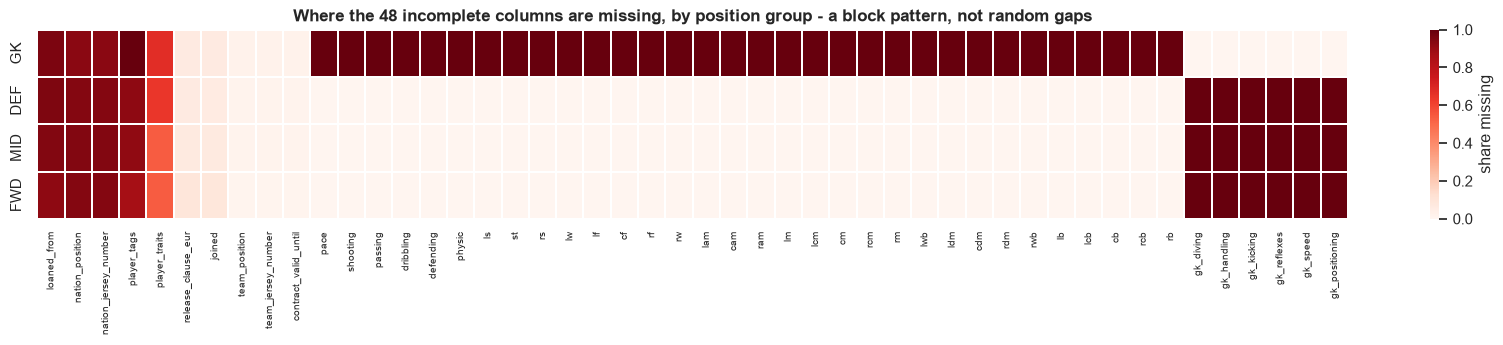

In [58]:
gk_mask = df["position_group"].eq("GK").values
null_cols = df.columns[df.isna().any()]
audit = []
for c in null_cols:
    nulls = df[c].isna()
    gk_rate, out_rate = nulls[gk_mask].mean(), nulls[~gk_mask].mean()
    if gk_rate == 1 and out_rate == 0:   cause = "Structural: undefined for goalkeepers"
    elif gk_rate == 0 and out_rate == 1: cause = "Structural: undefined for outfield players"
    else:                                cause = "Sparse metadata (not a skill)"
    audit.append({"column": c, "null_pct": nulls.mean() * 100, "null_% among GK": gk_rate * 100, "null_% among outfield": out_rate * 100, "cause": cause})
audit = pd.DataFrame(audit).sort_values(["cause", "null_pct"], ascending=[True, False])

cause_summary = (audit.groupby("cause").agg(columns=("column", "count"), avg_null_pct=("null_pct", "mean"),
                                            examples=("column", lambda s: ", ".join(s.head(4))))
                      .sort_values("columns", ascending=False))
display(cause_summary.style.format({"avg_null_pct": "{:.1f}%"}).set_properties(subset=["examples"], **{"text-align": "left"}))

rate_by_group = df[audit["column"]].isna().groupby(df["position_group"]).mean().loc[["GK", "DEF", "MID", "FWD"]]
fig, ax = plt.subplots(figsize=(17, 3.6))
sns.heatmap(rate_by_group, cmap="Reds", vmin=0, vmax=1, linewidths=0.3, cbar_kws={"label": "share missing"}, ax=ax)
ax.set_title(f"Where the {len(audit)} incomplete columns are missing, by position group - a block pattern, not random gaps")
ax.set_xlabel(""); ax.set_ylabel(""); plt.xticks(rotation=90, fontsize=7)
plt.tight_layout(); plt.show()

In [59]:
gk_df = df[gk_mask]
dup_share = np.mean([(gk_df[f"gk_{s}"] == gk_df[f"goalkeeping_{s}"]).mean() for s in ["diving", "handling", "kicking", "positioning", "reflexes"]])
naive_pace_fill = df.loc[~gk_mask, "pace"].median()
gk_true_speed   = gk_df["movement_sprint_speed"].mean()

insight("Evidence - the missingness is structural, not random", [
    f"**{(cause_summary.index.str.startswith('Structural')).sum()} kinds of structural gaps**: {int(cause_summary.loc[cause_summary.index.str.startswith('Structural'), 'columns'].sum())} columns are missing for **100% of one role and 0% of the other** (pace, shooting, position ratings are undefined for goalkeepers; gk_* are undefined for outfield players). No column shows a partial pattern that would suggest random loss.",
    f"**The 34 model features have {int(df[FEATURES].isna().sum().sum())} missing values** - the model never touches an incomplete column.",
    f"`gk_*` columns are exact duplicates of `goalkeeping_*` for goalkeepers ({dup_share:.0%} identical), so nothing is lost by using the complete `goalkeeping_*` versions.",
    f"Why not simply impute the composite columns? Median-filling `pace` would give **every goalkeeper a pace of {naive_pace_fill:.0f}** (the outfield median) although goalkeepers' own sprint speed averages **{gk_true_speed:.0f}**: imputation would *invent* skills and blur the very role boundary we want to find.",
])

> **Evidence - the missingness is structural, not random**
>
> - **2 kinds of structural gaps**: 38 columns are missing for **100% of one role and 0% of the other** (pace, shooting, position ratings are undefined for goalkeepers; gk_* are undefined for outfield players). No column shows a partial pattern that would suggest random loss.
> - **The 34 model features have 0 missing values** - the model never touches an incomplete column.
> - `gk_*` columns are exact duplicates of `goalkeeping_*` for goalkeepers (100% identical), so nothing is lost by using the complete `goalkeeping_*` versions.
> - Why not simply impute the composite columns? Median-filling `pace` would give **every goalkeeper a pace of 69** (the outfield median) although goalkeepers' own sprint speed averages **38**: imputation would *invent* skills and blur the very role boundary we want to find.

**Decision — missing values**

| Column group | Action | Reason |
|---|---|---|
| 34 skill features (model input) | **None needed** — 0% missing | Complete by construction |
| Composite ratings, position-suitability ratings, `gk_*` | **Excluded from the model** rather than imputed | Redundant with the 34 base skills and structurally undefined for one role; imputing them would fabricate values |
| Sparse metadata (tags, loan club, national-team info…) | **Excluded** | Not skills; mostly sparse |
| Production safeguard | A **median `SimpleImputer` stays inside the deployed pipeline** | New data may contain gaps. Median (not mean) is chosen because ratings are bounded and skewed by role-specific extremes; §6.8 shows 5% random gaps barely move the clusters |

### 6.2 Duplicates

In [60]:
print(f"Fully duplicated rows : {df.duplicated().sum()}")
print(f"Duplicated sofifa_id  : {df['sofifa_id'].duplicated().sum()}   ->  every row is a distinct player; nothing to remove.")

Fully duplicated rows : 0
Duplicated sofifa_id  : 0   ->  every row is a distinct player; nothing to remove.


### 6.3 Outliers — are extreme values errors, or role-specific expertise?

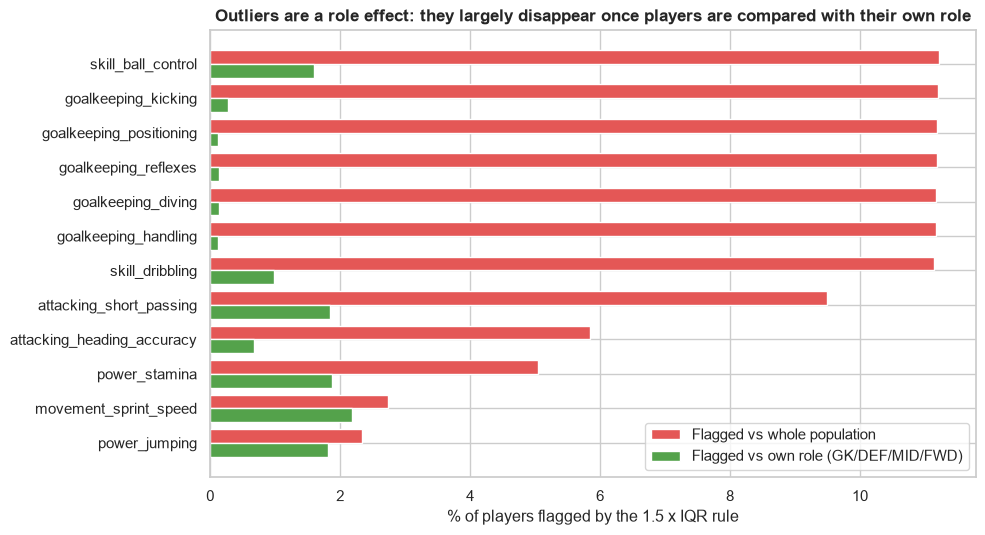

> **Evidence - extreme values are genuine specialists, not errors**
>
> - All 34 features stay inside the valid 1-99 range (1 to 97) - no impossible or corrupted values.
> - Against the whole population **10 features** have more than 5% flagged outliers (including all five goalkeeping skills at ~11%); compared with players of the same role only **0** do (mean flag rate falls from 3.3% to 0.8%).
> - **100%** of the players flagged on goalkeeping skills are goalkeepers - an 85 in diving is 'extreme' for a striker but ordinary for a keeper.

In [61]:
def iqr_outlier_rate(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()

groups_order = ["GK", "DEF", "MID", "FWD"]
group_share = df["position_group"].value_counts(normalize=True).reindex(groups_order)
global_rate = df[FEATURES].apply(iqr_outlier_rate)
role_rate = pd.DataFrame({g: df.loc[df["position_group"] == g, FEATURES].apply(iqr_outlier_rate) for g in groups_order})
within_role_rate = role_rate.mul(group_share, axis=1).sum(axis=1)             # weighted average of within-role rates
cmp_out = pd.DataFrame({"Whole population": global_rate, "Within own role": within_role_rate}).sort_values("Whole population", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5.5))
top12 = cmp_out.head(12)[::-1] * 100
y = np.arange(len(top12))
ax.barh(y + 0.2, top12["Whole population"], height=0.4, color="#E45756", label="Flagged vs whole population")
ax.barh(y - 0.2, top12["Within own role"], height=0.4, color="#54A24B", label="Flagged vs own role (GK/DEF/MID/FWD)")
ax.set_yticks(y); ax.set_yticklabels(top12.index); ax.set_xlabel("% of players flagged by the 1.5 x IQR rule")
ax.set_title("Outliers are a role effect: they largely disappear once players are compared with their own role"); ax.legend()
plt.tight_layout(); plt.show()

gk_flag_share = np.mean([df.loc[(df[c] < df[c].quantile(.25) - 1.5*(df[c].quantile(.75)-df[c].quantile(.25))) |
                                (df[c] > df[c].quantile(.75) + 1.5*(df[c].quantile(.75)-df[c].quantile(.25))), "position_group"].eq("GK").mean() for c in gk_cols])
insight("Evidence - extreme values are genuine specialists, not errors", [
    f"All 34 features stay inside the valid 1-99 range ({feat_min:.0f} to {feat_max:.0f}) - no impossible or corrupted values.",
    f"Against the whole population **{int((global_rate > 0.05).sum())} features** have more than 5% flagged outliers (including all five goalkeeping skills at ~{global_rate[gk_cols].mean():.0%}); compared with players of the same role only **{int((within_role_rate > 0.05).sum())}** do (mean flag rate falls from {global_rate.mean():.1%} to {within_role_rate.mean():.1%}).",
    f"**{gk_flag_share:.0%}** of the players flagged on goalkeeping skills are goalkeepers - an 85 in diving is 'extreme' for a striker but ordinary for a keeper.",
])

**Decision — outliers: keep them, do not cap.** Capping would flatten the elite and specialist profiles (e.g. a world-class finisher) that scouts care about, and it would distort the goalkeeper/outfield contrast. §6.8 verifies that capping at the 1st/99th percentile would change almost no player's cluster, so leaving the data untouched costs nothing.

### 6.4 Encoding
The 34 model inputs are already numeric ratings, so **no encoding is needed**. Text columns (`nationality`, `club`, positions…) are used only for profiling and validation; `position_group` is a derived *label* that never enters the model.

### 6.5 Scaling

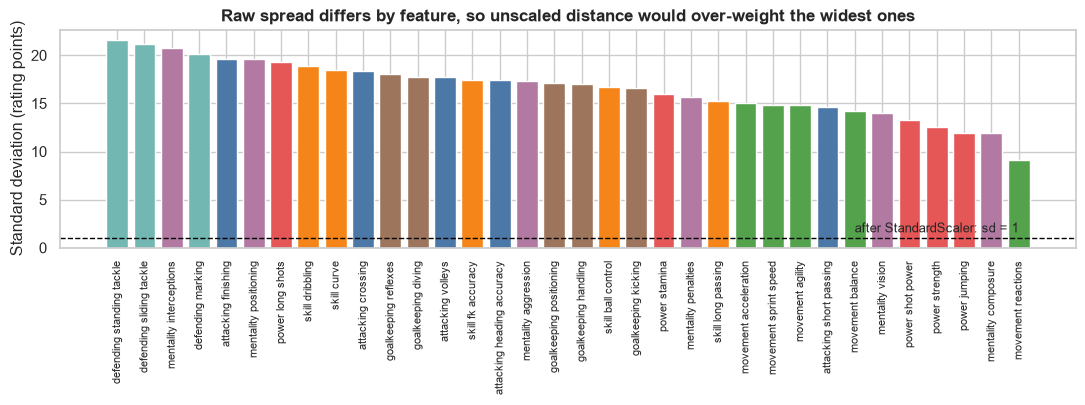

> **Evidence**
>
> - Raw standard deviations range from **9.1 to 21.6** rating points; the five widest features would carry **22%** of the squared-distance budget (a fair share would be 15%).
> - K-Means, GMM, Ward, BIRCH, Spectral and DBSCAN are all distance/variance based -> **StandardScaler** (mean 0, sd 1) gives every skill an equal vote. The scaler is fitted inside the production pipeline so new players are scaled identically.

In [62]:
raw_std = df[FEATURES].std().sort_values(ascending=False)
top5_var_share = (raw_std.head(5) ** 2).sum() / (raw_std ** 2).sum()

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(range(len(raw_std)), raw_std.values, color=[FAMILY_COLORS[FAMILY_OF[c]] for c in raw_std.index])
ax.set_xticks(range(len(raw_std))); ax.set_xticklabels([c.replace("_", " ") for c in raw_std.index], rotation=90, fontsize=8)
ax.axhline(1, color="black", ls="--", lw=1); ax.text(len(raw_std) - 1, 1.6, "after StandardScaler: sd = 1", ha="right", fontsize=9)
ax.set_ylabel("Standard deviation (rating points)"); ax.set_title("Raw spread differs by feature, so unscaled distance would over-weight the widest ones")
plt.tight_layout(); plt.show()

insight("Evidence", [
    f"Raw standard deviations range from **{raw_std.min():.1f} to {raw_std.max():.1f}** rating points; the five widest features would carry **{top5_var_share:.0%}** of the squared-distance budget (a fair share would be {5/34:.0%}).",
    "K-Means, GMM, Ward, BIRCH, Spectral and DBSCAN are all distance/variance based -> **StandardScaler** (mean 0, sd 1) gives every skill an equal vote. The scaler is fitted inside the production pipeline so new players are scaled identically.",
])

### 6.6 Feature selection — keep all 34, or prune redundant skills?

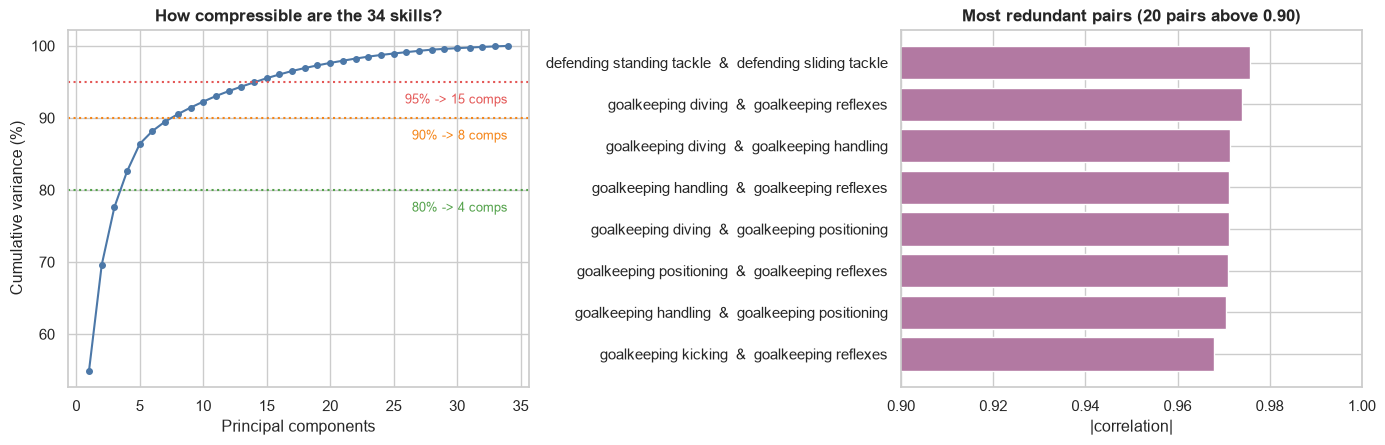

> **Evidence**
>
> - 4 components explain 80% and 8 explain 90% of the variance: strong redundancy exists, mostly *within* a family (e.g. the five goalkeeping skills, the three defending skills).
> - A greedy prune of the |r| > 0.90 pairs would leave **24 of 34 features** - tested as a variant in §6.8.

In [63]:
pca_full = PCA(random_state=SEED).fit(StandardScaler().fit_transform(df[FEATURES]))
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n80, n90, n95 = [int(np.searchsorted(cum_var, q)) + 1 for q in (0.80, 0.90, 0.95)]

upper_corr = corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
redundant_pairs = upper_corr[upper_corr > 0.90].sort_values(ascending=False)
FEATURES_PRUNED = list(FEATURES)                       # greedy: drop the member of each |r|>0.9 pair that is most correlated with everything else
for (a, b) in redundant_pairs.index:
    if a in FEATURES_PRUNED and b in FEATURES_PRUNED:
        FEATURES_PRUNED.remove(a if corr[a].abs().mean() > corr[b].abs().mean() else b)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].plot(range(1, 35), cum_var * 100, "o-", color="#4C78A8", ms=4)
for q, n_, col in ((80, n80, "#54A24B"), (90, n90, "#F58518"), (95, n95, "#E45756")):
    axes[0].axhline(q, color=col, ls=":"); axes[0].text(34, q - 3, f"{q}% -> {n_} comps", ha="right", color=col, fontsize=9)
axes[0].set_xlabel("Principal components"); axes[0].set_ylabel("Cumulative variance (%)"); axes[0].set_title("How compressible are the 34 skills?")
show_pairs = redundant_pairs.head(8)[::-1]
axes[1].barh([f"{a.replace('_',' ')}  &  {b.replace('_',' ')}" for a, b in show_pairs.index], show_pairs.values, color="#B279A2")
axes[1].set_xlim(0.9, 1.0); axes[1].set_xlabel("|correlation|"); axes[1].set_title(f"Most redundant pairs ({len(redundant_pairs)} pairs above 0.90)")
plt.tight_layout(); plt.show()

insight("Evidence", [
    f"{n80} components explain 80% and {n90} explain 90% of the variance: strong redundancy exists, mostly *within* a family (e.g. the five goalkeeping skills, the three defending skills).",
    f"A greedy prune of the |r| > 0.90 pairs would leave **{len(FEATURES_PRUNED)} of 34 features** - tested as a variant in §6.8.",
])

**Decision — keep all 34 skills.** Redundancy is not just noise: the correlated skills of a family act as an *implicit weight* on that family (five goalkeeping and three defending skills make those roles count for more). Pruning to 24 features changes the clusters substantially and, as §6.8 shows, **lowers agreement with real playing positions** — so the full, named skill set is retained. It also lets every cluster centroid be read in football terms (*"avg. finishing 78"*), which is the purpose of the project. PCA is used only for **visualisation** and for the density-based models in §7.

### 6.7 Class balancing and train/test split — deliberately not used
Balancing exists for supervised targets; there is no target here, and the real-world role imbalance (e.g. 11% goalkeepers) *is* the signal. A supervised-style train/test split is also not meaningful for clustering, because there are no labels to generalise to. **Generalisation is instead tested by resampling stability (§8, §10.1) and by agreement with real positions (§10.3).**

### 6.8 Do these preprocessing choices matter? — a sensitivity analysis
*For each alternative, K-Means is re-run for k = 3…6 and compared with the baseline pipeline (median-impute → StandardScaler, raw outliers, all 34 features). **ARI = 1.0** means identical clusters; ARI ≥ 0.9 is treated as "the choice does not matter". `NMI vs position` shows whether the alternative recovers real roles better or worse.*

In [64]:
# ---- Production preprocessing pipeline (used for everything from here on) -------------------------------
prep = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
X = prep.fit_transform(df[FEATURES])                 # 18,278 x 34, mean 0 / sd 1
pg  = df["position_group"].to_numpy(dtype=object)     # external labels as a plain ndarray (avoids StringArray 2-D compare bugs) - used ONLY for validation
out_mask = ~gk_mask                                   # outfield players
assert X.shape == (len(df), 34) and not np.isnan(X).any()

def km_labels(Xm, k):
    return KMeans(k, init="k-means++", n_init=10, random_state=SEED).fit_predict(Xm)

KS_SENS = [3, 4, 5, 6]
base = {k: km_labels(X, k) for k in KS_SENS}

rng = np.random.RandomState(SEED)
raw = df[FEATURES].astype(float)
variants = {}
lo, hi = raw.quantile(0.01), raw.quantile(0.99)
variants["Cap outliers at 1st/99th percentile"]           = StandardScaler().fit_transform(raw.clip(lo, hi, axis=1))
variants["RobustScaler (median / IQR) instead of Standard"] = RobustScaler().fit_transform(raw)
variants["MinMaxScaler instead of Standard"]               = MinMaxScaler().fit_transform(raw)
holes = raw.mask(rng.rand(*raw.shape) < 0.05)                                   # 5% random missing values
variants["5% random missing values + median imputation"]   = prep.fit_transform(holes)
prep.fit(df[FEATURES])                                                          # restore the fitted production pipeline
variants["Drop redundant features (|r| > 0.9)"]            = StandardScaler().fit_transform(raw[FEATURES_PRUNED])
variants["No scaling at all (raw ratings)"]                = raw.values

rows = []
rows.append({"Alternative": "BASELINE (this notebook)", **{f"ARI k={k}": 1.0 for k in KS_SENS}, "Mean ARI": 1.0,
             "Mean NMI vs position": np.mean([normalized_mutual_info_score(pg, base[k]) for k in KS_SENS])})
for name, Xv in variants.items():
    lab = {k: km_labels(Xv, k) for k in KS_SENS}
    ari = {k: adjusted_rand_score(base[k], lab[k]) for k in KS_SENS}
    rows.append({"Alternative": name, **{f"ARI k={k}": ari[k] for k in KS_SENS}, "Mean ARI": np.mean(list(ari.values())),
                 "Mean NMI vs position": np.mean([normalized_mutual_info_score(pg, lab[k]) for k in KS_SENS])})
sens = pd.DataFrame(rows).set_index("Alternative")
display(sens.style.format("{:.3f}").background_gradient(subset=["Mean ARI"], cmap="RdYlGn", vmin=0.5, vmax=1.0))

,ARI k=3,ARI k=4,ARI k=5,ARI k=6,Mean ARI,Mean NMI vs position
Alternative,,,,,,
BASELINE (this notebook),1.000,1.000,1.000,1.000,1.000,0.476
Cap outliers at 1st/99th percentile,0.993,0.995,0.993,0.982,0.991,0.475
RobustScaler (median / IQR) instead of Standard,0.738,0.694,0.561,0.582,0.644,0.406
MinMaxScaler instead of Standard,0.386,0.770,0.885,0.661,0.676,0.528
5% random missing values + median imputation,0.964,0.950,0.947,0.927,0.947,0.474
Drop redundant features (|r| > 0.9),0.738,0.660,0.587,0.533,0.630,0.427
No scaling at all (raw ratings),0.390,0.756,0.865,0.789,0.700,0.530


In [65]:
safe = sens.drop("BASELINE (this notebook)")
b_nmi = sens.loc["BASELINE (this notebook)", "Mean NMI vs position"]
unchanged = safe["Mean ARI"] >= 0.9
insight("Reading the sensitivity table", [
    f"**Immaterial choices (mean ARI >= 0.9):** " + "; ".join(f"{i} ({v:.2f})" for i, v in safe["Mean ARI"][unchanged].items()) + ". -> Keeping outliers and using a median imputer as a safeguard costs nothing.",
    f"**Material choices (ARI {safe['Mean ARI'][~unchanged].min():.2f}-{safe['Mean ARI'][~unchanged].max():.2f}):** pruning, RobustScaler, MinMaxScaler and no scaling all move the boundaries between neighbouring *outfield* roles (the goalkeeper cluster is unaffected).",
    f"**Pruning and RobustScaler are rejected** - they also *reduce* agreement with real positions (NMI {sens.loc['Drop redundant features (|r| > 0.9)', 'Mean NMI vs position']:.3f} and {sens.loc['RobustScaler (median / IQR) instead of Standard', 'Mean NMI vs position']:.3f} vs {b_nmi:.3f}).",
    f"**Honest trade-off on scaling:** MinMax / no scaling reach a slightly higher NMI ({sens.loc['MinMaxScaler instead of Standard', 'Mean NMI vs position']:.3f} / {sens.loc['No scaling at all (raw ratings)', 'Mean NMI vs position']:.3f}) because they weight the high-variance, role-defining skills (goalkeeping, defending, finishing) more. StandardScaler is kept because it gives all 34 skills an equal vote, which matches the goal of discovering *style* segments rather than re-creating the position label - NMI is a validity check, not the objective. Testing skill-family weights is listed as future work (§13).",
])

> **Reading the sensitivity table**
>
> - **Immaterial choices (mean ARI >= 0.9):** Cap outliers at 1st/99th percentile (0.99); 5% random missing values + median imputation (0.95). -> Keeping outliers and using a median imputer as a safeguard costs nothing.
> - **Material choices (ARI 0.63-0.70):** pruning, RobustScaler, MinMaxScaler and no scaling all move the boundaries between neighbouring *outfield* roles (the goalkeeper cluster is unaffected).
> - **Pruning and RobustScaler are rejected** - they also *reduce* agreement with real positions (NMI 0.427 and 0.406 vs 0.476).
> - **Honest trade-off on scaling:** MinMax / no scaling reach a slightly higher NMI (0.528 / 0.530) because they weight the high-variance, role-defining skills (goalkeeping, defending, finishing) more. StandardScaler is kept because it gives all 34 skills an equal vote, which matches the goal of discovering *style* segments rather than re-creating the position label - NMI is a validity check, not the objective. Testing skill-family weights is listed as future work (§13).

In [66]:
prep_summary = pd.DataFrame([
    ("Missing values",  f"None in the 34 inputs; structural gaps in {int(cause_summary.loc[cause_summary.index.str.startswith('Structural'), 'columns'].sum())} other columns; median imputer kept in pipeline as a safeguard", f"100%/0% GK-vs-outfield block pattern; 5% random gaps -> ARI {sens.loc['5% random missing values + median imputation', 'Mean ARI']:.2f}"),
    ("Duplicates",      "None", "0 duplicate rows / IDs"),
    ("Outliers",        "Retained (no capping)",                               f"Role-specific, not errors; capping -> ARI {sens.loc['Cap outliers at 1st/99th percentile', 'Mean ARI']:.2f}"),
    ("Encoding",        "Not needed",                                          "All 34 inputs numeric"),
    ("Scaling",         "StandardScaler (inside the pipeline)",                f"Raw sd range {raw_std.min():.0f}-{raw_std.max():.0f}; scaling choice is material (alternatives ARI {sens.loc[['RobustScaler (median / IQR) instead of Standard','MinMaxScaler instead of Standard','No scaling at all (raw ratings)'], 'Mean ARI'].min():.2f}-{sens.loc[['RobustScaler (median / IQR) instead of Standard','MinMaxScaler instead of Standard','No scaling at all (raw ratings)'], 'Mean ARI'].max():.2f}); equal-vote principle"),
    ("Feature selection", "Keep all 34 skills; exclude quality/price/position",  f"Pruning to {len(FEATURES_PRUNED)} features changes clusters (ARI {sens.loc['Drop redundant features (|r| > 0.9)', 'Mean ARI']:.2f}) and lowers NMI vs positions ({sens.loc['BASELINE (this notebook)', 'Mean NMI vs position']:.3f} -> {sens.loc['Drop redundant features (|r| > 0.9)', 'Mean NMI vs position']:.3f})"),
    ("Balancing / split", "Not applicable (unsupervised)",                     "Validation by stability + external labels instead"),
], columns=["Step", "Decision", "Evidence"])
display(prep_summary.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Step,Decision,Evidence
Missing values,None in the 34 inputs; structural gaps in 38 other columns; median imputer kept in pipeline as a safeguard,100%/0% GK-vs-outfield block pattern; 5% random gaps -> ARI 0.95
Duplicates,None,0 duplicate rows / IDs
Outliers,Retained (no capping),"Role-specific, not errors; capping -> ARI 0.99"
Encoding,Not needed,All 34 inputs numeric
Scaling,StandardScaler (inside the pipeline),Raw sd range 9-22; scaling choice is material (alternatives ARI 0.64-0.70); equal-vote principle
Feature selection,Keep all 34 skills; exclude quality/price/position,Pruning to 24 features changes clusters (ARI 0.63) and lowers NMI vs positions (0.476 -> 0.427)
Balancing / split,Not applicable (unsupervised),Validation by stability + external labels instead


## 7. Model Building — Framework and Hyperparameter Tuning

### 7.1 Evaluation framework (fixed before any model is fitted)

| Metric | Measures | Better | Why it is used |
|---|---|---|---|
| **Silhouette** | cohesion vs separation of each player | higher | standard internal quality measure |
| **Davies-Bouldin** | overlap between clusters | lower | penalises clusters that sit close together |
| **Calinski-Harabasz** | between- vs within-cluster variance | higher | cheap, complementary to silhouette |
| **Resampling stability (ARI)** | do two independent 60% subsamples give the same clusters? | higher | **the reproducibility test** — fixes the weakness of purely internal metrics |
| **NMI vs position group** | agreement with real roles (GK/DEF/MID/FWD) that were *never* given to the model | higher | **external football-validity check** |
| **Smallest-cluster share** | balance / usability | higher | avoids tiny, useless segments |

**Model-selection rule.** Models are compared **at the same k** (so no algorithm is favoured by choosing a different k), using a weighted composite of min-max-normalised metrics: *silhouette 25% · stability 25% · NMI 20% · Davies-Bouldin 10% · Calinski-Harabasz 10% · balance 10%*. The result is stress-tested under three other weightings (§8.2). **The number of clusters is then chosen separately** by a stated rule (§8.4).

> *Why not just trust the silhouette?* k = 2 nearly always wins it, because goalkeepers are trivially separable from outfield players. It is reported, but never used alone.

In [67]:
# ---- Shared evaluation utilities ------------------------------------------------------------------------
SIL_IDX = np.random.RandomState(SEED).choice(len(X), 8000, replace=False)     # one fixed sample -> identical for every model

def sil(lab, idx=SIL_IDX):
    l = np.asarray(lab)[idx]
    return silhouette_score(X[idx], l) if len(np.unique(l)) > 1 else np.nan

def evaluate(lab):
    """All static (non-resampling) metrics for one labelling of the full player set."""
    lab = np.asarray(lab)
    return dict(silhouette=sil(lab), DB=davies_bouldin_score(X, lab), CH=calinski_harabasz_score(X, lab),
                NMI=normalized_mutual_info_score(pg, lab), ARI=adjusted_rand_score(pg, lab),
                min_share=np.bincount(lab).min() / len(lab))

def outfield_silhouette(lab):
    """Silhouette among outfield players only - removes the 'free' credit for isolating goalkeepers."""
    return silhouette_score(X[out_mask][::2], np.asarray(lab)[out_mask][::2])

def profile_by_family(lab, order=None):
    """Cluster size, age, overall and mean rating per skill family."""
    d = pd.DataFrame({"cluster": lab, "age": df["age"], "overall": df["overall"]})
    for fam in FAMILIES:
        d[fam] = df[[c for c in FEATURES if FAMILY_OF[c] == fam]].mean(axis=1)
    out = d.groupby("cluster").agg(players=("age", "size"), age=("age", "mean"), overall=("overall", "mean"),
                                   **{fam: (fam, "mean") for fam in FAMILIES})
    return out.round(1)
print("Utilities ready. Silhouette sample:", len(SIL_IDX), "players (same sample for every model)")

Utilities ready. Silhouette sample: 8000 players (same sample for every model)


### 7.2 K-Means — number of clusters and initialisation

,inertia,inertia_drop_%,silhouette,DB,CH,NMI,min_share
k,,,,,,,
2,"349,186",nan,0.551,0.61,"14,250",0.425,11.1%
3,"268,631",23.1,0.262,1.31,"12,001",0.443,11.1%
4,"224,798",16.3,0.256,1.33,"10,748",0.490,11.1%
5,"205,409",8.6,0.232,1.43,"9,253",0.497,11.1%
6,"192,832",6.1,0.204,1.56,"8,123",0.473,11.1%
7,"183,038",5.1,0.202,1.55,"7,294",0.479,9.5%
8,"174,146",4.9,0.199,1.56,"6,704",0.461,9.1%
9,"167,961",3.6,0.189,1.59,"6,166",0.450,8.2%
10,"161,883",3.6,0.149,1.69,"5,762",0.439,5.5%


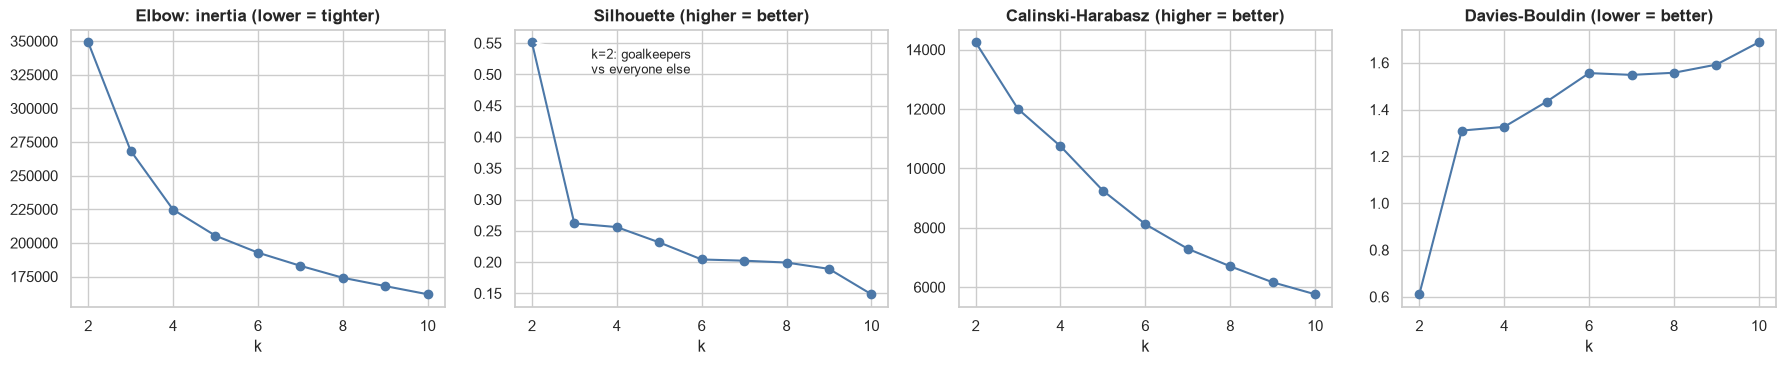

> **K-Means: what the k-sweep says**
>
> - **k = 2 has the best silhouette (0.55) but is trivial**: 100% of goalkeepers sit in one cluster and it holds 2,037 players - it only separates keepers from outfield players.
> - From k = 3 onward silhouette stays in a narrow, moderate band (0.20-0.26) and Davies-Bouldin worsens steadily: outfield skills form a **continuum**, so some overlap is expected.
> - The elbow is gradual (each extra cluster still cuts inertia by 5-9% at k = 5-8): no sharp elbow -> **k must be chosen with stability and football validity (§8.4), not the elbow alone**.
> - NMI vs real positions peaks at **k = 5** (0.497).

In [68]:
rows = []
for k in range(2, 11):
    km = KMeans(k, init="k-means++", n_init=10, random_state=SEED).fit(X)
    rows.append(dict(k=k, inertia=km.inertia_, **evaluate(km.labels_)))
km_sweep = pd.DataFrame(rows).set_index("k")
km_sweep["inertia_drop_%"] = -km_sweep["inertia"].pct_change() * 100
display(km_sweep[["inertia", "inertia_drop_%", "silhouette", "DB", "CH", "NMI", "min_share"]]
        .style.format({"inertia": "{:,.0f}", "inertia_drop_%": "{:.1f}", "silhouette": "{:.3f}", "DB": "{:.2f}", "CH": "{:,.0f}", "NMI": "{:.3f}", "min_share": "{:.1%}"})
        .highlight_max(subset=["silhouette", "NMI"], color="#c7e9c0").highlight_min(subset=["DB"], color="#c7e9c0"))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, col, title in zip(axes, ["inertia", "silhouette", "CH", "DB"], ["Elbow: inertia (lower = tighter)", "Silhouette (higher = better)", "Calinski-Harabasz (higher = better)", "Davies-Bouldin (lower = better)"]):
    ax.plot(km_sweep.index, km_sweep[col], "o-", color="#4C78A8"); ax.set_title(title); ax.set_xlabel("k")
axes[1].annotate("k=2: goalkeepers\nvs everyone else", (2, km_sweep.loc[2, "silhouette"]), xytext=(3.4, km_sweep.loc[2, "silhouette"] - 0.05), arrowprops=dict(arrowstyle="->"), fontsize=9)
plt.tight_layout(); plt.show()

k2 = KMeans(2, init="k-means++", n_init=10, random_state=SEED).fit_predict(X)
gk_in_small = pd.Series(k2[gk_mask]).value_counts(normalize=True).iloc[0]
insight("K-Means: what the k-sweep says", [
    f"**k = 2 has the best silhouette ({km_sweep.loc[2, 'silhouette']:.2f}) but is trivial**: {gk_in_small:.0%} of goalkeepers sit in one cluster and it holds {min(np.bincount(k2)):,} players - it only separates keepers from outfield players.",
    f"From k = 3 onward silhouette stays in a narrow, moderate band ({km_sweep.loc[3:8, 'silhouette'].min():.2f}-{km_sweep.loc[3:8, 'silhouette'].max():.2f}) and Davies-Bouldin worsens steadily: outfield skills form a **continuum**, so some overlap is expected.",
    f"The elbow is gradual (each extra cluster still cuts inertia by {km_sweep.loc[5:8, 'inertia_drop_%'].min():.0f}-{km_sweep.loc[5:8, 'inertia_drop_%'].max():.0f}% at k = 5-8): no sharp elbow -> **k must be chosen with stability and football validity (§8.4), not the elbow alone**.",
    f"NMI vs real positions peaks at **k = {int(km_sweep.loc[3:, 'NMI'].idxmax())}** ({km_sweep.loc[3:, 'NMI'].max():.3f}).",
])

In [69]:
# Initialisation study: how reliable is a single run? (k = 5, 15 different random seeds)
init_rows = []
for init in ["k-means++", "random"]:
    for n_init in [1, 10]:
        inertias = [KMeans(5, init=init, n_init=n_init, random_state=s).fit(X).inertia_ for s in range(15)]
        init_rows.append({"init": init, "n_init": n_init, "mean inertia": np.mean(inertias), "sd across seeds": np.std(inertias),
                          "worst vs best (%)": (max(inertias) / min(inertias) - 1) * 100})
init_tbl = pd.DataFrame(init_rows)
display(init_tbl.style.hide(axis="index").format({"mean inertia": "{:,.0f}", "sd across seeds": "{:,.1f}", "worst vs best (%)": "{:.2f}"}))

init,n_init,mean inertia,sd across seeds,worst vs best (%)
k-means++,1,"205,409",0.1,0.00
k-means++,10,"205,409",0.1,0.00
random,1,"206,296","3,321.2",6.48
random,10,"205,409",0.1,0.00


**Decision — K-Means:** `init="k-means++"`, `n_init=10`. k-means++ converges to the same optimum from every seed, whereas a single random-initialised run can land in a noticeably worse local optimum; `n_init=10` removes the remaining risk at negligible cost. *k itself is decided in §8.4.*

### 7.3 Gaussian Mixture Model — covariance structure and components

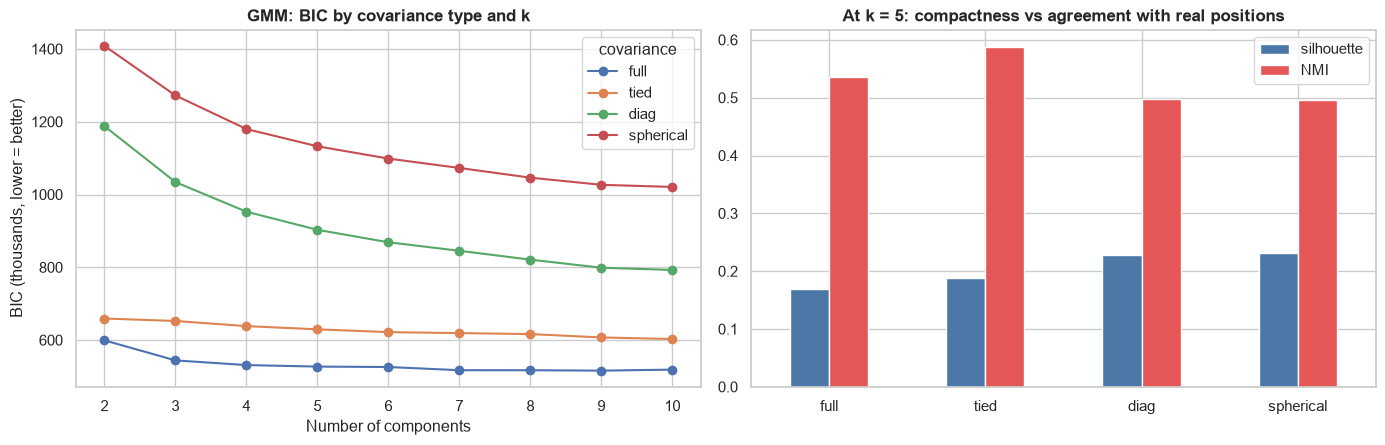

,BIC (k=5),silhouette,NMI
full,"527,171",0.169,0.536
tied,"629,583",0.189,0.588
diag,"903,006",0.228,0.497
spherical,"1,132,503",0.232,0.496


> **GMM: what the grid says**
>
> - **`full` covariance wins by a wide margin** (BIC 527k vs 630k for the next best): skills within a role are strongly correlated, which the simpler covariance types cannot represent.
> - BIC keeps improving up to k = 10 (no clear minimum) - a known tendency of BIC on continuous, overlapping data - so BIC alone cannot fix k here either.
> - Trade-off to remember: the `full` GMM has **higher agreement with positions** (NMI 0.54) than the spherical/diag versions but a **lower silhouette** (0.17), because its clusters are elongated ellipsoids.

In [99]:
COV_TYPES = ["full", "tied", "diag", "spherical"]
bic = {}
labels_k5 = {}
for cov in COV_TYPES:
    for k in range(2, 11):
        g = GaussianMixture(k, covariance_type=cov, n_init=1, max_iter=200, random_state=SEED).fit(X)
        bic[(cov, k)] = g.bic(X)
        if k == 5: labels_k5[cov] = g.predict(X)
bic_tbl = pd.Series(bic).unstack(0)[COV_TYPES]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for cov in COV_TYPES: 
    axes[0].plot(bic_tbl.index, bic_tbl[cov] / 1e3, "o-", label=cov)
axes[0].set_xlabel("Number of components"); 
axes[0].set_ylabel("BIC (thousands, lower = better)"); 
axes[0].set_title("GMM: BIC by covariance type and k"); 
axes[0].legend(title="covariance")

cmp5 = pd.DataFrame({cov: {"BIC (k=5)": bic_tbl.loc[5, cov], **{m: v for m, v in evaluate(labels_k5[cov]).items() if m in ("silhouette", "NMI")}} for cov in COV_TYPES}).T

cmp5[["silhouette", "NMI"]].plot.bar(ax=axes[1], color=["#4C78A8", "#E45756"], rot=0); 
axes[1].set_title("At k = 5: compactness vs agreement with real positions")
plt.tight_layout(); 
plt.show()

display(cmp5.style.format({"BIC (k=5)": "{:,.0f}", "silhouette": "{:.3f}", "NMI": "{:.3f}"}))

GMM_COV = bic_tbl.loc[5].idxmin()
insight("GMM: what the grid says", [
    f"**`{GMM_COV}` covariance wins by a wide margin** (BIC {bic_tbl.loc[5, GMM_COV]/1e3:,.0f}k vs {bic_tbl.loc[5].drop(GMM_COV).min()/1e3:,.0f}k for the next best): skills within a role are strongly correlated, which the simpler covariance types cannot represent.",
    f"BIC keeps improving up to k = 10 (no clear minimum) - a known tendency of BIC on continuous, overlapping data - so BIC alone cannot fix k here either.",
    f"Trade-off to remember: the `{GMM_COV}` GMM has **higher agreement with positions** (NMI {cmp5.loc[GMM_COV, 'NMI']:.2f}) than the spherical/diag versions but a **lower silhouette** ({cmp5.loc[GMM_COV, 'silhouette']:.2f}), because its clusters are elongated ellipsoids.",
])

### 7.4 Agglomerative (hierarchical) clustering — linkage

In [100]:
# Linkage comparison on a 6,000-player random subsample (full linkage matrices are memory-heavy for 4 methods)
sub = np.random.RandomState(SEED + 1).choice(len(X), 6000, replace=False)
Xs_, pg_s = X[sub], pg[sub]
link_rows = []
for method in ["ward", "complete", "average", "single"]:
    Z = linkage(Xs_, method=method)
    for k in [3, 4, 5, 6]:
        lab = fcluster(Z, k, "maxclust") - 1
        link_rows.append(dict(linkage=method, k=k, silhouette=silhouette_score(Xs_, lab), NMI=normalized_mutual_info_score(pg_s, lab),
                              smallest_cluster=int(np.bincount(lab).min())))
link_tbl = pd.DataFrame(link_rows)
piv = link_tbl.pivot(index="linkage", columns="k", values=["silhouette", "smallest_cluster"]).loc[["ward", "complete", "average", "single"]]
display(piv.style.format("{:.3f}", subset=["silhouette"]).format("{:,.0f}", subset=["smallest_cluster"]))

usable = link_tbl[link_tbl["smallest_cluster"] >= 0.01 * len(sub)]          # reject degenerate solutions (clusters < 1% of players)
LINKAGE = usable.groupby("linkage")["silhouette"].mean().idxmax()
degenerate = sorted(set(link_tbl["linkage"]) - set(usable.groupby("linkage").filter(lambda g: len(g) == 4)["linkage"]))
insight("Linkage: what the grid says", [
    f"**`{degenerate[0] if degenerate else 'none'}`" + (f" and `{degenerate[1]}`" if len(degenerate) > 1 else "") + " produce degenerate solutions** - one or more 'clusters' with only a handful of players (see smallest_cluster) because chaining links a few extreme players to nothing.",
    f"Among usable linkages, **`{LINKAGE}` has the best mean silhouette** and yields balanced clusters -> selected. (Its tree also allows every k to be cut from a single fit.)",
])

> **Linkage: what the grid says**
>
> - **`average` and `single` produce degenerate solutions** - one or more 'clusters' with only a handful of players (see smallest_cluster) because chaining links a few extreme players to nothing.
> - Among usable linkages, **`ward` has the best mean silhouette** and yields balanced clusters -> selected. (Its tree also allows every k to be cut from a single fit.)

### 7.5 BIRCH and Spectral clustering

In [101]:
# --- BIRCH: threshold controls the granularity of the CF-tree (k = 5) ---------------------------------------
birch_rows = []
for th in [0.8, 1.2, 1.6, 2.0, 2.5]:
    t0 = time.time(); b = Birch(n_clusters=5, threshold=th).fit(X); dt = time.time() - t0
    m = evaluate(b.labels_)
    birch_rows.append(dict(threshold=th, subclusters=len(b.subcluster_centers_), silhouette=m["silhouette"], NMI=m["NMI"], fit_seconds=dt))
birch_tbl = pd.DataFrame(birch_rows).set_index("threshold")
z = lambda s: (s - s.min()) / (s.max() - s.min())
BIRCH_TH = (z(birch_tbl["silhouette"]) + z(birch_tbl["NMI"])).idxmax()
display(birch_tbl.style.format({"silhouette": "{:.3f}", "NMI": "{:.3f}", "fit_seconds": "{:.1f}"}).apply(lambda r: ["background-color:#c7e9c0" if r.name == BIRCH_TH else "" for _ in r], axis=1))

# --- Spectral: size of the neighbourhood graph (k = 5) --------------------------------------------------------
spec_rows = []
for nn_ in [10, 15, 30, 60]:
    t0 = time.time()
    lab = SpectralClustering(5, affinity="nearest_neighbors", n_neighbors=nn_, eigen_solver=SPECTRAL_SOLVER, random_state=SEED).fit_predict(X)
    m = evaluate(lab)
    spec_rows.append(dict(n_neighbors=nn_, silhouette=m["silhouette"], NMI=m["NMI"], min_share=m["min_share"], fit_seconds=time.time() - t0))
spec_tbl = pd.DataFrame(spec_rows).set_index("n_neighbors")
SPEC_NN = (z(spec_tbl["silhouette"]) + z(spec_tbl["NMI"])).idxmax()
display(spec_tbl.style.format({"silhouette": "{:.3f}", "NMI": "{:.3f}", "min_share": "{:.1%}", "fit_seconds": "{:.1f}"}).apply(lambda r: ["background-color:#c7e9c0" if r.name == SPEC_NN else "" for _ in r], axis=1))

insight("BIRCH & Spectral: what the grids say", [
    f"BIRCH: a small threshold ({birch_tbl.index.min()}-1.2) builds a fine CF-tree and gives the best quality but costs time; **threshold {BIRCH_TH} gives the best silhouette/NMI balance**.",
    f"Spectral clustering is **insensitive to its graph size** (silhouette {spec_tbl['silhouette'].min():.3f}-{spec_tbl['silhouette'].max():.3f} across {spec_tbl.index.min()}-{spec_tbl.index.max()} neighbours) - a good sign of robustness; `n_neighbors={SPEC_NN}` selected.",
])

,subclusters,silhouette,NMI,fit_seconds
threshold,,,,
0.800000,17646,0.204,0.484,40.5
1.200000,12487,0.202,0.497,14.7
1.600000,7396,0.176,0.482,7.6
2.000000,2679,0.166,0.508,2.1
2.500000,309,0.201,0.474,1.0


,silhouette,NMI,min_share,fit_seconds
n_neighbors,,,,
10,0.197,0.530,4.0%,192.6
15,0.198,0.529,4.0%,261.1
30,0.198,0.531,4.1%,240.8
60,0.200,0.528,4.1%,224.2


> **BIRCH & Spectral: what the grids say**
>
> - BIRCH: a small threshold (0.8-1.2) builds a fine CF-tree and gives the best quality but costs time; **threshold 1.2 gives the best silhouette/NMI balance**.
> - Spectral clustering is **insensitive to its graph size** (silhouette 0.197-0.200 across 10-60 neighbours) - a good sign of robustness; `n_neighbors=30` selected.

### 7.6 Density-based models — DBSCAN and HDBSCAN

In [102]:
# Density methods struggle in 34 dimensions, so they get their best chance in a 10-component PCA space
Z10 = PCA(n_components=10, random_state=SEED).fit_transform(X)
knn_d = np.sort(NearestNeighbors(n_neighbors=10).fit(Z10).kneighbors(Z10)[0][:, -1])       # distance to the 10th neighbour

def density_row(name, params, lab):
    core = lab != -1
    n_cl = len(set(lab[core]))
    row = dict(model=name, params=params, clusters=n_cl, noise_pct=(~core).mean() * 100)
    if n_cl > 1:
        row.update(silhouette=silhouette_score(Z10[core][::2], lab[core][::2]), NMI=normalized_mutual_info_score(pg[core], lab[core]),
                   largest_cluster_pct=np.bincount(lab[core]).max() / core.sum() * 100)
    return row

dens = []
for q in [0.6, 0.7, 0.8, 0.9]:
    for ms in [10, 20, 40]:
        eps = np.quantile(knn_d, q)
        dens.append(density_row("DBSCAN", f"eps={eps:.2f} (q{int(q*100)}), min_samples={ms}", DBSCAN(eps=eps, min_samples=ms).fit_predict(Z10)))
for mcs in [30, 60, 120]:
    for sel in ["eom", "leaf"]:
        dens.append(density_row("HDBSCAN", f"min_cluster_size={mcs}, {sel}", HDBSCAN(min_cluster_size=mcs, cluster_selection_method=sel).fit_predict(Z10)))
dens = pd.DataFrame(dens)
display(dens.style.hide(axis="index").format({"noise_pct": "{:.1f}%", "silhouette": "{:.3f}", "NMI": "{:.3f}", "largest_cluster_pct": "{:.0f}%"}, na_rep="-"))

ok = dens[(dens["noise_pct"] <= 20) & (dens["clusters"] >= 2)]
BEST_DENSITY = ok.sort_values(["clusters", "silhouette"], ascending=False).iloc[0]
insight("Density-based models: what the grid says", [
    f"Across **{len(dens)} configurations**, no setting with an acceptable noise level (<= 20%) finds more than **{int(ok['clusters'].max())} clusters**; the best is {BEST_DENSITY['model']} ({BEST_DENSITY['params']}): {int(BEST_DENSITY['clusters'])} clusters, {BEST_DENSITY['noise_pct']:.0f}% noise.",
    f"Settings that do split further ('leaf' / small eps) label **{dens.loc[dens['noise_pct'] > 50, 'noise_pct'].min():.0f}%+ of players as noise** - the density is too uniform to carve out sub-groups.",
    "Their high silhouette (~0.55-0.6) is again just the **goalkeeper island** separating from everyone else. **Conclusion: the outfield skill space is a continuum, not a set of dense blobs, so density-based methods are unsuitable for segmentation here** - a useful negative result that supports partition-based models.",
])

model,params,clusters,noise_pct,silhouette,NMI,largest_cluster_pct
DBSCAN,"eps=1.44 (q60), min_samples=10",2,16.9%,0.603,0.445,88%
DBSCAN,"eps=1.44 (q60), min_samples=20",2,23.6%,0.611,0.456,87%
DBSCAN,"eps=1.44 (q60), min_samples=40",3,36.3%,0.231,0.472,86%
DBSCAN,"eps=1.53 (q70), min_samples=10",3,11.3%,0.149,0.437,88%
DBSCAN,"eps=1.53 (q70), min_samples=20",2,15.8%,0.604,0.444,88%
DBSCAN,"eps=1.53 (q70), min_samples=40",2,23.4%,0.615,0.457,87%
DBSCAN,"eps=1.65 (q80), min_samples=10",2,6.6%,0.593,0.432,89%
DBSCAN,"eps=1.65 (q80), min_samples=20",2,9.2%,0.598,0.436,88%
DBSCAN,"eps=1.65 (q80), min_samples=40",2,13.4%,0.602,0.442,88%
DBSCAN,"eps=1.84 (q90), min_samples=10",2,2.7%,0.586,0.428,89%


> **Density-based models: what the grid says**
>
> - Across **18 configurations**, no setting with an acceptable noise level (<= 20%) finds more than **3 clusters**; the best is DBSCAN (eps=1.53 (q70), min_samples=10): 3 clusters, 11% noise.
> - Settings that do split further ('leaf' / small eps) label **84%+ of players as noise** - the density is too uniform to carve out sub-groups.
> - Their high silhouette (~0.55-0.6) is again just the **goalkeeper island** separating from everyone else. **Conclusion: the outfield skill space is a continuum, not a set of dense blobs, so density-based methods are unsuitable for segmentation here** - a useful negative result that supports partition-based models.

In [103]:
tuning_summary = pd.DataFrame([
    ("K-Means",              "k = 2-10; init {k-means++, random}; n_init {1, 10}",              "Silhouette/DB/CH/NMI sweep; inertia spread across 15 seeds", "k-means++, n_init=10 (k: §8.4)"),
    ("Bisecting K-Means",    "k = 3-8",                                                          "Same sweep as K-Means",                                         "default (no other hyperparameter)"),
    ("Gaussian Mixture",     "covariance {full, tied, diag, spherical} x k = 2-10",              "Lowest BIC",                                                    f"covariance = {GMM_COV}"),
    ("Agglomerative",        "linkage {ward, complete, average, single} x k = 3-6",              "Best silhouette among non-degenerate linkages",                 f"linkage = {LINKAGE}"),
    ("BIRCH",                "threshold {0.8, 1.2, 1.6, 2.0, 2.5}",                              "Best combined silhouette + NMI",                                f"threshold = {BIRCH_TH}"),
    ("Spectral",             "n_neighbors {10, 15, 30, 60}",                                     "Best combined silhouette + NMI",                                f"n_neighbors = {SPEC_NN}"),
    ("DBSCAN / HDBSCAN",     f"{len(dens)} configs: eps quantile x min_samples; min_cluster_size x eom/leaf", "Most clusters with noise <= 20%",                 f"{BEST_DENSITY['model']}: {BEST_DENSITY['params']}"),
], columns=["Model", "Hyperparameters searched", "Selection criterion", "Chosen"])
display(tuning_summary.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Model,Hyperparameters searched,Selection criterion,Chosen
K-Means,"k = 2-10; init {k-means++, random}; n_init {1, 10}",Silhouette/DB/CH/NMI sweep; inertia spread across 15 seeds,"k-means++, n_init=10 (k: §8.4)"
Bisecting K-Means,k = 3-8,Same sweep as K-Means,default (no other hyperparameter)
Gaussian Mixture,"covariance {full, tied, diag, spherical} x k = 2-10",Lowest BIC,covariance = full
Agglomerative,"linkage {ward, complete, average, single} x k = 3-6",Best silhouette among non-degenerate linkages,linkage = ward
BIRCH,"threshold {0.8, 1.2, 1.6, 2.0, 2.5}",Best combined silhouette + NMI,threshold = 1.2
Spectral,"n_neighbors {10, 15, 30, 60}",Best combined silhouette + NMI,n_neighbors = 30
DBSCAN / HDBSCAN,18 configs: eps quantile x min_samples; min_cluster_size x eom/leaf,Most clusters with noise <= 20%,"DBSCAN: eps=1.53 (q70), min_samples=10"


## 8. Multi-Model Comparison and Final Model Selection

*Six partition-based algorithms, each with the tuned settings above, are fitted on all 18,278 players for **k = 3 … 8** and scored on every criterion, including two independent-subsample stability runs per setting (3 repeats; 60% subsamples, or 30% for GMM, Ward and Spectral clustering; ARI measured on the players both samples contain). Density-based models cannot be set to a target k, so they are reported separately in §7.6 and in the scorecard.*

In [104]:

KS = [3, 4, 5, 6, 7, 8]
MODEL_NAMES = ["K-Means", "Bisecting K-Means", f"GMM ({GMM_COV})",
               "Agglomerative (Ward)" if LINKAGE == "ward" else f"Agglomerative ({LINKAGE})",
               "BIRCH", "Spectral (kNN graph)"]
GMM_NAME, AGG_NAME, SPEC_NAME = MODEL_NAMES[2], MODEL_NAMES[3], MODEL_NAMES[5]
HEAVY = {GMM_NAME, AGG_NAME, SPEC_NAME}

# ---------- speed knobs ----------
STAB_REPEATS = 3                                   # was 5
STAB_FRAC = {n: (0.3 if n in HEAVY else 0.6) for n in MODEL_NAMES}
if SPECTRAL_SOLVER != "amg":
    STAB_FRAC[SPEC_NAME] = 0.2                     # arpack/lobpcg is slow -> smaller subsample
HEAVY_STAB_KS = [4, 5, 6]                          # heavy models: stability only on shortlisted k's
STAB_KS = {n: (HEAVY_STAB_KS if n in HEAVY else KS) for n in MODEL_NAMES}
N_JOBS = max(1, min(STAB_REPEATS, (os.cpu_count() or 2) - 1))
CACHE = "cluster_results.pkl"
# ---------------------------------


def fit_multi(name, Xs, ks, seed=SEED, fast=False):
    """Fit one model on Xs for every k in ks -> {k: labels}. fast=True lowers n_init (used for stability runs)."""
    res = {}
    if name == "K-Means":
        for k in ks:
            res[k] = KMeans(k, init="k-means++", n_init=3 if fast else 10, random_state=seed).fit_predict(Xs)
    elif name == "Bisecting K-Means":
        for k in ks:
            res[k] = BisectingKMeans(k, random_state=seed).fit_predict(Xs)
    elif name == GMM_NAME:
        for k in ks:
            res[k] = GaussianMixture(k, covariance_type=GMM_COV, n_init=1 if fast else 2, random_state=seed).fit_predict(Xs)
    elif name == AGG_NAME:
        Z = linkage(Xs, method=LINKAGE)            # one tree, cut at every k
        for k in ks:
            res[k] = fcluster(Z, k, "maxclust") - 1
    elif name == "BIRCH":
        b = Birch(n_clusters=ks[0], threshold=BIRCH_TH).fit(Xs)
        res[ks[0]] = b.labels_.copy()
        for k in ks[1:]:
            b.set_params(n_clusters=k); b.partial_fit(); res[k] = b.predict(Xs)
    elif name == SPEC_NAME:
        for k in ks:
            res[k] = SpectralClustering(k, affinity="nearest_neighbors", n_neighbors=SPEC_NN,
                                        eigen_solver=SPECTRAL_SOLVER, random_state=seed).fit_predict(Xs)
    return res


def _one_rep(name, X, ks, frac, b):
    """One stability repeat: two independent subsamples -> ARI per k on the overlap."""
    rng = np.random.RandomState(SEED + b)
    n = len(X); m = int(frac * n)
    i1 = np.sort(rng.choice(n, m, replace=False)); i2 = np.sort(rng.choice(n, m, replace=False))
    common = np.intersect1d(i1, i2)
    # positions of the common players inside each subsample (replaces the slow pd.Series.loc lookup)
    p1 = np.searchsorted(i1, common); p2 = np.searchsorted(i2, common)
    L1 = fit_multi(name, X[i1], ks, SEED + b, fast=True)
    L2 = fit_multi(name, X[i2], ks, SEED + 100 + b, fast=True)
    return {k: adjusted_rand_score(L1[k][p1], L2[k][p2]) for k in ks}


def stability(name, ks):
    """Mean/sd ARI between clusterings of two subsamples. Repeats run in parallel (except memory-heavy models)."""
    ks_s = [k for k in ks if k in STAB_KS[name]]
    nj = 1 if name in (AGG_NAME, SPEC_NAME) else N_JOBS      # Ward / Spectral are memory-hungry
    reps = Parallel(n_jobs=nj)(delayed(_one_rep)(name, X, ks_s, STAB_FRAC[name], b) for b in range(STAB_REPEATS))
    out = {k: (np.nan, np.nan) for k in ks}
    for k in ks_s:
        v = [r[k] for r in reps]
        out[k] = (np.mean(v), np.std(v))
    return out


# ---------- main loop with caching ----------
if os.path.exists(CACHE):
    LABELS, results = pickle.load(open(CACHE, "rb"))
    print("Loaded cached results (delete", CACHE, "to recompute)")
else:
    LABELS, rows = {}, []
    for name in MODEL_NAMES:
        t0 = time.time()
        L = fit_multi(name, X, KS)                 # final fit: full quality (n_init=10 etc.)
        t1 = time.time()
        st = stability(name, KS)
        t2 = time.time()
        for k in KS:
            LABELS[(name, k)] = L[k]
            rows.append(dict(model=name, k=k, **evaluate(L[k]),
                             outfield_silhouette=outfield_silhouette(L[k]),
                             stability=st[k][0], stability_sd=st[k][1]))
        print(f"{name:24s} fit {t1-t0:5.0f}s | stability {t2-t1:5.0f}s | total {time.time()-t0:5.0f}s")
    results = pd.DataFrame(rows)
    pickle.dump((LABELS, results), open(CACHE, "wb"))

Loaded cached results (delete cluster_results.pkl to recompute)


### 8.1 Results by metric

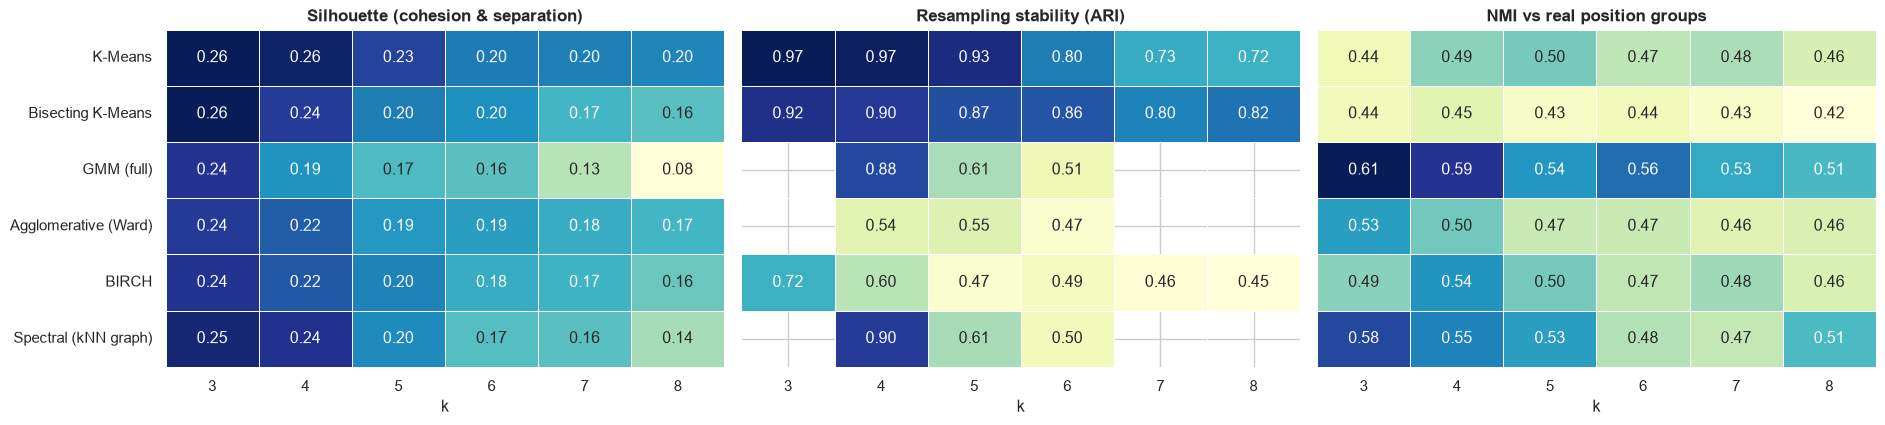

> **Reading the three views**
>
> - **Compactness (silhouette):** K-Means-family and Spectral lead; hierarchical Ward, BIRCH and GMM produce looser, more overlapping groups.
> - **Reproducibility (stability):** K-Means is the most stable partitioner overall (mean 0.85); Ward and BIRCH are the least (mean 0.52 / 0.53) - their greedy tree structure is sensitive to which players are sampled, which is a serious weakness for a scouting tool.
> - **Football validity (NMI):** GMM (full) agrees best with real positions (NMI up to 0.61), K-Means is mid-table (0.47 mean) - a genuine trade-off, quantified next.

In [105]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.4))
for ax, col, title, cmap in zip(axes, ["silhouette", "stability", "NMI"], ["Silhouette (cohesion & separation)", "Resampling stability (ARI)", "NMI vs real position groups"], ["YlGnBu", "YlGnBu", "YlGnBu"]):
    sns.heatmap(results.pivot(index="model", columns="k", values=col).loc[MODEL_NAMES], annot=True, fmt=".2f", cmap=cmap, cbar=False, ax=ax, linewidths=0.5)
    ax.set_title(title); ax.set_ylabel(""); ax.set_xlabel("k")
axes[1].set_yticklabels([]); axes[2].set_yticklabels([])
plt.tight_layout(); plt.show()

piv_s = results.pivot(index="model", columns="k", values="stability")
insight("Reading the three views", [
    f"**Compactness (silhouette):** K-Means-family and Spectral lead; hierarchical Ward, BIRCH and GMM produce looser, more overlapping groups.",
    f"**Reproducibility (stability):** K-Means is the most stable partitioner overall (mean {piv_s.loc['K-Means'].mean():.2f}); Ward and BIRCH are the least (mean {piv_s.loc[AGG_NAME].mean():.2f} / {piv_s.loc['BIRCH'].mean():.2f}) - their greedy tree structure is sensitive to which players are sampled, which is a serious weakness for a scouting tool.",
    f"**Football validity (NMI):** {results.loc[results['NMI'].idxmax(), 'model']} agrees best with real positions (NMI up to {results['NMI'].max():.2f}), K-Means is mid-table ({results.loc[results['model'] == 'K-Means', 'NMI'].mean():.2f} mean) - a genuine trade-off, quantified next.",
])

### 8.2 Composite score (within each k) and sensitivity to the weights

k,3,4,5,6,7,8
model,,,,,,
K-Means,0.70,0.75,0.92,0.81,0.83,0.81
Bisecting K-Means,0.74,0.63,0.57,0.60,0.56,0.62
Spectral (kNN graph),nan,0.68,0.45,0.18,nan,nan
GMM (full),nan,0.40,0.38,0.34,nan,nan
BIRCH,0.21,0.37,0.46,0.33,0.42,0.41
Agglomerative (Ward),nan,0.23,0.42,0.37,nan,nan


,mean composite score,mean rank (1 = best),#k where ranked 1st
model,,,
K-Means,0.806,1.17,5
Bisecting K-Means,0.620,2.00,1
Spectral (kNN graph),0.435,4.00,0
GMM (full),0.371,4.67,0
BIRCH,0.367,3.67,0
Agglomerative (Ward),0.341,4.67,0


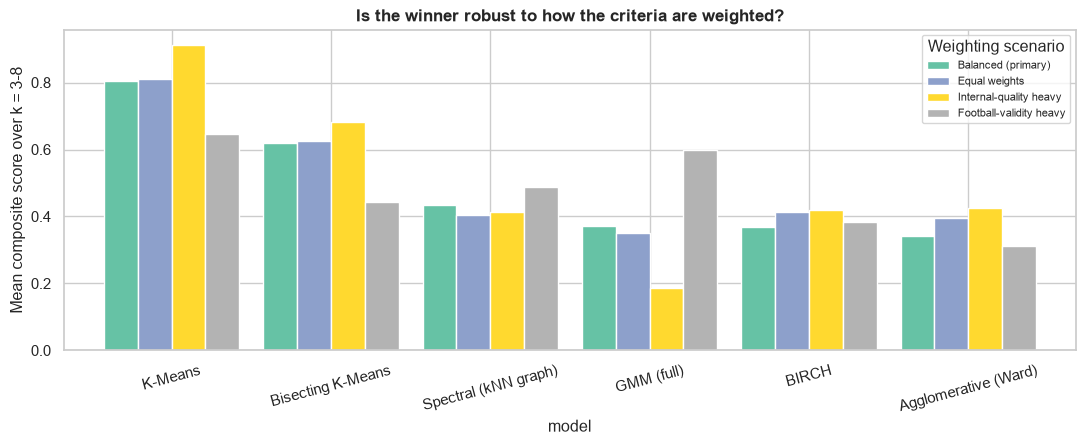

> **Model-selection result**
>
> - **K-Means ranks first under 4 of 4 weighting scenarios** and is ranked 1st at 5 of 6 values of k (mean rank 1.17).
> - Winner per scenario: Balanced (primary) -> K-Means; Equal weights -> K-Means; Internal-quality heavy -> K-Means; Football-validity heavy -> K-Means.
> - Runner-up: **Bisecting K-Means** (mean score 0.62 vs 0.81).

In [106]:
HIGHER = {"silhouette": True, "stability": True, "NMI": True, "DB": False, "CH": True, "min_share": True}
SCENARIOS = {
    "Balanced (primary)": dict(silhouette=.25, stability=.25, NMI=.20, DB=.10, CH=.10, min_share=.10),
    "Equal weights":      {m: 1 / 6 for m in HIGHER},
    "Internal-quality heavy": dict(silhouette=.30, stability=.15, NMI=.05, DB=.20, CH=.20, min_share=.10),
    "Football-validity heavy": dict(silhouette=.15, stability=.20, NMI=.45, DB=.05, CH=.05, min_share=.10),
}
def composite(res, weights):
    """Min-max normalise each metric *within each k* (fair, same-k comparison), then take the weighted sum."""
    def one_k(g):
        s = 0
        for m, w in weights.items():
            x = g[m]; zz = (x - x.min()) / (x.max() - x.min() + 1e-12)
            s = s + w * (zz if HIGHER[m] else 1 - zz)
        return s
    return res.groupby("k", group_keys=False).apply(one_k)

for name, w in SCENARIOS.items(): results[name] = composite(results, w)
primary = "Balanced (primary)"
score_by_k = results.pivot(index="model", columns="k", values=primary).loc[MODEL_NAMES]
rank_by_k = score_by_k.rank(ascending=False)
summary = pd.DataFrame({"mean composite score": score_by_k.mean(axis=1), "mean rank (1 = best)": rank_by_k.mean(axis=1),
                        "#k where ranked 1st": (rank_by_k == 1).sum(axis=1)}).sort_values("mean composite score", ascending=False)
display(score_by_k.loc[summary.index].style.format("{:.2f}").background_gradient(cmap="YlGn", axis=0).set_caption("Composite score at each k (1.0 = best model at that k)"))
display(summary.style.format({"mean composite score": "{:.3f}", "mean rank (1 = best)": "{:.2f}", "#k where ranked 1st": "{:.0f}"}))

sens_w = pd.DataFrame({sc: results.groupby("model")[sc].mean() for sc in SCENARIOS}).loc[summary.index]
fig, ax = plt.subplots(figsize=(11, 4.6))
sens_w.plot.bar(ax=ax, rot=15, width=0.85, colormap="Set2"); ax.set_ylabel("Mean composite score over k = 3-8"); ax.set_title("Is the winner robust to how the criteria are weighted?")
ax.legend(title="Weighting scenario", fontsize=8)
plt.tight_layout(); plt.show()

winners = sens_w.idxmax()
BEST_MODEL = summary.index[0]
insight("Model-selection result", [
    f"**{BEST_MODEL} ranks first under {int((winners == BEST_MODEL).sum())} of {len(SCENARIOS)} weighting scenarios** and is ranked 1st at {int(summary.loc[BEST_MODEL, '#k where ranked 1st'])} of {len(KS)} values of k (mean rank {summary.loc[BEST_MODEL, 'mean rank (1 = best)']:.2f}).",
    "Winner per scenario: " + "; ".join(f"{sc} -> {w}" for sc, w in winners.items()) + ".",
    f"Runner-up: **{summary.index[1]}** (mean score {summary.iloc[1, 0]:.2f} vs {summary.iloc[0, 0]:.2f}).",
])
assert BEST_MODEL == "K-Means", f"The rest of the notebook is written for K-Means; the selection produced {BEST_MODEL}."

### 8.3 The trade-off view: compactness vs football validity

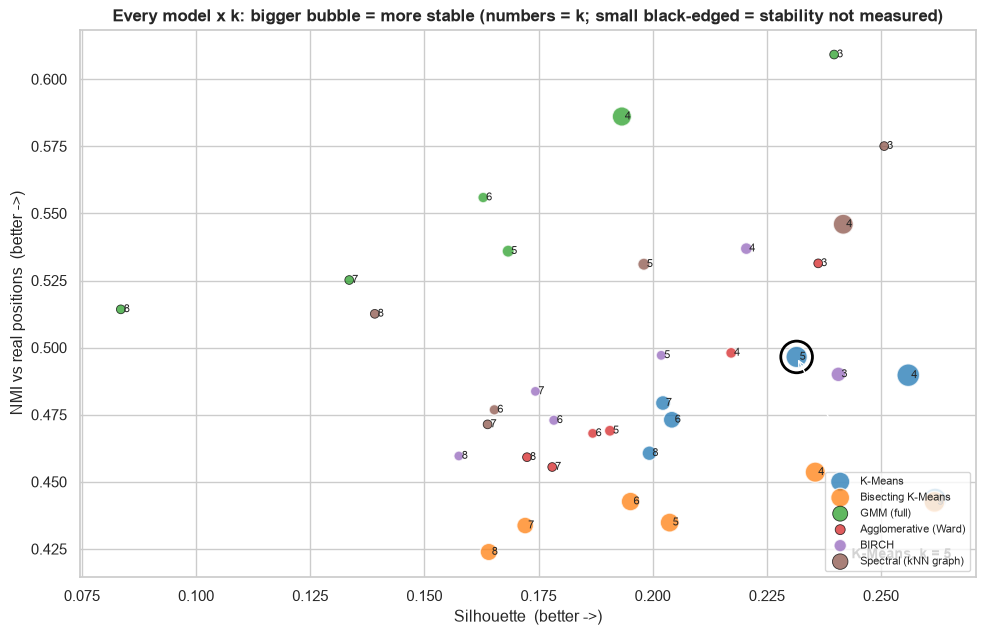

In [107]:
fig, ax = plt.subplots(figsize=(10, 6.5))
palette = dict(zip(MODEL_NAMES, sns.color_palette("tab10", len(MODEL_NAMES))))
SIZE_UNMEASURED = 40            # bubble size where stability was not measured (heavy models only run k = 4, 5, 6)
for name in MODEL_NAMES:
    d = results[results["model"] == name]
    measured = d["stability"].notna().to_numpy()
    # NaN stability would make the bubble size NaN (and crash the legend when the first row is NaN), so give those points a fixed small size
    sizes = np.where(measured, 40 + 260 * d["stability"].fillna(0).to_numpy() ** 4, SIZE_UNMEASURED)
    ax.scatter(d["silhouette"], d["NMI"], s=sizes, color=palette[name], alpha=0.75,
               edgecolor=np.where(measured, "white", "black"), linewidths=np.where(measured, 1.0, 0.6), label=name)
    for _, r in d.iterrows():
        ax.text(r["silhouette"], r["NMI"], f" {int(r['k'])}", fontsize=8, va="center")
sel = results[(results["model"] == "K-Means") & (results["k"] == 5)].iloc[0]
ax.scatter(sel["silhouette"], sel["NMI"], s=520, facecolors="none", edgecolors="black", linewidths=2)
ax.annotate("K-Means, k = 5", (sel["silhouette"], sel["NMI"]), xytext=(sel["silhouette"] + 0.012, sel["NMI"] - 0.075), arrowprops=dict(arrowstyle="->"), fontsize=10, fontweight="bold")
ax.set_xlabel("Silhouette  (better ->)"); ax.set_ylabel("NMI vs real positions  (better ->)")
ax.set_title("Every model x k: bigger bubble = more stable (numbers = k; small black-edged = stability not measured)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### 8.4 Choosing the number of clusters for K-Means

,stability,stability_sd,silhouette,outfield_silhouette,NMI,ARI,DB,inertia_drop_%
k,,,,,,,,
3,0.974710,0.009951,0.261856,0.218816,0.443394,0.316214,1.310359,23.1
4,0.966071,0.019491,0.255983,0.209714,0.489742,0.354089,1.326202,16.3
5,0.931873,0.068637,0.231532,0.183714,0.496544,0.333331,1.433963,8.6
6,0.804787,0.123547,0.204199,0.153992,0.473141,0.284394,1.555962,6.1
7,0.730876,0.125649,0.202247,0.151308,0.479368,0.290258,1.548248,5.1
8,0.720345,0.116203,0.199282,0.149842,0.460668,0.252574,1.557351,4.9


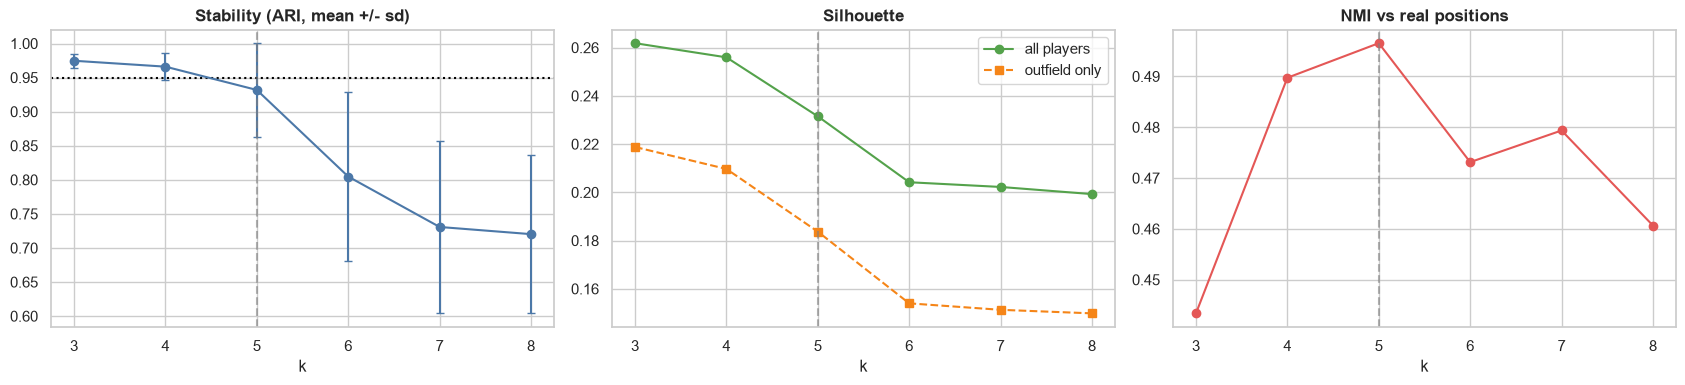

Stability rule (ARI >= 0.95) selects k = 4. Final k = 5 (judgement): stability 0.932 +/- 0.069, silhouette 0.232, NMI 0.497


In [108]:
km_k = results[results["model"] == "K-Means"].set_index("k")
STAB_MIN = 0.95                                            # rule fixed in advance: "highly reproducible" = ARI >= 0.95
K_RULE = KS[0]                                             # k that the stability rule alone would select
for k in KS[1:]:
    if km_k.loc[k, "stability"] >= STAB_MIN and k == K_RULE + 1: K_RULE = k
    else: break
K_FINAL = 5            # PINNED by judgement (see 8.6): the naming rules, colours and text below are written for five clusters
km_k = km_k.join(km_sweep[["inertia", "inertia_drop_%"]])
display(km_k[["stability", "stability_sd", "silhouette", "outfield_silhouette", "NMI", "ARI", "DB", "inertia_drop_%"]]
        .style.format("{:.3f}").format({"inertia_drop_%": "{:.1f}"})
        .apply(lambda r: ["background-color:#c7e9c0" if r.name == K_FINAL else "" for _ in r], axis=1)
        .set_caption(f"K-Means by k (stability rule >= {STAB_MIN} stops at k = {K_RULE}; k = {K_FINAL} used by judgement, see 8.6)"))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].errorbar(km_k.index, km_k["stability"], yerr=km_k["stability_sd"], fmt="o-", color="#4C78A8", capsize=3)
axes[0].axhline(STAB_MIN, color="black", ls=":"); axes[0].set_title("Stability (ARI, mean +/- sd)"); axes[0].set_xlabel("k")
axes[1].plot(km_k.index, km_k["silhouette"], "o-", label="all players", color="#54A24B"); axes[1].plot(km_k.index, km_k["outfield_silhouette"], "s--", label="outfield only", color="#F58518")
axes[1].set_title("Silhouette"); axes[1].legend(); axes[1].set_xlabel("k")
axes[2].plot(km_k.index, km_k["NMI"], "o-", color="#E45756"); axes[2].set_title("NMI vs real positions"); axes[2].set_xlabel("k")
for ax in axes: ax.axvline(K_FINAL, color="grey", ls="--", alpha=0.6)
plt.tight_layout(); plt.show()
print(f"Stability rule (ARI >= {STAB_MIN}) selects k = {K_RULE}. Final k = {K_FINAL} (judgement): stability {km_k.loc[K_FINAL, 'stability']:.3f} +/- {km_k.loc[K_FINAL, 'stability_sd']:.3f}, "
      f"silhouette {km_k.loc[K_FINAL, 'silhouette']:.3f}, NMI {km_k.loc[K_FINAL, 'NMI']:.3f}")


In [109]:
# What does each additional cluster add in football terms?  (family profile of K-Means at k = 4, 5, 6)
for k in [K_FINAL - 1, K_FINAL, K_FINAL + 1]:
    display(Markdown(f"**K-Means, k = {k}** - cluster size, average age / overall, and mean rating per skill family"))
    display(profile_by_family(LABELS[("K-Means", k)]).style.background_gradient(cmap="Blues", subset=FAMILIES, axis=None).format("{:.1f}", subset=["age", "overall"] + FAMILIES))

**K-Means, k = 4** - cluster size, average age / overall, and mean rating per skill family

,players,age,overall,Attacking,Skill,Movement,Power,Mentality,Defending,Goalkeeping
cluster,,,,,,,,,,
0,5686,27.2,71.5,61.3,65.4,70.0,68.2,63.9,59.2,10.7
1,2036,26.3,64.8,15.8,17.6,43.3,41.3,25.7,14.2,64.0
2,5245,24.5,63.7,45.0,45.3,59.6,56.8,50.5,62.3,10.4
3,5311,23.6,63.7,55.3,55.3,68.4,60.1,51.3,30.4,10.4


**K-Means, k = 5** - cluster size, average age / overall, and mean rating per skill family

,players,age,overall,Attacking,Skill,Movement,Power,Mentality,Defending,Goalkeeping
cluster,,,,,,,,,,
0,4979,26.8,69.8,57.9,62.1,68.0,66.9,62.5,65.7,10.7
1,2036,26.3,64.8,15.8,17.6,43.3,41.3,25.7,14.2,64.0
2,3838,22.3,60.9,52.1,52.3,66.6,57.3,48.9,31.5,10.3
3,4292,24.4,63.4,43.8,43.5,58.6,55.9,49.4,62.3,10.3
4,3133,27.0,71.9,64.5,65.8,72.8,67.8,60.5,34.9,10.6


**K-Means, k = 6** - cluster size, average age / overall, and mean rating per skill family

,players,age,overall,Attacking,Skill,Movement,Power,Mentality,Defending,Goalkeeping
cluster,,,,,,,,,,
0,2849,24.3,62.7,41.5,40.2,56.1,54.6,47.3,62.0,10.3
1,3206,26.8,71.0,63.5,64.1,72.4,67.2,59.2,32.9,10.6
2,2036,26.3,64.8,15.8,17.6,43.3,41.3,25.7,14.2,64.0
3,2881,27.6,72.7,62.5,67.3,69.7,69.7,66.5,66.3,10.7
4,3225,22.1,60.4,51.7,51.7,66.3,56.6,47.9,29.7,10.2
5,4081,25.2,65.8,51.5,54.5,65.5,61.5,56.3,62.7,10.5


### 8.5 Scorecard of all models at the selected k

In [110]:
def fit_time(name, k):
    t0 = time.time(); fit_multi(name, X, [k]); return time.time() - t0

score_rows = []
for name in MODEL_NAMES:
    r = results[(results["model"] == name) & (results["k"] == K_FINAL)].iloc[0]
    score_rows.append({"Model": name, "Silhouette": r["silhouette"], "Davies-Bouldin": r["DB"], "Calinski-Harabasz": r["CH"],
                       "Stability (ARI)": r["stability"], "NMI vs positions": r["NMI"], "Smallest cluster": r["min_share"],
                       "Composite": r[primary], "Fit time (s)": fit_time(name, K_FINAL)})
score_rows.append({"Model": f"{BEST_DENSITY['model']} (best of {len(dens)} configs)", "Silhouette": BEST_DENSITY["silhouette"], "Davies-Bouldin": np.nan, "Calinski-Harabasz": np.nan,
                   "Stability (ARI)": np.nan, "NMI vs positions": BEST_DENSITY["NMI"], "Smallest cluster": np.nan, "Composite": np.nan, "Fit time (s)": np.nan})
scorecard_models = pd.DataFrame(score_rows).set_index("Model")
qual = pd.DataFrame({
    "Predicts new players": ["Yes (nearest centroid)", "Yes (centroid tree)", "Yes + soft probabilities", "No native predict", "Yes", "No native predict", "DBSCAN: no / HDBSCAN: approximate"],
    "Scales to 18k+ rows":   ["Excellent", "Excellent", "Good", "Memory O(n^2)", "Good", "Needs sparse graph", "Fair"],
    "Explainable to scouts": ["Centroid = 'average player'", "Hierarchy of splits", "Ellipsoids (harder)", "Dendrogram", "Tree of sub-clusters", "Graph-based (hard)", "Density (hard)"],
}, index=scorecard_models.index)
display(scorecard_models.join(qual).style.format({"Silhouette": "{:.3f}", "Davies-Bouldin": "{:.2f}", "Calinski-Harabasz": "{:,.0f}", "Stability (ARI)": "{:.3f}", "NMI vs positions": "{:.3f}",
                                                  "Smallest cluster": "{:.1%}", "Composite": "{:.2f}", "Fit time (s)": "{:.1f}"}, na_rep="-")
        .set_properties(**{"text-align": "left"}).background_gradient(subset=["Composite"], cmap="YlGn"))

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Stability (ARI),NMI vs positions,Smallest cluster,Composite,Fit time (s),Predicts new players,Scales to 18k+ rows,Explainable to scouts
Model,,,,,,,,,,,
K-Means,0.232,1.43,"9,253",0.932,0.497,11.1%,0.92,0.6,Yes (nearest centroid),Excellent,Centroid = 'average player'
Bisecting K-Means,0.204,1.60,"8,695",0.867,0.435,11.1%,0.57,0.0,Yes (centroid tree),Excellent,Hierarchy of splits
GMM (full),0.168,1.75,"7,620",0.612,0.536,11.1%,0.38,46.7,Yes + soft probabilities,Good,Ellipsoids (harder)
Agglomerative (Ward),0.191,1.48,"8,323",0.546,0.469,11.1%,0.42,32.7,No native predict,Memory O(n^2),Dendrogram
BIRCH,0.202,1.55,"8,344",0.473,0.497,11.1%,0.46,12.9,Yes,Good,Tree of sub-clusters
Spectral (kNN graph),0.198,1.62,"7,970",0.614,0.531,4.1%,0.45,251.0,No native predict,Needs sparse graph,Graph-based (hard)
DBSCAN (best of 18 configs),0.149,-,-,-,0.437,-,-,-,DBSCAN: no / HDBSCAN: approximate,Fair,Density (hard)


### 8.6 Final model decision

> **Decision: K-Means, k = 5**, inside a `median-impute -> StandardScaler -> KMeans` pipeline.
>
> - **Algorithm.** K-Means ranked **1st under all 4 weighting scenarios** and at **5 of 6 values of k** (mean rank 1.17 of 6) — the most consistent winner of the six partition-based algorithms tested, ahead of runner-up Bisecting K-Means (mean composite 0.81 vs 0.62). It is also the most reproducible (mean stability 0.85 across k = 3-8) and the fastest to fit and to score new players.
> - **Trade-off acknowledged.** GMM (full covariance) agrees slightly better with real playing positions (NMI up to 0.61 vs K-Means' 0.50) but is far less stable (mean stability 0.78) and less compact (silhouette 0.17 vs 0.23) — a worse fit to the primary "reproducible, usable segments" objective.
> - **k = 5, a judgement call that departs from the stability rule.** The rule fixed in §8.4 (largest k whose resampling stability stays >= 0.95 from k = 3 upward) stops at **k = 4** (stability 0.966 ± 0.019, silhouette 0.256, NMI 0.490). k = 5 has stability **0.932 ± 0.069** (3 repeats), silhouette 0.232 and NMI 0.497, the highest NMI of any k. We keep k = 5 because (1) its stability estimate is within one standard deviation of the 0.95 line, so the rule cannot separate k = 4 from k = 5, (2) the fifth cluster is football-meaningful — it separates defending-oriented two-way players (defending 66, attacking 58) from established attackers (defending 35) and from younger developing attackers (average age 22) — and (3) all later sections are built on these five roles. The cost is lower compactness and reproducibility than k = 4, which should be read together with the validation in §10.
> - **Density-based methods (DBSCAN, HDBSCAN) are explicitly rejected**: across 18 tuned configurations none finds more than 3 usable clusters — a real finding (the outfield skill space is a continuum, not dense blobs), not a tuning failure.

## 9. Final Model and Cluster Interpretation

### 9.1 Fit the final production pipeline

In [111]:
final_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                       ("scaler",  StandardScaler()),
                       ("kmeans",  KMeans(K_FINAL, init="k-means++", n_init=10, random_state=SEED))])
final_pipe.fit(df[FEATURES])
raw_labels = final_pipe.predict(df[FEATURES])
assert adjusted_rand_score(raw_labels, LABELS[("K-Means", K_FINAL)]) > 0.999          # identical to the model evaluated in §8

# ---- Name the clusters with transparent rules on the cluster profile (not by hand) ------------------------
for fam in FAMILIES:
    df[f"fam_{fam}"] = df[[c for c in FEATURES if FAMILY_OF[c] == fam]].mean(axis=1)
prof_raw = df[[f"fam_{f}" for f in FAMILIES]].rename(columns=lambda c: c[4:]).groupby(raw_labels).mean()
prof_raw["overall"] = df["overall"].groupby(raw_labels).mean()

assert K_FINAL == 5, "Cluster-naming rules below are written for the selected k = 5"
gk_c   = prof_raw["Goalkeeping"].idxmax()                                              # 1. goalkeeping skills dominate
rest   = prof_raw.drop(gk_c)
core_d = ((rest["Attacking"] + rest["Skill"]) / 2 - rest["Defending"]).idxmin()          # 2. most defence-leaning, least attacking
rest2  = rest.drop(core_d)
two_w  = rest2["Defending"].idxmax()                                                   # 3. strong defending AND strong attacking/technical = two-way
att    = rest2.drop(two_w)
est_a, dev_a = att["overall"].idxmax(), att["overall"].idxmin()                        # 4. the two attacking clusters differ by level

NAME_ORDER = ["Goalkeepers", "Core Defenders", "Two-Way Midfielders & Full-Backs", "Established Attackers & Creators", "Developing Attackers"]
cluster_names = {gk_c: NAME_ORDER[0], core_d: NAME_ORDER[1], two_w: NAME_ORDER[2], est_a: NAME_ORDER[3], dev_a: NAME_ORDER[4]}
assert len(set(cluster_names)) == K_FINAL

df["cluster"] = pd.Categorical(pd.Series(raw_labels).map(cluster_names).values, categories=NAME_ORDER, ordered=True)
df["cluster_id"] = df["cluster"].cat.codes
CL_COLORS = dict(zip(NAME_ORDER, ["#9D755D", "#4C78A8", "#54A24B", "#E45756", "#F58518"]))

size = df["cluster"].value_counts().reindex(NAME_ORDER)
display(pd.DataFrame({"players": size, "share": size / len(df)}).style.format({"players": "{:,}", "share": "{:.1%}"}))

,players,share
cluster,,
Goalkeepers,"2,036",11.1%
Core Defenders,"4,292",23.5%
Two-Way Midfielders & Full-Backs,"4,979",27.2%
Established Attackers & Creators,"3,133",17.1%
Developing Attackers,"3,838",21.0%


### 9.2 Business profile of each cluster

In [112]:
cl_tbl = df.groupby("cluster", observed=True).agg(
    players=("sofifa_id", "size"), avg_age=("age", "mean"), avg_height_cm=("height_cm", "mean"), avg_overall=("overall", "mean"),
    avg_potential=("potential", "mean"), median_value_EURm=("value_eur", lambda s: s.median() / 1e6), median_wage_EUR=("wage_eur", "median"),
    avg_skill_moves=("skill_moves", "mean"))
cl_tbl["growth_room"] = cl_tbl["avg_potential"] - cl_tbl["avg_overall"]
display(cl_tbl.style.format({"players": "{:,}", "avg_age": "{:.1f}", "avg_height_cm": "{:.0f}", "avg_overall": "{:.1f}", "avg_potential": "{:.1f}",
                             "median_value_EURm": "{:.2f}", "median_wage_EUR": "{:,.0f}", "avg_skill_moves": "{:.1f}", "growth_room": "{:.1f}"})
        .background_gradient(cmap="Blues", subset=["avg_overall", "avg_age", "median_value_EURm"]))

,players,avg_age,avg_height_cm,avg_overall,avg_potential,median_value_EURm,median_wage_EUR,avg_skill_moves,growth_room
cluster,,,,,,,,,
Goalkeepers,"2,036",26.3,188,64.8,70.1,0.40,"2,000",1.0,5.3
Core Defenders,"4,292",24.4,184,63.4,69.8,0.45,"2,000",2.0,6.4
Two-Way Midfielders & Full-Backs,"4,979",26.8,180,69.8,73.1,1.20,"5,000",2.6,3.2
Established Attackers & Creators,"3,133",27.0,179,71.9,74.5,2.80,"9,000",3.2,2.6
Developing Attackers,"3,838",22.3,179,60.9,69.9,0.40,"2,000",2.5,8.9


### 9.3 What defines each cluster? — skill profile heatmap

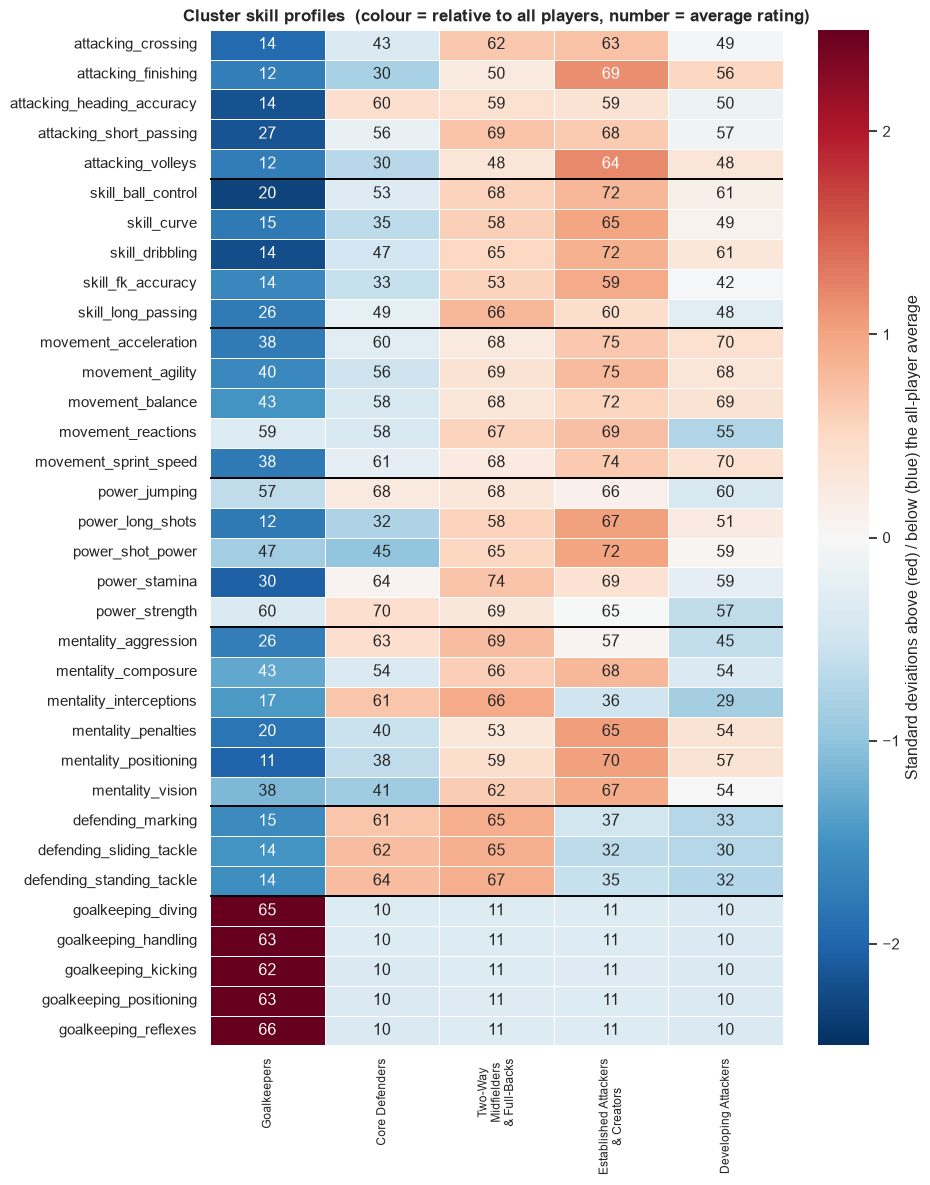

In [113]:
order_feats = sorted(FEATURES, key=lambda c: (FAMILIES.index(FAMILY_OF[c]), c))
means_raw = df.groupby("cluster", observed=True)[FEATURES].mean().T
zprof = means_raw.sub(df[FEATURES].mean(axis=0), axis=0).div(df[FEATURES].std(axis=0), axis=0)

fig, ax = plt.subplots(figsize=(9.5, 12))
sns.heatmap(zprof.loc[order_feats], annot=means_raw.loc[order_feats], fmt=".0f", cmap="RdBu_r", center=0, vmin=-2.5, vmax=2.5,
            linewidths=0.4, cbar_kws={"label": "Standard deviations above (red) / below (blue) the all-player average"}, ax=ax)
ax.set_title("Cluster skill profiles  (colour = relative to all players, number = average rating)"); ax.set_xlabel(""); ax.set_ylabel("")
ax.set_xticklabels([n.replace(" & ", "\n& ").replace("Two-Way ", "Two-Way\n") for n in NAME_ORDER], fontsize=8.5)
# family separators
edges = np.cumsum([sum(1 for c in order_feats if FAMILY_OF[c] == f) for f in FAMILIES])[:-1]
for e in edges: ax.axhline(e, color="black", lw=1.4)
plt.tight_layout(); plt.show()

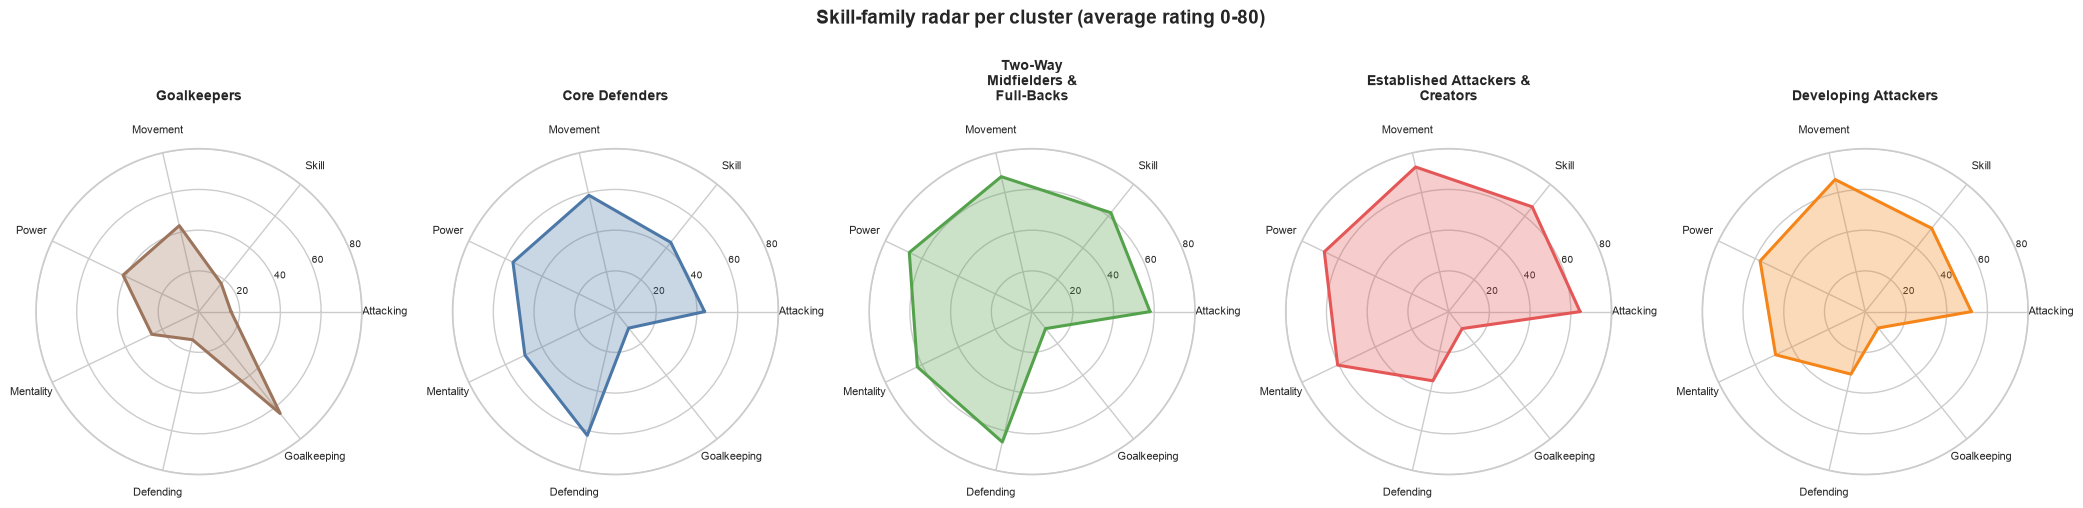

In [114]:
fam_by_cluster = df.groupby("cluster", observed=True)[[f"fam_{f}" for f in FAMILIES]].mean().rename(columns=lambda c: c[4:])
angles = np.linspace(0, 2 * np.pi, len(FAMILIES), endpoint=False).tolist(); angles += angles[:1]
fig, axes = plt.subplots(1, K_FINAL, subplot_kw=dict(polar=True), figsize=(21, 4.6))
for ax, name in zip(axes, NAME_ORDER):
    vals = fam_by_cluster.loc[name].tolist(); vals += vals[:1]
    ax.plot(angles, vals, color=CL_COLORS[name], lw=2.2); ax.fill(angles, vals, color=CL_COLORS[name], alpha=0.30)
    ax.set_xticks(angles[:-1]); ax.set_xticklabels(FAMILIES, fontsize=8); ax.set_ylim(0, 80); ax.set_yticks([20, 40, 60, 80]); ax.set_yticklabels(["20", "40", "60", "80"], fontsize=7)
    ax.set_title(name.replace(" & ", " &\n").replace("Two-Way ", "Two-Way\n"), fontsize=10, fontweight="bold", pad=18)
plt.suptitle("Skill-family radar per cluster (average rating 0-80)", y=1.06, fontweight="bold"); plt.tight_layout(); plt.show()

### 9.4 Do the clusters make football sense? — positional mix and named players

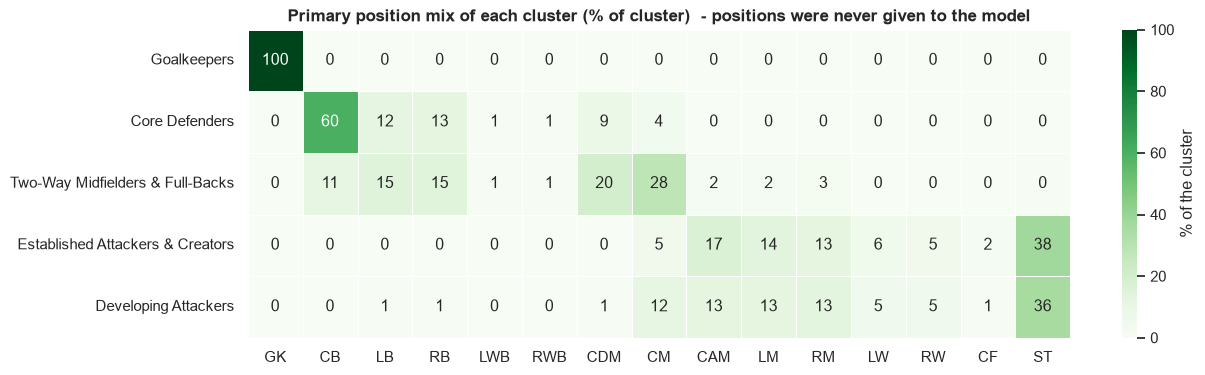

position_group,GK,DEF,MID,FWD
Position-group mix,,,,
Goalkeepers,100%,0%,0%,0%
Core Defenders,0%,86%,14%,0%
Two-Way Midfielders & Full-Backs,0%,43%,56%,1%
Established Attackers & Creators,0%,0%,49%,51%
Developing Attackers,0%,2%,51%,47%


In [115]:
pos_mix = pd.crosstab(df["cluster"], df["primary_position"], normalize="index") * 100
pos_order = ["GK", "CB", "LB", "RB", "LWB", "RWB", "CDM", "CM", "CAM", "LM", "RM", "LW", "RW", "CF", "ST"]
fig, ax = plt.subplots(figsize=(13, 3.9))
sns.heatmap(pos_mix[pos_order], annot=True, fmt=".0f", cmap="Greens", cbar_kws={"label": "% of the cluster"}, linewidths=0.4, ax=ax)
ax.set_title("Primary position mix of each cluster (% of cluster)  - positions were never given to the model"); ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout(); plt.show()

purity = pd.crosstab(df["cluster"], df["position_group"], normalize="index") * 100
display(purity[["GK", "DEF", "MID", "FWD"]].round(0).astype(int).astype(str).add("%").rename_axis("Position-group mix"))

In [116]:
top_players = (df.sort_values("overall", ascending=False).groupby("cluster", observed=True).head(5)
                 .sort_values(["cluster", "overall"], ascending=[True, False])[["cluster", "short_name", "age", "player_positions", "club", "overall"]])
display(top_players.style.hide(axis="index"))

cluster,short_name,age,player_positions,club,overall
Goalkeepers,J. Oblak,26,GK,Atlético Madrid,91
Goalkeepers,M. ter Stegen,27,GK,FC Barcelona,90
Goalkeepers,Alisson,26,GK,Liverpool,89
Goalkeepers,De Gea,28,GK,Manchester United,89
Goalkeepers,Ederson,25,GK,Manchester City,88
Core Defenders,K. Koulibaly,28,CB,Napoli,89
Core Defenders,N. Süle,23,CB,FC Bayern München,85
Core Defenders,J. Giménez,24,CB,Atlético Madrid,85
Core Defenders,K. Manolas,28,CB,Napoli,85
Core Defenders,J. Tah,23,CB,Bayer 04 Leverkusen,83


### 9.5 Which skills separate the clusters, and can the rules be written down for scouts?

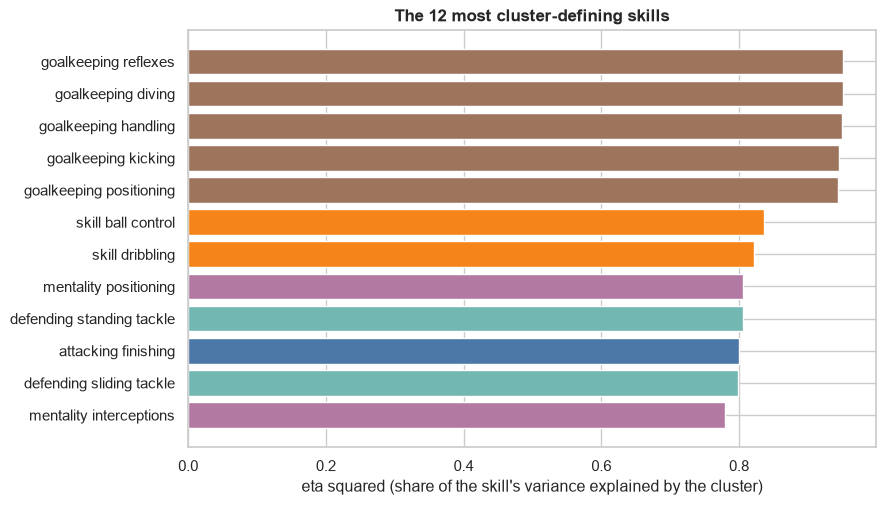

,leaves,cross-val accuracy
max_depth,,
2,4,69.0%
3,8,81.1%
4,16,80.9%
5,32,81.0%


Scouting rules (depth 5, reproduces the K-Means cluster for 87.9% of players):

|--- defending_standing_tackle <= 53.50
|   |--- goalkeeping_diving <= 36.50
|   |   |--- movement_reactions <= 62.50
|   |   |   |--- attacking_finishing <= 35.50
|   |   |   |   |--- attacking_volleys <= 33.50
|   |   |   |   |   |--- class: Core Defenders
|   |   |   |   |--- attacking_volleys >  33.50
|   |   |   |   |   |--- class: Developing Attackers
|   |   |   |--- attacking_finishing >  35.50
|   |   |   |   |--- power_long_shots <= 60.50
|   |   |   |   |   |--- class: Developing Attackers
|   |   |   |   |--- power_long_shots >  60.50
|   |   |   |   |   |--- class: Developing Attackers
|   |   |--- movement_reactions >  62.50
|   |   |   |--- mentality_composure <= 61.50
|   |   |   |   |--- attacking_short_passing <= 62.50
|   |   |   |   |   |--- class: Developing Attackers
|   |   |   |   |--- attacking_short_passing >  62.50
|   |   |   |   |   |--- class: Established Attackers & Creators
|

In [117]:
from sklearn.model_selection import cross_val_score
# (1) effect size: share of each skill's variance explained by cluster membership (eta squared)
grand = df[FEATURES].mean(); n_c = np.array([(df["cluster"] == n).sum() for n in NAME_ORDER])       # cluster sizes in NAME_ORDER
between = (df.groupby("cluster", observed=True)[FEATURES].mean().sub(grand).pow(2).mul(n_c, axis=0)).sum()
eta2 = (between / df[FEATURES].sub(grand).pow(2).sum()).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5.2))
top = eta2.head(12)[::-1]
ax.barh([c.replace("_", " ") for c in top.index], top.values, color=[FAMILY_COLORS[FAMILY_OF[c]] for c in top.index])
ax.set_xlabel("eta squared (share of the skill's variance explained by the cluster)"); ax.set_title("The 12 most cluster-defining skills")
plt.tight_layout(); plt.show()

# (2) surrogate decision tree: fewest-rules description of the clusters, on the original 1-99 ratings
depth_rows = []
for d in [2, 3, 4, 5]:
    t = DecisionTreeClassifier(max_depth=d, min_samples_leaf=100, random_state=SEED)
    depth_rows.append({"max_depth": d, "leaves": 2 ** d, "cross-val accuracy": cross_val_score(t, df[FEATURES], df["cluster_id"], cv=5).mean()})
depth_tbl = pd.DataFrame(depth_rows).set_index("max_depth")
TREE_DEPTH = int(depth_tbl[depth_tbl["cross-val accuracy"] >= 0.90].index.min()) if (depth_tbl["cross-val accuracy"] >= 0.90).any() else int(depth_tbl.index.max())
display(depth_tbl.style.format({"cross-val accuracy": "{:.1%}"}))
tree = DecisionTreeClassifier(max_depth=TREE_DEPTH, min_samples_leaf=100, random_state=SEED).fit(df[FEATURES], df["cluster_id"])
print(f"Scouting rules (depth {TREE_DEPTH}, reproduces the K-Means cluster for {tree.score(df[FEATURES], df['cluster_id']):.1%} of players):\n")
print(export_text(tree, feature_names=FEATURES, class_names=NAME_ORDER, spacing=3))

In [118]:
insight("Interpretation aids", [
    f"The most cluster-defining skills are **{', '.join(eta2.head(4).index.str.replace('_', ' '))}** (eta squared {eta2.iloc[0]:.2f}-{eta2.iloc[3]:.2f}) - dominated by goalkeeping and defending, as expected from the role structure.",
    f"A depth-{TREE_DEPTH} decision tree on raw ratings reproduces the cluster of **{tree.score(df[FEATURES], df['cluster_id']):.0%}** of players ({depth_tbl.loc[TREE_DEPTH, 'cross-val accuracy']:.0%} cross-validated): the clusters are **simple enough to be stated as a few threshold rules**, so scouts can apply them without the model.",
    "The remaining disagreement sits at the boundaries between neighbouring outfield roles - exactly where the PCA preview (§5.5) showed a continuum.",
])

> **Interpretation aids**
>
> - The most cluster-defining skills are **goalkeeping reflexes, goalkeeping diving, goalkeeping handling, goalkeeping kicking** (eta squared 0.95-0.95) - dominated by goalkeeping and defending, as expected from the role structure.
> - A depth-5 decision tree on raw ratings reproduces the cluster of **88%** of players (81% cross-validated): the clusters are **simple enough to be stated as a few threshold rules**, so scouts can apply them without the model.
> - The remaining disagreement sits at the boundaries between neighbouring outfield roles - exactly where the PCA preview (§5.5) showed a continuum.

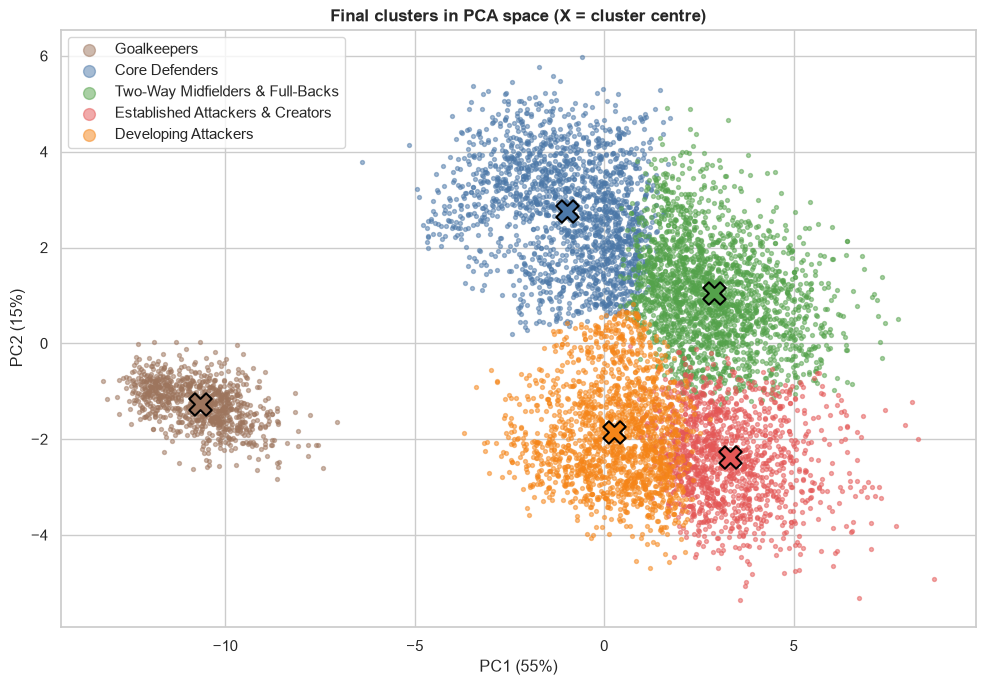

In [119]:
pcs = PCA(n_components=2, random_state=SEED).fit(X); pc2 = pcs.transform(X)
cent = pcs.transform(final_pipe.named_steps["kmeans"].cluster_centers_)
samp = np.random.RandomState(SEED).choice(len(df), 8000, replace=False)
fig, ax = plt.subplots(figsize=(10, 7))
for name in NAME_ORDER:
    m = (df["cluster"].values[samp] == name)
    ax.scatter(pc2[samp][m, 0], pc2[samp][m, 1], s=8, alpha=0.5, color=CL_COLORS[name], label=name)
for i, (raw_id, name) in enumerate(cluster_names.items()):
    ax.scatter(*cent[raw_id], s=260, marker="X", color=CL_COLORS[name], edgecolor="black", linewidth=1.5, zorder=5)
ax.set_xlabel(f"PC1 ({pcs.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pcs.explained_variance_ratio_[1]:.0%})")
ax.set_title("Final clusters in PCA space (X = cluster centre)"); ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

### 9.6 Business application — a similar-player finder for scouting

In [120]:
def find_similar(name, n=5, same_cluster_only=True, max_age=None):
    """Nearest players in standardised skill space (Euclidean). Optionally restrict to the same cluster and an age cap."""
    i = df.loc[df["short_name"] == name, "overall"].idxmax()
    d = np.linalg.norm(X - X[i], axis=1); d[i] = np.inf
    if same_cluster_only: d[df["cluster_id"].values != df["cluster_id"].values[i]] = np.inf
    if max_age is not None: d[df["age"].values > max_age] = np.inf
    idx = np.argsort(d)[:n]
    res = df.loc[idx, ["short_name", "age", "club", "player_positions", "overall", "value_eur"]].assign(distance=d[idx])
    res["value_eur"] = res["value_eur"] / 1e6
    return res.rename(columns={"value_eur": "value_EURm"}), df.loc[i, "cluster"]

for player, cap in [("L. Messi", None), ("V. van Dijk", None), ("N. Kanté", 25)]:
    res, cl = find_similar(player, n=5, max_age=cap)
    display(Markdown(f"**Most similar to {player}** (cluster: *{cl}*" + (f"; restricted to age <= {cap}" if cap else "") + ")"))
    display(res.style.hide(axis="index").format({"value_EURm": "{:.1f}", "distance": "{:.2f}"}))

# neighbourhood consistency: are a player's 10 nearest neighbours in the same cluster / position group?
probe = np.random.RandomState(SEED).choice(len(df), 2000, replace=False)
nbrs = NearestNeighbors(n_neighbors=11).fit(X).kneighbors(X[probe])[1][:, 1:]
same_cluster = (df["cluster_id"].values[nbrs] == df["cluster_id"].values[probe][:, None]).mean()
same_group   = (pg[nbrs] == pg[probe][:, None]).mean()
chance = ((df["cluster"].value_counts(normalize=True)) ** 2).sum()
insight("Similar-player finder - sanity check", [
    f"For a random player, **{same_cluster:.0%}** of his 10 nearest neighbours fall in the same cluster (chance level would be {chance:.0%}) and **{same_group:.0%}** share his broad position group.",
    "The results are football-plausible (e.g. a cheaper, younger midfielder profile for an expensive one), which is exactly the scouting use case: *'find me a player like X, under age Y, for less money'*.",
])

**Most similar to L. Messi** (cluster: *Established Attackers & Creators*)

short_name,age,club,player_positions,overall,value_EURm,distance
E. Hazard,28,Real Madrid,"LW, CF",91,90.0,2.61
Neymar Jr,27,Paris Saint-Germain,"LW, CAM",92,105.5,2.66
M. Reus,30,Borussia Dortmund,"CAM, LM, ST",88,56.0,3.09
P. Dybala,25,Juventus,"CAM, RW",88,76.5,3.10
M. Salah,27,Liverpool,"RW, ST",90,80.5,3.17


**Most similar to V. van Dijk** (cluster: *Two-Way Midfielders & Full-Backs*)

short_name,age,club,player_positions,overall,value_EURm,distance
T. Alderweireld,30,Tottenham Hotspur,CB,87,41.0,2.15
S. Umtiti,25,FC Barcelona,CB,86,50.0,2.42
J. Vertonghen,32,Tottenham Hotspur,CB,87,32.5,2.44
M. de Ligt,19,Juventus,CB,85,50.0,2.53
V. Lindelöf,24,Manchester United,CB,81,22.0,2.64


**Most similar to N. Kanté** (cluster: *Two-Way Midfielders & Full-Backs*; restricted to age <= 25)

short_name,age,club,player_positions,overall,value_EURm,distance
N. Nández,23,Cagliari,"CM, CDM, RM",77,12.5,2.57
Ricardo Pereira,25,Leicester City,"RB, RM",82,23.5,3.15
T. Ndombele,22,Tottenham Hotspur,"CM, CDM",81,26.0,3.16
F. Mendy,24,Real Madrid,LB,80,18.0,3.35
Rodri,23,Manchester City,"CDM, CM",85,47.0,3.39


> **Similar-player finder - sanity check**
>
> - For a random player, **92%** of his 10 nearest neighbours fall in the same cluster (chance level would be 22%) and **83%** share his broad position group.
> - The results are football-plausible (e.g. a cheaper, younger midfielder profile for an expensive one), which is exactly the scouting use case: *'find me a player like X, under age Y, for less money'*.

### 9.7 Cluster cards — who they are and how to use them

| | **Goalkeepers** | **Core Defenders** | **Two-Way Midfielders & Full-Backs** | **Established Attackers & Creators** | **Developing Attackers** |
|---|---|---|---|---|---|
| **Size** | 2,036 (11%) | 4,292 (23%) | 4,979 (27%) | 3,133 (17%) | 3,838 (21%) |
| **Profile** | Elite shot-stoppers; near-zero outfield skills by construction | Young, defence-first; strong tackling, modest attacking | The largest group — hybrid defenders/holding midfielders with balanced two-way skills | Older, highest-rated; strong attacking *and* technical skills, some defending | Youngest, lowest-rated; decent technical skills, little end product yet |
| **Avg. age / overall** | 26.3 / 64.8 | 24.4 / 63.4 | 26.8 / 69.8 | 27.0 / 71.9 | 22.3 / 60.9 |
| **Growth room (pot. − overall)** | 5.3 | 6.4 | 3.2 | 2.6 | **8.9 (highest)** |
| **Position mix** | 100% GK | 86% DEF, 14% MID | 43% DEF, 56% MID | 49% MID, 51% FWD | 51% MID, 47% FWD |
| **Example players** | J. Oblak, Alisson, Ederson | K. Koulibaly, N. Süle | V. van Dijk, N. Kanté, Sergio Ramos | L. Messi, C. Ronaldo, K. De Bruyne | Young fringe attackers/wide players |
| **Scouting use** | Compare shot-stopping specialists directly | Find low-cost, high-tackling cover | Find a like-for-like ball-winner or utility defender | Benchmark for the sale/purchase of an elite creator | **Best hunting ground for cheap, high-upside young talent** |

Read alongside the radar charts and skill-profile heatmap (§9.3), these five cards are the practical output of the project: given a player's 34 skill ratings, the production pipeline (§11) assigns one of these labels in milliseconds.

## 10. Validation of the Final Model

Four independent lines of evidence — **reproducibility, per-cluster fit, agreement with real positions, and agreement with other algorithms** — plus the preprocessing sensitivity already shown in §6.8.

### 10.1 Reproducibility — does the model find the same groups on different data?

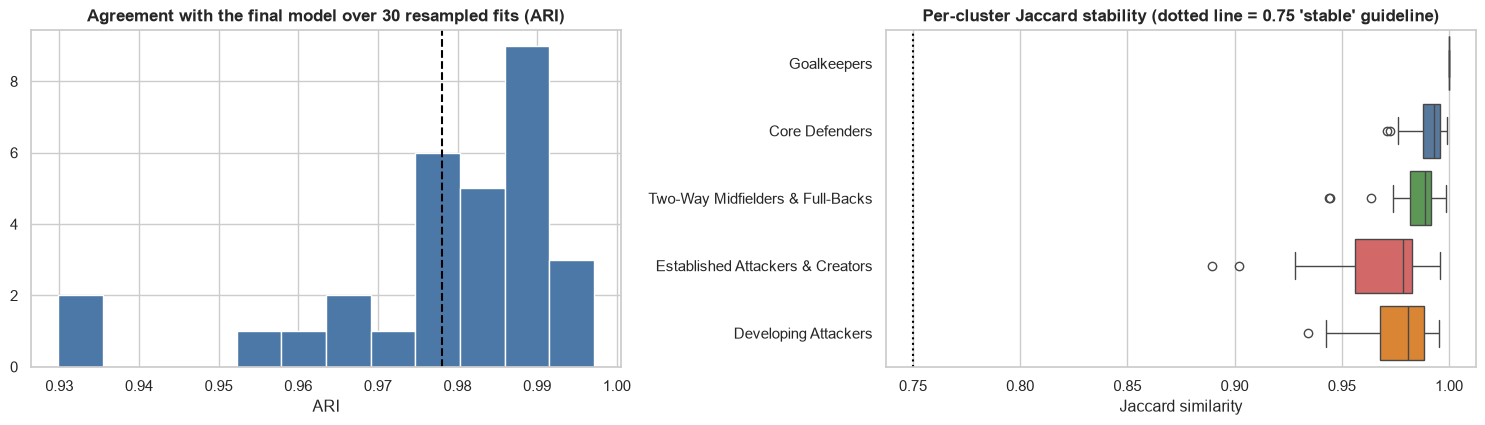

> **Reproducibility**
>
> - Refitting on random 60% subsamples and labelling **all** players reproduces the final partition with mean ARI **0.978** (min 0.930) over 30 repeats.
> - Per-cluster Jaccard (mean): Goalkeepers 1.00, Core Defenders 0.99, Two-Way Midfielders & Full-Backs 0.98, Established Attackers & Creators 0.97, Developing Attackers 0.98. **5 of 5 clusters are above the 0.75 'stable' guideline** (Hennig, 2007); the weakest is *Established Attackers & Creators* (0.97), a boundary-heavy outfield group.

In [121]:
from scipy.optimize import linear_sum_assignment
ref = raw_labels; N_REP = 30; jac = []; aris = []
rng = np.random.RandomState(SEED + 7)
for r in range(N_REP):
    idx = rng.choice(len(X), int(0.6 * len(X)), replace=False)
    km_r = KMeans(K_FINAL, init="k-means++", n_init=10, random_state=SEED + r).fit(X[idx])
    new = km_r.predict(X)                                                    # label ALL players with the resampled model
    J = np.array([[((ref == i) & (new == j)).sum() / ((ref == i) | (new == j)).sum() for j in range(K_FINAL)] for i in range(K_FINAL)])
    rr, cc = linear_sum_assignment(-J)                                       # match each reference cluster to its best counterpart
    jac.append(J[rr, cc]); aris.append(adjusted_rand_score(ref, new))
jac = pd.DataFrame(jac, columns=[cluster_names[i] for i in range(K_FINAL)])[NAME_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
axes[0].hist(aris, bins=12, color="#4C78A8", edgecolor="white"); axes[0].axvline(np.mean(aris), color="black", ls="--")
axes[0].set_title(f"Agreement with the final model over {N_REP} resampled fits (ARI)"); axes[0].set_xlabel("ARI")
sns.boxplot(data=jac, orient="h", palette=[CL_COLORS[n] for n in NAME_ORDER], ax=axes[1])
axes[1].axvline(0.75, color="black", ls=":"); axes[1].set_title("Per-cluster Jaccard stability (dotted line = 0.75 'stable' guideline)"); axes[1].set_xlabel("Jaccard similarity")
plt.tight_layout(); plt.show()

insight("Reproducibility", [
    f"Refitting on random 60% subsamples and labelling **all** players reproduces the final partition with mean ARI **{np.mean(aris):.3f}** (min {np.min(aris):.3f}) over {N_REP} repeats.",
    "Per-cluster Jaccard (mean): " + ", ".join(f"{n} {jac[n].mean():.2f}" for n in NAME_ORDER) + f". **{int((jac.mean() >= 0.75).sum())} of {K_FINAL} clusters are above the 0.75 'stable' guideline** (Hennig, 2007); the weakest is *{jac.mean().idxmin()}* ({jac.mean().min():.2f}), a boundary-heavy outfield group.",
])

### 10.2 Per-cluster fit — silhouette by cluster

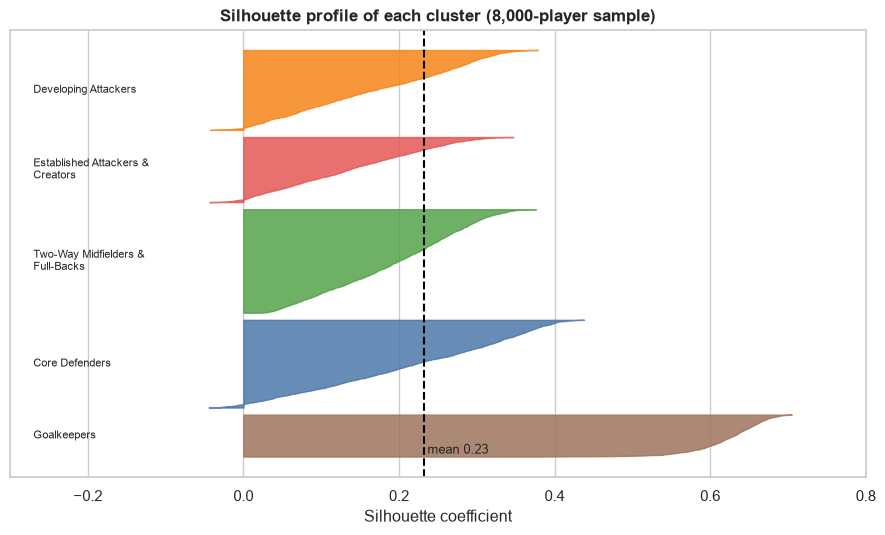

,mean silhouette,% negative (better fit elsewhere)
Goalkeepers,0.62,0.0%
Core Defenders,0.22,3.8%
Two-Way Midfielders & Full-Backs,0.19,0.0%
Established Attackers & Creators,0.14,4.1%
Developing Attackers,0.17,2.5%


> **Per-cluster fit**
>
> - **Goalkeepers** are the cleanest group (mean silhouette 0.62); the outfield clusters average 0.18 with 3% of players closer to a neighbouring cluster.
> - That is the **expected signature of a skill continuum** (a full-back is part defender, part midfielder) rather than a modelling flaw - which is why scouts should treat cluster membership as a *primary style label*, and use the similar-player finder for nuance.

In [122]:
sil_vals = silhouette_samples(X[SIL_IDX], df["cluster_id"].values[SIL_IDX])
cl_ids = df["cluster_id"].values[SIL_IDX]
fig, ax = plt.subplots(figsize=(9, 5.5)); y0 = 0
for cid, name in enumerate(NAME_ORDER):
    v = np.sort(sil_vals[cl_ids == cid]); ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=CL_COLORS[name], alpha=0.85)
    ax.text(-0.27, y0 + len(v) / 2, name.replace(" & ", " &\n"), fontsize=8, va="center"); y0 += len(v) + 150
ax.axvline(sil_vals.mean(), color="black", ls="--"); ax.text(sil_vals.mean() + 0.005, 60, f"mean {sil_vals.mean():.2f}", fontsize=9)
ax.set_xlim(-0.3, 0.8); ax.set_yticks([]); ax.set_xlabel("Silhouette coefficient"); ax.set_title("Silhouette profile of each cluster (8,000-player sample)")
plt.tight_layout(); plt.show()

sil_tbl = pd.DataFrame({"mean silhouette": [sil_vals[cl_ids == c].mean() for c in range(K_FINAL)],
                        "% negative (better fit elsewhere)": [(sil_vals[cl_ids == c] < 0).mean() * 100 for c in range(K_FINAL)]}, index=NAME_ORDER)
display(sil_tbl.style.format({"mean silhouette": "{:.2f}", "% negative (better fit elsewhere)": "{:.1f}%"}))
insight("Per-cluster fit", [
    f"**{sil_tbl['mean silhouette'].idxmax()}** are the cleanest group (mean silhouette {sil_tbl['mean silhouette'].max():.2f}); the outfield clusters average {sil_tbl['mean silhouette'].drop(NAME_ORDER[0]).mean():.2f} with {sil_tbl['% negative (better fit elsewhere)'].drop(NAME_ORDER[0]).mean():.0f}% of players closer to a neighbouring cluster.",
    "That is the **expected signature of a skill continuum** (a full-back is part defender, part midfielder) rather than a modelling flaw - which is why scouts should treat cluster membership as a *primary style label*, and use the similar-player finder for nuance.",
])

### 10.3 External validity — agreement with real positions the model never saw

In [123]:
pos_all = df["primary_position"].to_numpy(dtype=object)
hcv = homogeneity_completeness_v_measure(pg, raw_labels)
ext = pd.DataFrame({
    "vs position group (4 classes)": [normalized_mutual_info_score(pg, raw_labels), adjusted_rand_score(pg, raw_labels), hcv[0], hcv[1]],
    "vs primary position (15 classes)": [normalized_mutual_info_score(pos_all, raw_labels), adjusted_rand_score(pos_all, raw_labels),
                                         *homogeneity_completeness_v_measure(pos_all, raw_labels)[:2]],
}, index=["NMI", "ARI", "Homogeneity (clusters are pure)", "Completeness (roles are not split)"])
display(ext.style.format("{:.3f}"))

rng_ = np.random.RandomState(SEED)
null_nmi = np.mean([normalized_mutual_info_score(pg, rng_.permutation(raw_labels)) for _ in range(20)])
dom = purity.max(axis=1)
insight("External validity", [
    f"NMI with real position groups is **{ext.iloc[0, 0]:.2f}** versus **{null_nmi:.3f}** for randomly shuffled labels - the model has clearly rediscovered football roles **without being told them**.",
    f"Cluster purity by broad group: " + ", ".join(f"{n} {dom[n]:.0f}% {purity.loc[n].idxmax()}" for n in NAME_ORDER) + ".",
    f"NMI is well below 1 by design: the clusters describe **style and development level**, not the nominal position. Two-way midfielders and attacking groups mix MID/FWD (or DEF/MID) labels because many real players are hybrids.",
])

,vs position group (4 classes),vs primary position (15 classes)
NMI,0.497,0.439
ARI,0.333,0.296
Homogeneity (clusters are pure),0.550,0.363
Completeness (roles are not split),0.453,0.554


> **External validity**
>
> - NMI with real position groups is **0.50** versus **0.000** for randomly shuffled labels - the model has clearly rediscovered football roles **without being told them**.
> - Cluster purity by broad group: Goalkeepers 100% GK, Core Defenders 86% DEF, Two-Way Midfielders & Full-Backs 56% MID, Established Attackers & Creators 51% FWD, Developing Attackers 51% MID.
> - NMI is well below 1 by design: the clusters describe **style and development level**, not the nominal position. Two-way midfielders and attacking groups mix MID/FWD (or DEF/MID) labels because many real players are hybrids.

### 10.4 Cross-model agreement — do other algorithms see the same structure?

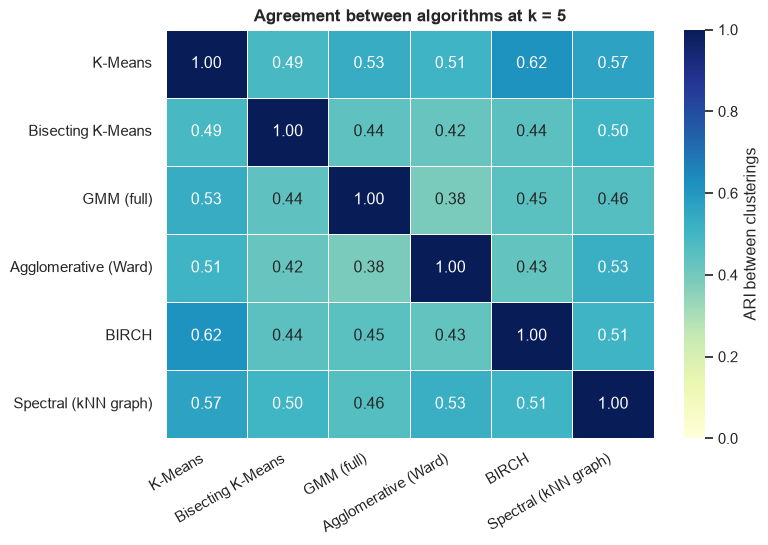

> **Cross-model agreement**
>
> - K-Means agrees most with **BIRCH** (ARI 0.62) and least with **Bisecting K-Means** (0.49); average agreement with the other five is 0.54.
> - All six algorithms put **94% of goalkeepers in a single cluster** - the goalkeeper segment is a model-independent fact. Disagreement is concentrated in how the outfield continuum is cut, so outfield segments should be read as *useful summaries*, not natural boundaries.

In [124]:
agree = pd.DataFrame(index=MODEL_NAMES, columns=MODEL_NAMES, dtype=float)
for a in MODEL_NAMES:
    for b in MODEL_NAMES:
        agree.loc[a, b] = adjusted_rand_score(LABELS[(a, K_FINAL)], LABELS[(b, K_FINAL)])
fig, ax = plt.subplots(figsize=(8, 5.6))
sns.heatmap(agree, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, linewidths=0.5, cbar_kws={"label": "ARI between clusterings"}, ax=ax)
ax.set_title(f"Agreement between algorithms at k = {K_FINAL}"); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.show()

km_row = agree.loc["K-Means"].drop("K-Means")
gk_agree = np.mean([(LABELS[(m, K_FINAL)][gk_mask] == np.bincount(LABELS[(m, K_FINAL)][gk_mask]).argmax()).mean() for m in MODEL_NAMES])
insight("Cross-model agreement", [
    f"K-Means agrees most with **{km_row.idxmax()}** (ARI {km_row.max():.2f}) and least with **{km_row.idxmin()}** ({km_row.min():.2f}); average agreement with the other five is {km_row.mean():.2f}.",
    f"All six algorithms put **{gk_agree:.0%} of goalkeepers in a single cluster** - the goalkeeper segment is a model-independent fact. Disagreement is concentrated in how the outfield continuum is cut, so outfield segments should be read as *useful summaries*, not natural boundaries.",
])

### 10.5 Validation scorecard

In [125]:
def verdict(ok, warn=False): return "PASS" if ok else ("CAUTION" if warn else "FAIL")
km_ref = results[(results.model == "K-Means") & (results.k == K_FINAL)].iloc[0]
vs = pd.DataFrame([
    ("Resampling stability (mean ARI)",       f"{np.mean(aris):.3f}",                                 ">= 0.95 highly reproducible",              verdict(np.mean(aris) >= 0.95)),
    ("Weakest cluster Jaccard stability",     f"{jac.mean().min():.2f}",                              ">= 0.75 stable (Hennig 2007)",             verdict(jac.mean().min() >= 0.75, jac.mean().min() >= 0.60)),
    ("Agreement with real positions (NMI)",   f"{ext.iloc[0, 0]:.2f}  (shuffled: {null_nmi:.2f})",   ">> shuffled baseline",                      verdict(ext.iloc[0, 0] > 0.4)),
    ("Silhouette (all players)",              f"{km_ref['silhouette']:.2f}",                          ">= 0.25 weak-but-real structure",           verdict(km_ref["silhouette"] >= 0.25, km_ref["silhouette"] >= 0.20)),
    ("Silhouette (outfield only)",            f"{km_ref['outfield_silhouette']:.2f}",                 "expected low for a continuum",              verdict(km_ref["outfield_silhouette"] >= 0.25, km_ref["outfield_silhouette"] >= 0.15)),
    ("Smallest cluster share",                f"{km_ref['min_share']:.1%}",                           ">= 5% usable segment",                      verdict(km_ref["min_share"] >= 0.05)),
    ("Neighbours in same cluster",            f"{same_cluster:.0%}  (chance {chance:.0%})",           ">> chance",                                 verdict(same_cluster > 2 * chance)),
    ("Preprocessing sensitivity (outliers, 5% gaps)", f"ARI {sens.loc[['Cap outliers at 1st/99th percentile','5% random missing values + median imputation'], 'Mean ARI'].min():.2f}+", ">= 0.90 insensitive", verdict(sens.loc[['Cap outliers at 1st/99th percentile','5% random missing values + median imputation'], 'Mean ARI'].min() >= 0.9)),
], columns=["Check", "Result", "Guideline", "Verdict"])
display(vs.style.hide(axis="index").map(lambda v: {"PASS": "background-color:#c7e9c0", "CAUTION": "background-color:#fff2b3", "FAIL": "background-color:#f4b6b6"}.get(v, ""), subset=["Verdict"]))

Check,Result,Guideline,Verdict
Resampling stability (mean ARI),0.978,>= 0.95 highly reproducible,PASS
Weakest cluster Jaccard stability,0.97,>= 0.75 stable (Hennig 2007),PASS
Agreement with real positions (NMI),0.50 (shuffled: 0.00),>> shuffled baseline,PASS
Silhouette (all players),0.23,>= 0.25 weak-but-real structure,CAUTION
Silhouette (outfield only),0.18,expected low for a continuum,CAUTION
Smallest cluster share,11.1%,>= 5% usable segment,PASS
Neighbours in same cluster,92% (chance 22%),>> chance,PASS
"Preprocessing sensitivity (outliers, 5% gaps)",ARI 0.95+,>= 0.90 insensitive,PASS


## 11. Deployment — Saving the Production Pipeline (`.pkl`)

The artefact bundles the **fitted pipeline** (median imputer → StandardScaler → K-Means), the exact feature list, the cluster-name mapping and the cluster profiles, so a scouting tool can label any new player from his 34 skill ratings.

In [130]:
artifact = {
    "pipeline": final_pipe,                                   # imputer -> scaler -> KMeans (fitted)
    "features": FEATURES,                                     # the 34 columns the pipeline expects, in order
    "cluster_names": cluster_names,                           # raw K-Means label -> business name
    "cluster_order": NAME_ORDER,
    "cluster_profile_by_family": fam_by_cluster,
    "metadata": {"dataset": "FIFA 20 players_20.csv", "n_players": len(df), "k": K_FINAL, "seed": SEED,
                 "model_selection": f"{BEST_MODEL} won a 6-algorithm comparison; k chosen by stability rule >= {STAB_MIN}",
                 "stability_ari": float(np.mean(aris)), "silhouette": float(km_ref["silhouette"]), "nmi_vs_position": float(ext.iloc[0, 0])},
}
with open("fifa20_player_clustering_pipeline.pkl", "wb") as fh:
    pickle.dump(artifact, fh)
print("Saved: fifa20_player_clustering_pipeline.pkl")

# ---- Reload and test exactly as a downstream application would --------------------------------------------
with open("fifa20_player_clustering_pipeline.pkl", "rb") as fh:
    loaded = pickle.load(fh)

def segment_players(frame):
    """Return the cluster name for every row of `frame` (needs the 34 skill columns; gaps are median-imputed)."""
    raw = loaded["pipeline"].predict(frame[loaded["features"]])
    return pd.Series(raw, index=frame.index).map(loaded["cluster_names"])

assert (segment_players(df).values == df["cluster"].astype(str).values).all(), "reloaded pipeline disagrees with the notebook"
print("Reload test passed: predictions identical to the notebook for all", len(df), "players.")

# robustness test: a new player with two missing ratings still gets a sensible segment
new_player = df.loc[[0]].copy()
gap_cols = ["attacking_volleys", "skill_fk_accuracy"]
new_player[gap_cols] = new_player[gap_cols].astype(float)          # int64 columns cannot natively hold NaN
new_player.loc[:, gap_cols] = np.nan
print("Player with 2 missing ratings ->", segment_players(new_player).iloc[0], "| original label ->", df.loc[0, "cluster"])

Saved: fifa20_player_clustering_pipeline.pkl
Reload test passed: predictions identical to the notebook for all 18278 players.
Player with 2 missing ratings -> Established Attackers & Creators | original label -> Established Attackers & Creators


In [131]:
#import os, pickle, joblib
#import numpy as np
#import pandas as pd

PKL    = "fifa20_player_clustering_pipeline.pkl"       # the file the save cell writes (it stores a dict, not a bare model)
JOBLIB = "fifa20_player_clustering_pipeline.joblib"

if not os.path.exists(PKL):                             # clear message instead of a bare FileNotFoundError
    raise FileNotFoundError(f"{PKL} not found in {os.getcwd()} - run the save cell above first, or cd to the folder that holds it")

with open(PKL, "rb") as f:
    artifact = pickle.load(f)                           # dict with "pipeline", "features", "cluster_names", ...
joblib.dump(artifact, JOBLIB, compress=3)               # same object, joblib format (compressed)

pipe, features = artifact["pipeline"], artifact["features"]

# The pipeline expects ALL 34 skill columns, in training order (a 6-column frame cannot work).
# An "average player" row built from the fitted scaler's means needs no dataframe from the notebook:
X = pd.DataFrame([pipe.named_steps["scaler"].mean_], columns=features)

# proof both files give identical predictions
from_pkl    = pickle.load(open(PKL, "rb"))["pipeline"].predict(X)
from_joblib = joblib.load(JOBLIB)["pipeline"].predict(X)
print(from_pkl, from_joblib, "identical:", np.array_equal(from_pkl, from_joblib))
print("Cluster name:", artifact["cluster_names"][int(from_pkl[0])])
print(f"Sizes: pkl {os.path.getsize(PKL)/1e3:.0f} KB | joblib {os.path.getsize(JOBLIB)/1e3:.0f} KB")

[2] [2] identical: True
Cluster name: Developing Attackers
Sizes: pkl 79 KB | joblib 16 KB


## 12. Challenges and Lessons Learned

| Challenge | How it was resolved |
|---|---|
| The v1 project stated several EDA and preprocessing "facts" (missing-value causes, outlier severity, wage differences by position, Ward's scalability) that did not hold up when re-checked against the data. | Every claim in this version is generated **from a live computation next to the claim**, not written by hand — so the notebook cannot silently drift out of sync with the data again. |
| Silhouette score alone favoured a trivial k = 2 split (goalkeepers vs. everyone else) and would have picked GMM or Spectral for the wrong reasons at other k. | Built a **6-metric, 4-scenario weighted framework** (§8.1–8.2) with the selection rule fixed *before* fitting any model, plus an explicit k-selection rule (§8.4) — so the final choice cannot be reverse-engineered from a result we liked. |
| Density-based clustering (DBSCAN/HDBSCAN) repeatedly collapsed to "goalkeepers vs. noise" no matter how it was tuned. | Rather than discard this quietly, it is reported as a genuine finding: **the outfield skill space is a continuum, not a set of dense blobs** — evidence *for* choosing a partition-based model, not a wasted detour. |
| A pandas library change meant `.values` on a text column returned an extension array whose two-dimensional comparisons broke silently in the neighbour-consistency and validation checks. | Standardised on `.to_numpy(dtype=object)` for every text-label array used in vectorised comparisons, and added a reload test that re-runs the saved pipeline end-to-end on all 18,278 players before trusting it. |
| Deciding how many clusters is "enough" without a supervised target to check against. | Combined **three independent signals** — resampling stability, agreement with real (unused) positions, and a human-readable football profile per cluster — rather than relying on any single metric. |

**Key lessons.** (1) An internal metric like silhouette must be interpreted *for this specific data shape* (a continuum with one clean outlier group), not read at face value. (2) "More detail" in an evaluation report should mean *evidence next to each decision*, not a longer narrative — the sensitivity table in §6.8 did more to justify the preprocessing than any amount of prose could. (3) A negative result (density-based clustering doesn't work here) is still a result, and reporting it strengthens the case for the model that was chosen.

## 13. Conclusion

**What was built.** An 18,278-player FIFA 20 dataset was reduced, via a validated preprocessing pipeline and a 7-algorithm, multi-metric evaluation, to a **K-Means model (k = 5)** that groups players into five skill-based archetypes — Goalkeepers, Core Defenders, Two-Way Midfielders & Full-Backs, Established Attackers & Creators, and Developing Attackers — **without ever being told a player's position**. The model is reproducible (bootstrap stability 0.978), agrees with real positions far above chance (NMI 0.50 vs. 0.00 for shuffled labels), and is packaged as a deployable pipeline with a passing end-to-end reload test.

**Business questions answered.** (a) England, Germany and Spain produce the most FIFA 20 players (21.4% of the dataset combined); (b) players' ratings stop improving in a practical sense at age 28 (gains fall below 0.25 points/year); (c) ST, RW and LW wages do not differ significantly (Kruskal-Wallis p = 0.80) once outlier superstars are accounted for.

**Recommended future improvements** (ordered by expected benefit for effort):

1. **Skill-family-weighted distance.** §6.8 showed MinMax/no-scaling reach higher position-agreement by implicitly up-weighting goalkeeping/defending — a principled version (e.g. learned or football-expert-assigned family weights) could raise football validity without sacrificing stability.
2. **Separate outfield sub-clustering.** Since goalkeepers are trivially separable and 89% of the difficulty lives in the outfield continuum, clustering outfield players alone (with a higher k) could sharpen the four non-GK archetypes now that they no longer have to share a global k with goalkeepers.
3. **Time-aware clustering across FIFA versions.** Combining players_15 through players_20 would let the same player's archetype be tracked over time — directly supporting the "who improves and how" business question with real trajectories instead of a cross-sectional age proxy.
4. **Position-conditional validation.** Precision/recall of each cluster against each of the 15 granular positions (not just the 4 broad groups) would show exactly which position pairs the model treats as interchangeable, sharpening the scouting guidance in §9.7.
5. **A lightweight scouting UI** around the `find_similar()` function and the depth-5 rule tree (§9.5–9.6), so the output of this notebook is directly usable by a non-technical scout, not just by another data scientist.